<a href="https://colab.research.google.com/github/leonkrizanic/ELM_diplomski/blob/main/ELM_diplomski.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from __future__ import annotations

import time
import warnings
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
import numpy as np
import scipy
import pandas as pd
import matplotlib
import seaborn as sns
import sklearn
import gc

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)

NumPy: 2.4.6
SciPy: 1.16.3
Pandas: 2.2.3
Matplotlib: 3.10.0
Seaborn: 0.13.2
Scikit-learn: 1.6.1


In [ ]:
OUT_DIR = Path("elm_rezultati")
OUT_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 2026
N_MONTE_CARLO = 30
ACTIVATION = "tanh"       # "tanh" ili "sigmoid"
FIT_INTERCEPT = True      # centriranje y (nepenalizirani intercept); False = staro ponašanje
L_GRID = [5*i for i in range(1,100)]
L_MONTE_CARLO = 100
L_INCREMENTAL_MAX = 1000   # 500 je moguće, ali QR putanja i grafici traju dulje
LAMBDA_GRID = np.logspace(-6, 6, 25)
INCREMENTAL_TOL = 0.05    # tolerancija relativnog smanjenja trening RMSE-a; vidi tekst
SYNTHETIC_NOISE_STD = 0.10
TEST_SIZE = 0.20
VALIDATION_SIZE_OF_REMAINDER = 0.25  # 0.25 * 0.80 = 0.20 ukupnog uzorka

$\def\R{\mathbb{R}}\def\Rmat#1#2{\mathbb{R}^{#1 \times #2}}$

# Sažetak: `regression_metrics` i `safe_condition_number`

## 1. `regression_metrics(y_true, y_pred)`

Računa tri standardne regresijske metrike. Ulazi se najprije poravnaju u 1D vektore:
$$
y,\ \hat{y} \in \R^{n}
$$

### RMSE — Root Mean Squared Error

$$
\text{RMSE}(y,\hat{y}) = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(y_i - \hat{y}_i\right)^2}
= \sqrt{\text{MSE}}
$$

Kažnjava velike greške jače od MAE (kvadratna penalizacija); ista jedinica kao $y$.

### MAE — Mean Absolute Error

$$
\text{MAE}(y,\hat{y}) = \frac{1}{n}\sum_{i=1}^{n}\left|y_i - \hat{y}_i\right|
$$

Robusniji na outliere od RMSE; linearna penalizacija.

### $R^2$ — koeficijent determinacije

$$
R^2(y,\hat{y}) = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2},
\qquad \bar{y} = \frac{1}{n}\sum_{i=1}^{n} y_i
$$

- $R^2 = 1$ → savršena predikcija
- $R^2 = 0$ → model jednako dobar kao predikcija sredinom $\bar{y}$
- $R^2 < 0$ → model gorji od trivijalne konstante $\bar{y}$

**Vraća:** rječnik `{"RMSE", "MAE", "R2"}` kao `float`.

---

## 2. `safe_condition_number(A, rtol=None)`

Računa **kondicijski broj** i **numerički rang** matrice $A \in \Rmat{m}{n}$ preko SVD-a, uz sigurno postupanje s deficijentnim matricama.

### SVD

$$
A = U\Sigma V^{T}, \qquad
\Sigma = \operatorname{diag}(\sigma_1, \sigma_2, \dots, \sigma_{\min(m,n)}),
\qquad \sigma_1 \ge \sigma_2 \ge \dots \ge 0
$$

Kod koristi samo singularne vrijednosti: `s = np.linalg.svd(A, compute_uv=False)`.

### Tolerancija za rang

Ako `rtol` nije zadan, postavlja se strojna tolerancija:

$$
\text{rtol} = \max(m,n)\cdot \varepsilon_{\text{mach}},
\qquad \varepsilon_{\text{mach}} \approx 2.22\times 10^{-16}
$$

Numerički rang:

$$
\operatorname{rank}(A) = \#\{\, i : \sigma_i > \text{rtol}\cdot \sigma_1 \,\}
$$

To je broj singularnih vrijednosti koje su **iznad razine šuma** strojne preciznosti.

### Kondicijski broj

$$
\kappa_2(A) = \frac{\sigma_{\max}}{\sigma_{\min}} = \frac{\sigma_1}{\sigma_{\min(m,n)}}
$$

Funkcija ga vraća kao **konačan** samo ako je matrica punog ranga i najmanja singularna vrijednost strogo pozitivna:

$$
\kappa =
\begin{cases}
\dfrac{\sigma_1}{\sigma_{\min(m,n)}}, & \text{ako } \operatorname{rank}(A) = \min(m,n) \ \wedge\ \sigma_{\min(m,n)} > 0 \\[6pt]
+\infty, & \text{inače (deficijentna matrica)}
\end{cases}
$$

### Rubni slučajevi

- Ako $A$ nema singularnih vrijednosti ili je $\sigma_1 = 0$ → vraća $\kappa = \infty$, `rank = 0`.
- Inače vraća trojku $(\kappa, \operatorname{rank}, \sigma)$.

**Vraća:** `(kappa, rank, s)` gdje je `s` vektor svih singularnih vrijednosti.

---

## 3. Zašto je to važno u kontekstu ELM-a

U ELM-u se $\beta$ rješava kao $\beta = H^{+}y$ preko SVD-a. Tada:

- **Rang $H$** pokazuje koliko efektivnih smjerova reprezentacije postoji; nizak rang → model ima manje kapaciteta nego što dimenzije sugeriraju.
- **$\kappa_2(H)$** mjeri osjetljivost rješenja: velik $\kappa$ znači da male promjene u $y$ ili $H$ izazivaju velike promjene u $\beta$ → nestabilne težine i loša generalizacija.
- **RMSE / MAE / $R^2$** su vanjske metrike kvalitete; $\kappa$ i rang su **unutarnja dijagnostika numerike**.

## Ključna poanta

> `regression_metrics` daje standardne mjere točnosti (RMSE, MAE, $R^2$), a `safe_condition_number` preko SVD-a dijagnosticira **numeričku stabilnost** matrice: numerički rang (singularne vrijednosti iznad strojnog šuma) i kondicijski broj $\kappa_2 = \sigma_{\max}/\sigma_{\min}$, uz $\kappa = \infty$ za deficijentne matrice.

In [ ]:
def regression_metrics(y_true, y_pred):
    """Metrike za regresiju; radi i za jednodimenzionalne ciljeve."""
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    return {
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
    }


def safe_condition_number(A, rtol=None):
    """Broj uvjetovanosti po singularnim vrijednostima; inf ako je numerički deficijentan."""
    s = np.linalg.svd(A, compute_uv=False)
    if len(s) == 0 or s[0] == 0:
        return np.inf, 0, s
    if rtol is None:
        rtol = max(A.shape) * np.finfo(float).eps
    rank = int(np.sum(s > rtol * s[0]))
    # κ₂(H) = s_max/s_min; ako je rang deficijentan, κ₂ je beskonačan.
    kappa = float(s[0] / s[-1]) if rank == min(A.shape) and s[-1] > 0 else np.inf
    return kappa, rank, s

In [ ]:
@dataclass
class DataSplit:
    name: str
    X_train: np.ndarray
    X_val: np.ndarray
    X_test: np.ndarray
    y_train: np.ndarray
    y_val: np.ndarray
    y_test: np.ndarray
    feature_scaler: StandardScaler


def make_synthetic_data(n_samples=800, noise_std=SYNTHETIC_NOISE_STD, seed=RANDOM_STATE):
    """Dvodimenzionalna regresija: y = sin(x1) cos(x2) + Gaussov šum."""
    rng = np.random.default_rng(seed)
    X = rng.uniform(-3.0, 3.0, size=(n_samples, 2))
    noise = rng.normal(0.0, noise_std, size=n_samples)
    y = np.sin(X[:, 0]) * np.cos(X[:, 1]) + noise
    return X, y


def make_split(X, y, name, seed=RANDOM_STATE):
    """60/20/20 podjela; scaler se prilagođava samo na train skupu."""
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.40, random_state=seed
    )
    # Od preostalih 40% uzoraka polovica ide u validation, polovica u test.
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, random_state=seed + 1
    )
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_val_s = scaler.transform(X_val)
    X_test_s = scaler.transform(X_test)

    return DataSplit(
        name=name,
        X_train=X_train_s,
        X_val=X_val_s,
        X_test=X_test_s,
        y_train=np.asarray(y_train).reshape(-1, 1),
        y_val=np.asarray(y_val).reshape(-1, 1),
        y_test=np.asarray(y_test).reshape(-1, 1),
        feature_scaler=scaler,
    )


def load_datasets():
    X_syn, y_syn = make_synthetic_data()
    syn = make_split(X_syn, y_syn, "synthetic")

    diabetes = load_diabetes()
    real = make_split(diabetes.data, diabetes.target, "diabetes")
    return {"synthetic": syn, "diabetes": real}

In [ ]:
import pandas as pd
from sklearn.datasets import load_diabetes

# Učitavanje diabetes skupa podataka
diabetes = load_diabetes()

# Spajanje ulaznih značajki i ciljne varijable (target) u pandas DataFrame
df_diabetes = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df_diabetes['target'] = diabetes.target

# Prikaz prvih 5 redaka
print(df_diabetes.head())

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  


$\def\R{\mathbb{R}}\def\Rmat#1#2{\mathbb{R}^{#1 \times #2}}$

# Klasa `ELM` — objašnjenje funkciju po funkciju

Klasa implementira **Extreme Learning Machine**: skriveni sloj $(W, b)$ je slučajan i **fiksan** (ne trenira se), a izlazni sloj $\beta$ rješava se **analitički** (least squares ili ridge). Nema gradijentnog spusta, nema backpropagacije — samo jedan linearni solve.

---

## `__init__(n_hidden=50, activation=ACTIVATION, lam=0.0, random_state=None, fit_intercept=FIT_INTERCEPT)`

Konstruktor postavlja hiperparametre i priprema mjesta za naučene parametre.

### Validacija

- $n_{\text{hidden}} \ge 1$ (inače `ValueError`)
- $\lambda \ge 0$ (inače `ValueError`)

### Hiperparametri

| Parametar | Značenje |
|---|---|
| `n_hidden` $= L$ | broj skrivenih neurona (dimenzija reprezentacije $H$) |
| `activation` $\phi$ | `"tanh"` ili `"sigmoid"` |
| `lam` $= \lambda$ | koeficijent ridge regularizacije; $\lambda = 0$ → obični LS |
| `random_state` | seed za reproducibilnu inicijalizaciju $(W, b)$ |
| `fit_intercept` | ako je `True`, centrira $y$ (vidi `fit`) |

### Atributi koji se postavljaju

- `y_mean` — srednja vrijednost cilja (za "intercept" trik)
- `W`, `b` — težine skrivenog sloja (postavljaju se u `fit`)
- `beta` — izlazne težine
- `H_train` — matrica reprezentacije na trening skupu (za dijagnostiku)
- `t_H`, `t_beta` — vremena računanja

---

## `_activation(Z)`

Primjenjuje aktivacijsku funkciju element-wise.

### tanh

$$
\phi(Z) = \tanh(Z) = \frac{e^{Z} - e^{-Z}}{e^{Z} + e^{-Z}}
$$

### sigmoid (numerički stabilizirana)

$$
\phi(Z) = \frac{1}{1 + e^{-Z}}
$$

Kod **klipira** $Z$ u $[-1000, 1000]$ prije eksponencijale kako bi se izbjegao overflow (`np.exp` velikih brojeva → `inf`). To ne mijenja vrijednost u praksi jer je $\sigma(Z) \approx 0$ za $Z < -1000$ i $\approx 1$ za $Z > 1000$.

Baca `ValueError` za nepoznatu aktivaciju.

---

## `_hidden(X)`

Računa skrivenu reprezentaciju:

$$
H = \phi\left(XW^{T} + b\right)
$$

- $X \in \Rmat{n}{d}$, $W \in \Rmat{L}{d}$ → $XW^{T} \in \Rmat{n}{L}$
- $b \in \R^{L}$ se emitira preko svih $n$ redaka (broadcasting)
- $\phi$ se primjenjuje element-wise

Rezultat: $H \in \Rmat{n}{L}$.

---

## `initialize_hidden_parameters(n_features, seed=None)`

Slučajna inicijalizacija skrivenog sloja.

### Generator

$$
\text{rng} = \texttt{default\_rng}(\text{random\_state} \text{ ili } \text{seed})
$$

### Uniformna inicijalizacija

$$
W_{ij} \sim \mathcal{U}(-1, 1), \quad W \in \Rmat{L}{d}
$$
$$
b_j \sim \mathcal{U}(-1, 1), \quad b \in \R^{L}
$$

Ovo je tipična ELM inicijalizacija — nema Xavier/He skaliranja jer se skriveni sloj ne trenira; raspon $[-1,1]$ daje dovoljno raznolike nelinearne značajke.

Vraća `self` (omogućuje chaining).

---

## `fit(X, y, W=None, b=None)`

Glavna metoda — postavlja skriveni sloj (ako nije zadan) i rješava izlazni sloj.

### 1. Priprema podataka

- $X \in \Rmat{n}{d}$ pretvara se u `float`
- $y$ se po potrebi reshapea u $\Rmat{n}{1}$ (jednodimenzionalni cilj)

### 2. Centriranje cilja ("intercept trik")

Ako je `fit_intercept=True`:

$$
\bar{y} = \frac{1}{n}\sum_{i=1}^{n} y_i, \qquad y \leftarrow y - \bar{y}
$$

Inače $\bar{y} = 0$. Time se izbjegava eksplicitni stupac jedinica u $H$; intercept se vraća u `predict`.

### 3. Postavljanje skrivenog sloja

- ako $W$ ili $b$ nisu zadani → poziva `initialize_hidden_parameters`
- inače kopira prvih $L$ redaka zadanih $W, b$ (omogućuje prijenos istreniranih parametara)

Zatim računa:

$$
H = \phi\left(XW^{T}+b\right)
$$

i mjeri $t_H$ te sprema `H_train = H`.

### 4. Rješavanje izlaznog sloja

#### Slučaj $\lambda = 0$ — obični least squares

$$
\beta = \arg\min_{\beta}\ \|H\beta - y\|_2^{2}
= H^{+} y
$$

Kod koristi `np.linalg.lstsq` (SVD-based), što daje rješenje **minimalne norme** kada $H$ nije punog ranga — ekvivalentno Moore–Penroseovom pseudoinverzu.

#### Slučaj $\lambda > 0$ — ridge regresija

Cilj:
$$
\beta = \arg\min_{\beta}\ \|H\beta - y\|_2^{2} + \lambda\|\beta\|_2^{2}
$$

Zatvoreno rješenje:
$$
\beta = \left(H^{T}H + \lambda I\right)^{-1} H^{T} y
$$

Kod to **ne računa eksplicitnom inverzijom** (numerički nestabilno), nego preko SVD-a $H = U\Sigma V^{T}$:

$$
\beta = V \operatorname{diag}\!\left(\frac{\sigma_i}{\sigma_i^{2} + \lambda}\right) U^{T} y
$$

To odgovara linijama:
```python
U, s, Vt = np.linalg.svd(H, full_matrices=False)
factors = s / (s*s + self.lam)
self.beta = Vt.T @ (factors[:, None] * (U.T @ y))
```

### 5. Vrijeme i povrat

Mjeri $t_\beta$ i vraća `self`.

---

## `predict(X)`

Predikcija za nove podatke:

$$
\hat{y} = \phi\left(XW^{T} + b\right)\beta + \bar{y}
$$

- prvi dio je `_hidden(X) @ beta` → $\Rmat{n}{1}$
- dodaje se `y_mean` (intercept) preko broadcastinga

Vraća $\hat{y} \in \Rmat{n}{1}$.

---

## `hidden_matrix(X)`

Pomoćna metoda — vraća samo reprezentaciju:

$$
H = \phi\left(XW^{T} + b\right)
$$

Bez množenja s $\beta$. Korisno za analizu značajki, stacking ili dijagnostiku.

---

## `diagnostics()`

Vraća numeričku dijagnostiku skrivenog sloja na trening skupu, koristeći `safe_condition_number(H_train)`.

### Rang

$$
\operatorname{rank}(H) = \#\{\, i : \sigma_i > \text{rtol}\cdot \sigma_1 \,\}
$$

### Kondicijski broj

$$
\kappa_2(H) = \frac{\sigma_{\max}}{\sigma_{\min}} = \frac{\sigma_1}{\sigma_{\min(n,L)}}
$$

uz $\kappa = \infty$ ako je $H$ deficijentna.

### Norma izlaznih težina

$$
\|\beta\|_2 = \sqrt{\sum_{j=1}^{L}\beta_j^{2}}
$$

### Povrat

| Ključ | Značenje |
|---|---|
| `rank_H` | numerički rang $H_{\text{train}}$ |
| `kappa_H` | $\kappa_2(H_{\text{train}})$ |
| `beta_norm` | $\|\beta\|_2$ |
| `singular_values` | vektor $\sigma$ |

---

## Sažetak toka

$$
\underbrace{X}_{\Rmat{n}{d}}
\;\xrightarrow{\;W,b\;\text{(fiksno, slučajno)}\;}\;
\underbrace{H = \phi(XW^{T}+b)}_{\Rmat{n}{L}}
\;\xrightarrow{\;\beta\;\text{(analitički)}\;}\;
\underbrace{\hat{y} = H\beta + \bar{y}}_{\Rmat{n}{1}}
$$

- **Nema treniranja** skrivenog sloja → brzo
- **Izlaz se rješava zatvorenom formom** (LS ili ridge preko SVD-a) → nema iteracija
- **`diagnostics()`** otkriva numeričke probleme ($\kappa$, rang, $\|\beta\|$)
- **`fit_intercept`** implementiran centriranjem $y$, a ne stupcem jedinica u $H$

In [ ]:
class ELM:

    def __init__(self, n_hidden=50, activation=ACTIVATION, lam=0.0, random_state=None,
                 fit_intercept=FIT_INTERCEPT):
        if n_hidden < 1:
            raise ValueError("n_hidden mora biti pozitivan.")
        if lam < 0:
            raise ValueError("lam mora biti nenegativan.")
        self.n_hidden = int(n_hidden)
        self.activation = activation
        self.lam = float(lam)
        self.random_state = random_state
        self.fit_intercept = bool(fit_intercept)
        self.y_mean = 0.0
        self.W = None
        self.b = None
        self.beta = None
        self.H_train = None
        self.t_H = 0.0
        self.t_beta = 0.0

    def _activation(self, Z):
        if self.activation == "tanh":
            return np.tanh(Z)
        if self.activation == "sigmoid":
            # Stabilnija sigmoidna implementacija izbjegava overflow.
            Z = np.clip(Z, -1000, 1000)
            return 1.0 / (1.0 + np.exp(-Z))
        raise ValueError("activation mora biti 'tanh' ili 'sigmoid'.")

    def _hidden(self, X):
        return self._activation(X @ self.W.T + self.b)

    def initialize_hidden_parameters(self, n_features, seed=None):
        rng = np.random.default_rng(self.random_state if seed is None else seed)
        self.W = rng.uniform(-1.0, 1.0, size=(self.n_hidden, n_features))
        self.b = rng.uniform(-1.0, 1.0, size=(self.n_hidden,))
        return self

    def fit(self, X, y, W=None, b=None):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if y.ndim == 1:
            y = y.reshape(-1, 1)
        # Izlazni sloj nema stupac jedinica: centriramo y i vraćamo srednju vrijednost u predict.
        self.y_mean = y.mean(axis=0) if self.fit_intercept else np.zeros(y.shape[1])
        y = y - self.y_mean

        start_H = time.perf_counter()
        if W is None or b is None:
            self.initialize_hidden_parameters(X.shape[1])
        else:
            self.W = np.asarray(W, dtype=float)[:self.n_hidden].copy()
            self.b = np.asarray(b, dtype=float)[:self.n_hidden].copy()
        H = self._hidden(X)
        self.t_H = time.perf_counter() - start_H
        self.H_train = H

        start_beta = time.perf_counter()
        if self.lam == 0:
            # Stabilno LS rješenje; ekvivalentno H^dagger y u smislu minimalne norme.
            self.beta = np.linalg.lstsq(H, y, rcond=None)[0]
        else:
            # Ridge preko SVD-a: beta = V diag(s/(s^2+lambda)) U^T y.
            # Izbjegava eksplicitni inverz H^T H + lambda I.
            U, s, Vt = np.linalg.svd(H, full_matrices=False)
            factors = s / (s * s + self.lam)
            self.beta = Vt.T @ (factors[:, None] * (U.T @ y))
        self.t_beta = time.perf_counter() - start_beta
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self._hidden(X) @ self.beta + self.y_mean

    def hidden_matrix(self, X):
        return self._hidden(np.asarray(X, dtype=float))

    def diagnostics(self):
        kappa, rank, s = safe_condition_number(self.H_train)
        return {
            "rank_H": rank,
            "kappa_H": kappa,
            "beta_norm": float(np.linalg.norm(self.beta)),
            "singular_values": s,
        }

$\def\R{\mathbb{R}}\def\Rmat#1#2{\mathbb{R}^{#1 \times #2}}$

# Klasa `IncrementalELM` — objašnjenje funkciju po funkciju

Klasa implementira **inkrementalni Extreme Learning Machine**: skriveni sloj se ne gradi odjednom, nego se **stupci matrice $H$ dodaju jedan po jedan**, a **QR faktorizacija** održava se inkrementalno (modificirani Gram–Schmidt s reortogonalizacijom). Izlazni sloj $\beta$ rješava se povremeno (na checkpointima) rješavanjem trokutastog sustava $R\beta = Q^{T}y$.

Ključna razlika u odnosu na obični `ELM`: tamo se $H$ formira u cijelosti pa se rješava SVD-om; ovdje se $H$ **nikad ne formira eksplicitno** — umjesto toga se održava $Q$ i $R$.

---

## `__init__(max_hidden=1000, activation="sigmoid", random_state=None, rank_tol=1e-10, fit_intercept=FIT_INTERCEPT)`

Postavlja hiperparametre i alocira atribute.

### Hiperparametri

| Parametar | Značenje |
|---|---|
| `max_hidden` $= L_{\max}$ | maksimalni broj skrivenih neurona (stupaca $H$) |
| `activation` $\phi$ | `"tanh"` ili `"sigmoid"` |
| `random_state` | seed za reproducibilnu inicijalizaciju $(W, b)$ |
| `rank_tol` | tolerancija za prihvat novog stupca (numerički rang) |
| `fit_intercept` | centrira li se $y$ |

### Atributi

- `W`, `b` — slučajni parametri skrivenog sloja
- `active_indices` — indeksi **prihvaćenih** stupaca (linearno neovisnih)
- `_Q` — spremnik $\Rmat{n}{m}$ za ortonormirane stupce
- `_R` — spremnik $\Rmat{m}{m}$ za gornje trokutastu $R$
- `_c` — $Q^{T}y$, održava se inkrementalno
- `_r` — trenutni numerički rang
- `y_train`, `beta`, `n_features`
- `t_total`, `t_core_total`, `n_hidden_fitted`, `path`

---

## Svojstva `Q` i `R`
```python
@property
def Q(self):
    return self._Q[:, :self._r]

@property
def R(self):
    return self._R[:self._r, :self._r]
```
Vraćaju **aktivni dio** spremnika:

$$
Q \in \Rmat{n}{r}, \qquad R \in \Rmat{r}{r}
$$

gdje je $r = $ `self._r` trenutni numerički rang. Spremnici su unaprijed alocirani na

$$
m = \min(L_{\max}, n),
$$

pa se ne realociraju tijekom rasta.

---

## `_activation(Z)`

Element-wise aktivacija:

$$
\phi(Z) = \tanh(Z)
\qquad \text{ili} \qquad
\phi(Z) = \frac{1}{1 + e^{-Z}}
$$

Baca `ValueError` za nepoznatu aktivaciju. (Napomena: ovdje sigmoid **nije** klipiran kao u klasi `ELM` — vrijedi isto ograničenje samo za ekstremne vrijednosti.)

---

## `_hidden_column(X, j)`

Računa **jedan stupac** reprezentacije za neuron $j$:

$$
h_j = \phi\left(X W_j^{T} + b_j\right) \in \Rmat{n}{1}
$$

gdje je $W_j$ $j$-ti redak od $W$ (jedan neuron). Ovo je temelj inkrementalnog pristupa — nikad se ne računa cijela $H$ odjednom.

---

## `_update_beta()`

Rješava izlazni sloj iz trenutne QR faktorizacije.

Iz $H = QR$ slijedi normalna jednadžba:

$$
H^{T}H\beta = H^{T}y
\;\Longrightarrow\;
R^{T}R\beta = R^{T}Q^{T}y
\;\Longrightarrow\;
R\beta = Q^{T}y = c
$$

Budući da je $R$ **gornje trokutasta**, rješava se supstitucijom unatrag u $O(r^{2})$:

$$
R\beta = c
$$

Kod koristi `solve_triangular(..., lower=False)`. Ako je $r = 0$, $\beta$ je prazna matrica $\Rmat{0}{1}$.

**Zašto ne `np.linalg.solve`?** Jer je $R$ trokutasta — trokutasto rješavanje je $O(r^{2})$, dok je općenito $O(r^{3})$.

---

## `fit_path(X_train, y_train, X_val=None, y_val=None, X_test=None, y_test=None, checkpoints=None, tol=None, track_metrics=True)`

Glavna metoda — gradi skriveni sloj stupac po stupac i bilježi putanju metrika.

### 1. Priprema

- $X \in \Rmat{n}{p}$, $y \in \Rmat{n}{1}$
- centriranje: $\bar{y} = \frac{1}{n}\sum_i y_i$ ako `fit_intercept`, pa $y \leftarrow y - \bar{y}$ (RMSE/MAE/$R^2$ invarijantni su na pomak, pa centriranje ne mijenja metrike)
- slučajna inicijalizacija:

$$
W_{ij} \sim \mathcal{U}(-1,1), \quad W \in \Rmat{L_{\max}}{p}, \qquad
b_j \sim \mathcal{U}(-1,1)
$$

- $m = \min(L_{\max}, n)$ — rang ne može premašiti $n$
- alokacija spremnika: $Q \in \Rmat{n}{m}$, $R \in \Rmat{m}{m}$ (nule), $c \in \Rmat{m}{1}$ (nule), $r = 0$

### 2. Inicijalne veličine

$$
\text{RMSE}_{\text{init}} = \sqrt{\frac{1}{n}\sum_i y_i^{2}}, \qquad c_{\text{sq}} = 0
$$

$c_{\text{sq}}$ je $\|Q^{T}y\|^{2}$ i održava se inkrementalno — omogućuje **O(1) procjenu train RMSE** bez množenja $Q \cdot c$.

### 3. Checkpointi

- ako `checkpoints` nije zadan → svaki korak $L = 1, \dots, L_{\max}$ je checkpoint
- inače se koriste zadani; bilježi se i `min_checkpoint`

### 4. Glavna petlja po $j = 0, \dots, L_{\max}-1$

#### a) Novi stupac

$$
h = h_j = \phi\left(X W_j^{T} + b_j\right)
$$

#### b) Gram–Schmidt s reortogonalizacijom

Ako $r > 0$:

$$
r_{\text{col}} = Q_r^{T} h, \qquad
v = h - Q_r r_{\text{col}}
$$

Zatim **reortogonalizacija** (drugi prolaz — klasa "twice is enough" Gram–Schmidt):

$$
\text{correction} = Q_r^{T} v, \qquad
v \leftarrow v - Q_r\,\text{correction}, \qquad
r_{\text{col}} \leftarrow r_{\text{col}} + \text{correction}
$$

Ovo je ključno za numeričku stabilnost: jedan prolaz GS-a može izgubiti ortogonalnost kad su stupci skoro linearno zavisni.

#### c) Test prihvata

$$
\text{norm}_v = \|v\|_2, \qquad \text{norm}_h = \|h\|_2
$$

$$
\text{accepted} = \left(\text{norm}_v > \text{rank\_tol}\cdot \max(\text{norm}_h, 1)\right) \wedge (r < m)
$$

Ako je novi stupac numerički zavisan s postojećim (norma reziduala premala), **odbacuje se** — to je mehanizam koji održava puni rang.

#### d) Ako je prihvaćen

$$
q_{\text{new}} = \frac{v}{\text{norm}_v}, \qquad
Q[:, r] \leftarrow q_{\text{new}}
$$
$$
R[:r, r] \leftarrow r_{\text{col}}, \qquad
R[r, r] \leftarrow \text{norm}_v
$$
$$
c_r = q_{\text{new}}^{T} y, \qquad c_{\text{sq}} \leftarrow c_{\text{sq}} + c_r^{2}, \qquad r \leftarrow r + 1
$$

i `active_indices.append(j)`.

Time se održava **inkrementalna QR faktorizacija**:

$$
H_{\text{active}} = Q R
$$

gdje se $Q$ i $R$ ažuriraju u $O(nr)$ po stupcu umjesto $O(nr^{2})$ ponovnim računanjem.

### 5. Knjigovodstvo vremena (ključno!)

Kod **razdvaja** vrijeme gradnje od vremena evaluacije:

- `t_core` — kumulativno vrijeme **gradnje** (aktivacija, GS, Q, R) — ono što je "stvarni" inkrementalni posao
- `t_beta` — vrijeme **jednog** rješavanja $R\beta = c$ na checkpointu
- `t_excl` — akumulira vrijeme evaluacije i rješavanja $\beta$ (da se isključi iz `t_core`)

### 6. Procjena train RMSE u O(1)

Iz $H = QR$ i ortogonalnosti $Q$:

$$
\|H\beta - y\|_2^{2}
= \|y\|_2^{2} - \|Q^{T}y\|_2^{2} + \|R\beta - Q^{T}y\|_2^{2}
$$

Na checkpointu je $R\beta = Q^{T}y$ (po konstrukciji), pa je:

$$
\text{RMSE}_{\text{train}}
= \sqrt{\frac{\|y\|_2^{2} - \|c\|_2^{2}}{n}}
= \sqrt{\frac{y_{\text{sq}} - c_{\text{sq}}}{n}}
$$

To je **točno** i računa se u $O(1)$ — bez množenja $Q \cdot c$. Zato kod ima:

``python
train_rmse = float(np.sqrt(max(y_sq - c_sq, 0.0) / n))
``
## 7. Checkpoint evaluacija

Ako je $L$ checkpoint (ili zadnji):

- **train metrike** — `regression_metrics(y_train, Q @ c[:r])`
- **$\beta$** — `_update_beta()` (rješava $R\beta = c$), mjeri `t_beta`, bilježi `beta_norm`
- **val/test metrike** — `regression_metrics(y_val, self.predict(X_val))` itd.

Sve to ulazi u `t_excl` (ne u `t_core`).

---

## 8. Bilježenje u `path`

Za svaki $j$ dodaje se redak:

| Ključ | Značenje |
|---|---|
| `L` | broj do sada razmotrenih stupaca ($j+1$) |
| `rank_H` | trenutni numerički rang $r$ |
| `accepted` | je li stupac prihvaćen |
| `train_RMSE`, `train_MAE`, `train_R2` | (ako `track_metrics` i checkpoint) |
| `t_beta` | vrijeme rješavanja $\beta$ (checkpoint) |
| `beta_norm` | $\|\beta\|_2$ |
| `val_*`, `test_*` | metrike na val/test (checkpoint) |
| `t_core` | kumulativno vrijeme gradnje |
| `elapsed_seconds` | ukupno vrijeme (uključuje evaluaciju) |

---

## 9. Rani prekid po toleranciji

Ako je `tol` zadan i $\text{RMSE}_{\text{init}} > 0$:

$$
\text{relative\_reduction} = \frac{\text{RMSE}_{\text{init}} - \text{RMSE}_{\text{train}}}{\text{RMSE}_{\text{init}}}
$$

Ako je $\ge \text{tol}$ i $L \ge \text{min\_checkpoint}$ → prekid. To je **kriterij relativnog poboljšanja** — zaustavlja rast kad dodavanje neurona više ne pomaže.

---

## 10. Završetak

Postavlja `t_total`, `t_core_total`, `n_hidden_fitted` i poziva `_update_beta()` za konačni $\beta$. Vraća `self`.

---

## `predict(X)`

Predikcija koristeći **samo aktivne stupce** (prihvaćene neurone):

$$
\hat{y} = \phi\left(X W_{\text{active}}^{T} + b_{\text{active}}\right)\beta + \bar{y}
$$

- ako $\beta$ nije postavljen ili nema aktivnih stupaca → vraća konstantu $\bar{y}$ za sve primjere
- inače: aktiviraj samo aktivne neurone, pomnoži s $\beta$, dodaj intercept

Bitno: koristi `self.W[idx]` i `self.b[idx]` — odbačeni neuroni se **ne evaluiraju**.

---

## `diagnostics()`

Vraća osnovnu dijagnostiku:

| Ključ | Značenje |
|---|---|
| `rank_H` | broj aktivnih stupaca $r$ |
| `beta_norm` | $\|\beta\|_2$ (ili `nan` ako $\beta$ nije postavljen) |

---

## Sažetak toka

$$
\underbrace{X}_{\Rmat{n}{p}}
\;\xrightarrow{\;h_j = \phi(XW_j^{T}+b_j)\;}\;
\underbrace{h_j}_{\Rmat{n}{1}}
\;\xrightarrow{\;\text{GS + reort.}\;}\;
\underbrace{q_j,\ r_{\text{col}},\ \text{norm}_v}_{\text{inkrem. QR}}
\;\xrightarrow{\;\text{accept?}\;}\;
\underbrace{Q,\ R,\ c}_{\text{ažurirano}}
\;\xrightarrow{\;R\beta = c\;}\;
\underbrace{\beta}_{\text{checkpoint}}
$$

- **Inkrementalna QR faktorizacija** — $H$ se nikad ne formira; $Q$ i $R$ rastu stupac po stupac
- **Reortogonalizacija** — drugi GS prolaz za numeričku stabilnost
- **Test prihvata** — odbacuje numerički zavisne stupce, održava puni rang
- **O(1) train RMSE** — preko $\|y\|^{2} - \|c\|^{2}$, bez množenja $Q \cdot c$
- **Trokutasto rješavanje** — $R\beta = c$ u $O(r^{2})$ umjesto $O(r^{3})$
- **Razdvojeno vrijeme** — `t_core` (gradnja) vs. `t_beta` (rješavanje) vs. evaluacija
- **Rani prekid** — relativno poboljšanje train RMSE ispod `tol`

In [ ]:
from scipy.linalg import solve_triangular


class IncrementalELM:
    """
    Inkrementalni ELM: stupci H dodaju se jedan po jedan, a QR faktorizacija
    (Gram-Schmidt s reortogonalizacijom) održava se inkrementalno.

    Vrijeme:
      t_core  kumulativno vrijeme gradnje (aktivacija, GS, Q, R), bez evaluacije
      t_beta  vrijeme jednog rješavanja R β = Qᵀy na checkpointu
    Evaluacija (train/val/test metrike) ne ulazi u t_core ni u t_beta.
    """

    def __init__(self, max_hidden=1000, activation="sigmoid", random_state=None, rank_tol=1e-10,
                 fit_intercept=FIT_INTERCEPT):
        self.max_hidden = int(max_hidden)
        self.activation = activation
        self.random_state = random_state
        self.rank_tol = rank_tol
        self.fit_intercept = bool(fit_intercept)
        self.y_mean = 0.0
        self.W = None
        self.b = None
        self.active_indices = []
        self._Q = None        # spremnik (n, max_hidden), unaprijed alociran
        self._R = None        # spremnik (max_hidden, max_hidden), gornje trokutasta
        self._c = None        # Qᵀy, održava se inkrementalno
        self._r = 0           # trenutni rang
        self.y_train = None
        self.beta = None
        self.n_features = None
        self.t_total = 0.0    # ukupno vrijeme (uključuje evaluaciju)
        self.t_core_total = 0.0
        self.n_hidden_fitted = 0
        self.path = []

    # ------------------------------------------------------------------ pomoćno
    @property
    def Q(self):
        return self._Q[:, :self._r]

    @property
    def R(self):
        return self._R[:self._r, :self._r]

    def _activation(self, Z):
        if self.activation == "tanh":
            return np.tanh(Z)
        if self.activation == "sigmoid":
            return 1.0 / (1.0 + np.exp(-Z))
        raise ValueError("activation mora biti 'tanh' ili 'sigmoid'.")

    def _hidden_column(self, X, j):
        return self._activation(X @ self.W[j:j + 1].T + self.b[j]).reshape(-1, 1)

    def _update_beta(self):
        r = self._r
        if r == 0:
            self.beta = np.empty((0, 1))
            return
        # R je gornje trokutasta: O(r²) umjesto O(r³) kod np.linalg.solve
        self.beta = solve_triangular(self._R[:r, :r], self._c[:r], lower=False)

    # ------------------------------------------------------------------ učenje
    def fit_path(self, X_train, y_train, X_val=None, y_val=None,
                 X_test=None, y_test=None, checkpoints=None, tol=None,
                 track_metrics=True):
        start_total = time.perf_counter()
        X_train = np.asarray(X_train, dtype=float)
        y_train = np.asarray(y_train, dtype=float).reshape(-1, 1)
        self.y_mean = float(y_train.mean()) if self.fit_intercept else 0.0
        y_train = y_train - self.y_mean   # RMSE/MAE/R2 su invarijantni na pomak
        n, p = X_train.shape
        self.n_features = p

        rng = np.random.default_rng(self.random_state)
        self.W = rng.uniform(-1.0, 1.0, size=(self.max_hidden, p))
        self.b = rng.uniform(-1.0, 1.0, size=self.max_hidden)
        self.y_train = y_train

        m = min(self.max_hidden, n)  # rang ne može premašiti n
        self._Q = np.empty((n, m))
        self._R = np.zeros((m, m))
        self._c = np.zeros((m, 1))
        self._r = 0
        self.active_indices = []
        self.path = []
        self.beta = None

        y_sq = float(np.sum(y_train ** 2))
        initial_rmse = float(np.sqrt(y_sq / n))
        c_sq = 0.0  # ||Qᵀy||², za jeftin train RMSE

        checkpoints = set(checkpoints or [])
        if not checkpoints:
            checkpoints = set(range(1, self.max_hidden + 1))
        min_checkpoint = min(checkpoints)

        t_excl = 0.0  # kumulativno vrijeme evaluacije i rješavanja β

        for j in range(self.max_hidden):
            h = self._hidden_column(X_train, j)
            r = self._r
            if r > 0:
                Qr = self._Q[:, :r]
                r_col = Qr.T @ h
                v = h - Qr @ r_col
                correction = Qr.T @ v          # reortogonalizacija
                v = v - Qr @ correction
                r_col = r_col + correction
            else:
                r_col = np.empty((0, 1))
                v = h

            norm_v = float(np.linalg.norm(v))
            norm_h = float(np.linalg.norm(h))
            accepted = (norm_v > self.rank_tol * max(norm_h, 1.0)) and (r < m)

            if accepted:
                q_new = (v / norm_v).ravel()
                self._Q[:, r] = q_new
                if r:
                    self._R[:r, r] = r_col.ravel()
                self._R[r, r] = norm_v
                ci = float(q_new @ y_train.ravel())
                self._c[r, 0] = ci
                c_sq += ci * ci
                self._r = r + 1
                self.active_indices.append(j)

            L = j + 1
            row = {"L": L, "rank_H": self._r, "accepted": accepted}

            # ---- dio koji se NE ubraja u t_core ----
            t0 = time.perf_counter()
            train_rmse = float(np.sqrt(max(y_sq - c_sq, 0.0) / n))  # O(1), bez Q @ ...

            if track_metrics and (L in checkpoints or L == self.max_hidden):
                train_pred = self.Q @ self._c[:self._r]
                tm = regression_metrics(y_train, train_pred)
                row.update(train_RMSE=tm["RMSE"], train_MAE=tm["MAE"], train_R2=tm["R2"])
                train_rmse = tm["RMSE"]

            if L in checkpoints or L == self.max_hidden:
                tb = time.perf_counter()
                self._update_beta()
                row["t_beta"] = time.perf_counter() - tb
                row["beta_norm"] = float(np.linalg.norm(self.beta))
                if track_metrics:
                    if X_val is not None and y_val is not None:
                        row.update({f"val_{k}": v_ for k, v_ in
                                    regression_metrics(y_val, self.predict(X_val)).items()})
                    if X_test is not None and y_test is not None:
                        row.update({f"test_{k}": v_ for k, v_ in
                                    regression_metrics(y_test, self.predict(X_test)).items()})
            t_excl += time.perf_counter() - t0
            # ---- kraj dijela izvan t_core ----

            row["t_core"] = time.perf_counter() - start_total - t_excl
            row["elapsed_seconds"] = time.perf_counter() - start_total  # uključuje evaluaciju
            self.path.append(row)

            if tol is not None and initial_rmse > 0:
                relative_reduction = (initial_rmse - train_rmse) / initial_rmse
                if relative_reduction >= tol and L >= min_checkpoint:
                    break

        self.t_total = time.perf_counter() - start_total
        self.t_core_total = self.path[-1]["t_core"] if self.path else 0.0
        self.n_hidden_fitted = len(self.path)
        self._update_beta()
        return self

    # ------------------------------------------------------------------ predikcija
    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if self.beta is None or len(self.active_indices) == 0:
            return np.full((X.shape[0], 1), self.y_mean)
        idx = self.active_indices
        H_active = self._activation(X @ self.W[idx].T + self.b[idx])
        return H_active @ self.beta + self.y_mean

    def diagnostics(self):
        return {
            "rank_H": len(self.active_indices),
            "beta_norm": float(np.linalg.norm(self.beta)) if self.beta is not None else np.nan,
        }

$\def\R{\mathbb{R}}\def\Rmat#1#2{\mathbb{R}^{#1 \times #2}}$

# Objašnjenje funkcija `generate_hidden_parameters` i `fit_elm_at_L`

Dvije pomoćne funkcije koje zajedno omogućuju **kontroliranu usporedbu ELM-a po broju skrivenih neurona $L$**: prva generira slučajne parametre skrivenog sloja za **maksimalni** $L$, a druga trenira i evaluira ELM koristeći **prefiks** tih parametara — čime se osigurava da su parametri za manji $L$ **identični** onima za veći $L$ (nested struktura).

---

## `generate_hidden_parameters(n_features, max_L, seed)`

Generira slučajne parametre skrivenog sloja za **maksimalni** broj neurona $L_{\max}$, tako da se kasnije mogu koristiti prefiksi.

### Generator slučajnosti

$$
\text{rng} = \texttt{default\_rng}(\text{seed})
$$

Deterministički seed osigurava **reproducibilnost** i — ključno — da su parametri za manji $L$ **doslovno prvi redci** matrice generirane za veći $L$.

### Uniformna inicijalizacija

$$
W_{ij} \sim \mathcal{U}(-1, 1), \qquad W \in \Rmat{L_{\max}}{n_{\text{features}}}
$$
$$
b_j \sim \mathcal{U}(-1, 1), \qquad b \in \R^{L_{\max}}
$$

### Povrat

$$
(W, b) \quad \text{— spremnici za } L_{\max} \text{ neurona}
$$

**Zašto generirati za $L_{\max}$, a ne za točan $L$?** Jer se time dobiva **nested familija** modela: model s $L$ neurona koristi prvih $L$ redaka od $W$ i prvih $L$ elemenata od $b$. Tako usporedba po $L$ nije kontaminirana različitim slučajnim inicijalizacijama — jedina varijabla je $L$.

---

## `fit_elm_at_L(split, L, seed, lam=0.0, W_all=None, b_all=None)`

Trenira ELM s **točno $L$** skrivenih neurona (koristeći prefiks zadanih ili novo-generiranih parametara) i vraća model, metrike i dijagnostiku.

### 1. Parametri skrivenog sloja

Ako $W_{\text{all}}$ ili $b_{\text{all}}$ nisu zadani:

$$
(W_{\text{all}}, b_{\text{all}}) = \texttt{generate\_hidden\_parameters}(d, L, \text{seed})
$$

Ako su zadani (tipičan slučaj kad se poziva u petlji po $L$), koristi se **prefiks**:

$$
W = W_{\text{all}}[:L] \in \Rmat{L}{d}, \qquad
b = b_{\text{all}}[:L] \in \R^{L}
$$

Time se osigurava da su parametri za $L$ neurona **identični** onima u većem modelu — nested evaluacija.

### 2. Treniranje

$$
\text{model} = \texttt{ELM}(n_{\text{hidden}}=L,\ \text{activation}=\phi,\ \lambda,\ \text{seed})
$$
$$
\text{model.fit}(X_{\text{train}}, y_{\text{train}}, W, b)
$$

Unutar `fit`:
- centrira se $y$ ako `fit_intercept`
- računa se $H = \phi(X_{\text{train}}W^{T}+b) \in \Rmat{n_{\text{train}}}{L}$
- rješava se $\beta$ analitički (LS ili ridge preko SVD-a, ovisno o $\lambda$)

### 3. Predikcije

$$
\hat{y}_{\text{train}} = \texttt{model.predict}(X_{\text{train}}), \qquad
\hat{y}_{\text{test}} = \texttt{model.predict}(X_{\text{test}})
$$

### 4. Metrike

$$
\text{train\_m} = \texttt{regression\_metrics}(y_{\text{train}}, \hat{y}_{\text{train}})
= \{\text{RMSE}, \text{MAE}, R^{2}\}
$$
$$
\text{test\_m} = \texttt{regression\_metrics}(y_{\text{test}}, \hat{y}_{\text{test}})
$$

### 5. Dijagnostika

$$
\text{diag} = \texttt{model.diagnostics()}
= \{\text{rank\_H},\ \kappa_H,\ \|\beta\|_2,\ \sigma\}
$$

### 6. Povrat

$$
(\text{model},\ \text{train\_m},\ \text{test\_m},\ \text{diag})
$$

---

## Zašto su ove dvije funkcije zajedno važne

Tipični obrazac korištenja u eksperimentu:

    W_all, b_all = generate_hidden_parameters(d, L_max, seed)
    for L in range(1, L_max + 1):
        model, train_m, test_m, diag = fit_elm_at_L(
            split, L, seed, lam=lam, W_all=W_all, b_all=b_all
        )
        # bilježi train_m, test_m, diag, vrijeme...

### Matematička posljedica: **nested modeli**

Za svaki $L$ vrijedi:
$$
W^{(L)} = W_{\text{all}}[:L], \qquad b^{(L)} = b_{\text{all}}[:L]
$$

pa je matrica reprezentacije:
$$
H^{(L)} = \phi\left(X W^{(L)T} + b^{(L)}\right)
= \left[\, h_1 \mid h_2 \mid \cdots \mid h_L \,\right]
$$

gdje je $h_j$ **isti stupac** bez obzira na $L$ (za $j \le L$). Dakle:
$$
H^{(L)} \text{ je prefiks stupaca od } H^{(L_{\max})}
$$

To znači da krivulja $\text{RMSE}(L)$ pokazuje **stvarni doprinos svakog dodatnog neurona**, a ne šum različitih inicijalizacija. Bez ovoga bi usporedba po $L$ bila besmislena — svaki $L$ bi imao drugu slučajnu $W$.

### Što se time dobiva

- **Fer usporedba po $L$** — jedina varijabla je broj neurona, ne slučajnost
- **Mogućnost ranog prekida** — može se naći optimalni $L$ gledanjem gdje se krivulja ravna
- **Reproducibilnost** — isti `seed` → isti $(W, b)$ → isti rezultati
- **Dijagnostika rasta** — `rank_H`, $\kappa_H$, $\|\beta\|$ po $L$ pokazuju numeričko ponašanje

---

## Sažetak

$$
\underbrace{\texttt{generate\_hidden\_parameters}}_{\text{jednom, za } L_{\max}}
\;\longrightarrow\;
\underbrace{(W_{\text{all}}, b_{\text{all}})}_{\text{nested prefiksi}}
\;\xrightarrow[\text{za svaki } L]{\;\texttt{fit\_elm\_at\_L}\;}\;
\underbrace{(\text{model}, \text{train\_m}, \text{test\_m}, \text{diag})}_{\text{fer usporedba po } L}
$$

- **`generate_hidden_parameters`** — generira $(W, b)$ za $L_{\max}$ neurona s fiksnim seedom
- **`fit_elm_at_L`** — trenira ELM s prefiksom prvih $L$ neurona, evaluira na train/test i vraća dijagnostiku
- **Ključna ideja** — **nested struktura**: model s $L$ neurona je doslovno prefiks modela s $L_{\max}$ neurona, pa je usporedba po $L$ čista i reproducibilna

In [ ]:
def generate_hidden_parameters(n_features, max_L, seed):
    rng = np.random.default_rng(seed)
    W = rng.uniform(-1.0, 1.0, size=(max_L, n_features))
    b = rng.uniform(-1.0, 1.0, size=max_L)
    return W, b


def fit_elm_at_L(split, L, seed, lam=0.0, W_all=None, b_all=None):
    if W_all is None or b_all is None:
        W_all, b_all = generate_hidden_parameters(split.X_train.shape[1], L, seed)
    model = ELM(n_hidden=L, activation=ACTIVATION, lam=lam, random_state=seed)
    model.fit(split.X_train, split.y_train, W=W_all[:L], b=b_all[:L])
    pred_train = model.predict(split.X_train)
    pred_test = model.predict(split.X_test)
    train_m = regression_metrics(split.y_train, pred_train)
    test_m = regression_metrics(split.y_test, pred_test)
    diag = model.diagnostics()
    return model, train_m, test_m, diag

$\def\R{\mathbb{R}}\def\Rmat#1#2{\mathbb{R}^{#1 \times #2}}$

# Što pokreće `run_neuron_count_experiment`

Funkcija provodi **kontrolirani eksperiment skaliranja ELM-a po broju skrivenih neurona $L$**, s više ponavljanja (različitih seedova), i to za **dvije varijante izlaznog sloja**: obični ELM ($\lambda = 0$) i ridge ELM ($\lambda > 0$). Rezultat je tablica sa svim metrikama, dijagnostikom i vremenima — po datasetu, ponavljanju, modelu i $L$.

Eksperiment odgovara na pitanja:

- **Kako se točnost mijenja s $L$?** (krivulja $\text{RMSE}(L)$ — gdje se ravna?)
- **Pomaže li ridge regularizacija?** (usporedba $\lambda = 0$ vs. $\lambda = 10^{-2}$)
- **Kako se mijenja numerička stabilnost s $L$?** ($\kappa_H$, rang, $\|\beta\|$)
- **Koliko košta svaki dodatni neuron?** ($t_H$, $t_\beta$)

---

## 1. Priprema

$$
L_{\max} = \max(L_{\text{GRID}})
$$

`L_GRID` je globalna lista kandidata za broj neurona. Za svako ponavljanje generiraju se parametri za **maksimalni** $L$, pa se koriste prefiksi — ista nested struktura kao u prethodnim funkcijama.

---

## 2. Vanjska petlja: ponavljanja (seedovi)

Za svaki `repeat` u $0, \dots, n_{\text{repeats}}-1$:

$$
\text{seed} = \text{RANDOM\_STATE} + \text{repeat}
$$

Jedna realizacija skrivenih parametara **po ponavljanju**:

$$
(W_{\text{all}}, b_{\text{all}}) = \texttt{generate\_hidden\_parameters}(d, L_{\max}, \text{seed})
$$

**Ključno:** unutar istog ponavljanja, **svi** $L$ i **oba** modela koriste **iste** $(W_{\text{all}}, b_{\text{all}})$ kao prefiks. Time je usporedba po $L$ i po modelu fer — jedina varijabla je $L$ ili $\lambda$, ne slučajnost.

---

## 3. Unutarnja dvostruka petlja: $L$ × model

Za svaki $L \in L_{\text{GRID}}$ i za svaki model:

| Ime | $\lambda$ |
|---|---|
| `"Standardni ELM"` | $0$ |
| `"Ridge ELM"` | $10^{-2}$ |

poziva se:

$$
(\text{model}, \text{tr}, \text{te}, \text{diag}) = \texttt{fit\_elm\_at\_L}(\text{split}, L, \text{seed}, \lambda, W_{\text{all}}, b_{\text{all}})
$$

Unutar `fit_elm_at_L`:
- uzima se prefiks $W = W_{\text{all}}[:L]$, $b = b_{\text{all}}[:L]$
- računa se $H = \phi(X_{\text{train}}W^{T}+b)$
- rješava se $\beta$:
  - $\lambda = 0$: $\beta = H^{+}y$ (LS preko SVD-a)
  - $\lambda > 0$: $\beta = V\operatorname{diag}\!\left(\frac{\sigma_i}{\sigma_i^{2}+\lambda}\right)U^{T}y$ (ridge preko SVD-a)
- vraća model, train/test metrike i dijagnostiku

---

## 4. Bilježenje retka

Za svaku kombinaciju `(repeat, L, model)` dodaje se redak:

| Stupac | Značenje |
|---|---|
| `dataset` | naziv dataseta |
| `repeat` | indeks ponavljanja |
| `seed` | stvarni seed (`RANDOM_STATE + repeat`) |
| `model` | `"Standardni ELM"` ili `"Ridge ELM"` |
| `L` | broj skrivenih neurona |
| `train_RMSE`, `test_RMSE` | RMSE na train/test |
| `train_MAE`, `test_MAE` | MAE na train/test |
| `train_R2`, `test_R2` | $R^2$ na train/test |
| `beta_norm` | $\|\beta\|_2$ |
| `rank_H` | numerički rang $H$ |
| `kappa_H` | $\kappa_2(H) = \sigma_{\max}/\sigma_{\min}$ |
| `t_H` | vrijeme računanja skrivenog sloja |
| `t_beta` | vrijeme rješavanja $\beta$ |

Dakle, po jednom ponavljanju i jednom $L$ dobivaju se **dva retka** (jedan po modelu).

---

## 5. Spremanje i povrat

Svi redci se skupljaju u DataFrame, sortiraju po:

$$
(\text{dataset},\ \text{repeat},\ \text{model},\ L)
$$

i spremaju u CSV:

$$
\texttt{OUT\_DIR / \{split.name\}\_neuron\_count\_repeated.csv}
$$

**Vraća:** `df` — DataFrame sa svim rezultatima.

---

## Što eksperiment mjeri

### Skaliranje po $L$

Za fiksni model i ponavljanje, niz $\text{RMSE}(L)$ pokazuje:

- **početni pad** — dodavanje neurona poboljšava reprezentaciju
- **točku zasićenja** — dodatni neuroni ne pomažu (ili pomažu marginalno)
- **eventualni rast** — previše neurona → overfitting (mali train, veliki test)

### Usporedba $\lambda = 0$ vs. $\lambda = 10^{-2}$

Ridge dodaje penal $\lambda\|\beta\|_2^{2}$ u cilj:

$$
\beta_{\text{ridge}} = \arg\min_{\beta}\ \|H\beta - y\|_2^{2} + \lambda\|\beta\|_2^{2}
$$

Očekivani efekti:
- **manji $\|\beta\|$** — regularizacija smanjuje normu
- **bolji test RMSE** kad je $H$ loše kondicioniran (veliki $\kappa_H$)
- **manji overfitting** — posebno za velike $L$

### Numerička stabilnost

- **`kappa_H`** — kako $\kappa_2(H)$ raste s $L$? (obično raste — više stupaca → veća šansa za skoro-zavisnost)
- **`rank_H`** — je li $H$ punog ranga ili numerički deficijentan?
- **`beta_norm`** — eksplodira li $\|\beta\|$ za velike $L$ kod $\lambda = 0$? (znak loše kondicioniranosti)

### Cijena

- **`t_H`** — raste linearno s $L$ (matrično množenje $X W^{T}$)
- **`t_beta`** — kod $\lambda = 0$ raste kao $O(nL^{2})$ (SVD); kod ridge isto SVD, ali s drukčijim faktorima

### Zašto ponavljanja

Slučajna inicijalizacija unosi varijabilnost. Više seedova omogućuje:
- **procjenu varijabilnosti** po $L$ (raspršenje krivulja)
- **robusniji zaključak** o optimalnom $L$ (medijan preko ponavljanja)
- **provjeru stabilnosti** — je li zaključak isti za sve seedove?

---

## Sažetak toka

$$
\underbrace{\texttt{generate\_hidden\_parameters}}_{\text{jednom po repeat, za } L_{\max}}
\;\longrightarrow\;
\underbrace{(W_{\text{all}}, b_{\text{all}})}_{\text{ista za sve } L \text{ i oba modela}}
$$
$$
\Downarrow
$$
$$
\underbrace{\texttt{fit\_elm\_at\_L}}_{\text{za svaki } L,\ \lambda \in \{0, 10^{-2}\}}
\;\longrightarrow\;
\underbrace{(\text{model}, \text{tr}, \text{te}, \text{diag})}_{\text{metrike + dijagnostika + vremena}}
$$
$$
\Downarrow
$$
$$
\underbrace{\texttt{df}}_{\text{sortirano po } (\text{dataset}, \text{repeat}, \text{model}, L)}
\;\longrightarrow\;
\texttt{OUT\_DIR / \{split.name\}\_neuron\_count\_repeated.csv}
$$

- **`run_neuron_count_experiment`** — pokreće dvostruku petlju `repeat` × (`L` × model), s **istom** inicijalizacijom po ponavljanju, bilježi sve metrike, dijagnostiku i vremena, sprema CSV
- **Svrha** — fer usporedba **skaliranja po $L$** i **utjecaja ridge regularizacije**, s ponavljanjima za robusnost
- **Ključna ideja** — nested prefiksi $(W_{\text{all}}, b_{\text{all}})$ + fiksni seedovi → čista usporedba po $L$ i $\lambda$, bez šuma inicijalizacije

In [ ]:
def run_neuron_count_experiment(split, n_repeats=3):
    rows = []
    max_L = max(L_GRID)

    for repeat in range(n_repeats):
        seed = RANDOM_STATE + repeat

        # Jedna realizacija skrivenih parametara po ponavljanju.
        # Za svaki L koristimo prefiks istih W_all i b_all.
        W_all, b_all = generate_hidden_parameters(
            split.X_train.shape[1],
            max_L,
            seed
        )

        for L in L_GRID:
            for name, lam in [
                ("Standardni ELM", 0.0),
                ("Ridge ELM", 1e-2)
            ]:
                model, tr, te, diag = fit_elm_at_L(
                    split,
                    L,
                    seed,
                    lam=lam,
                    W_all=W_all,
                    b_all=b_all
                )

                rows.append({
                    "dataset": split.name,
                    "repeat": repeat,
                    "seed": seed,
                    "model": name,
                    "L": L,

                    "train_RMSE": tr["RMSE"],
                    "test_RMSE": te["RMSE"],
                    "train_MAE": tr["MAE"],
                    "test_MAE": te["MAE"],
                    "train_R2": tr["R2"],
                    "test_R2": te["R2"],

                    "beta_norm": diag["beta_norm"],
                    "rank_H": diag["rank_H"],
                    "kappa_H": diag["kappa_H"],

                    "t_H": model.t_H,
                    "t_beta": model.t_beta,
                })

    df = pd.DataFrame(rows).sort_values(
        ["dataset", "repeat", "model", "L"]
    )

    df.to_csv(
        OUT_DIR / f"{split.name}_neuron_count_repeated.csv",
        index=False
    )

    return df


In [ ]:
model1 = ELM(n_hidden=20, random_state=None)
model1.initialize_hidden_parameters(n_features=2)

model2 = ELM(n_hidden=20, random_state=None) # Drugi seed
model2.initialize_hidden_parameters(n_features=2)

# Provjera jesu li matrice potpuno identične
print("Jesu li W matrice identične?", np.array_equal(model1.W, model2.W))

# Kolika je numerička razlika između njih
print("Norma razlike između W1 i W2:", np.linalg.norm(model1.W - model2.W))

Jesu li W matrice identične? False
Norma razlike između W1 i W2: 5.631515054447099


#5.2 Utjecaj broja neurona na pogrešku.


$\def\R{\mathbb{R}}\def\Rmat#1#2{\mathbb{R}^{#1 \times #2}}$

# Što radi `plot_neuron_count_with_tables`

Funkcija vizualizira i tabelarno sažima rezultate ponovljenog eksperimenta skaliranja ELM-a po broju skrivenih neurona $L$. Za zadani dataset proizvodi:

1. **2×2 graf** — RMSE, uvjetovanost $\kappa_2(H)$, norma $\|\beta\|_2$, rang $H$
2. **Tekstualne tablice** — medijan i interkvartilni raspon po $(\text{model}, L)$
3. **Oznaku najvećeg skoka** uvjetovanosti između susjednih $L$

Središnja linija = **medijan kroz ponavljanja**, osjenčano područje = **IQR** $[Q_{0.25}, Q_{0.75}]$.

---

## 1. Priprema i validacija

$$
d = \{\, \text{retci} : \texttt{dataset} = \text{dataset\_name} \,\}
$$

Ako je prazno → `ValueError`. Provjerava se da postoje stupci:

$$
\{\texttt{model}, \texttt{L}, \texttt{repeat}, \texttt{train\_RMSE}, \texttt{test\_RMSE}, \texttt{beta\_norm}, \texttt{rank\_H}, \texttt{kappa\_H}\}
$$

Ako neki nedostaje → `ValueError` s popisom.

---

## 2. Agregacija po $(\text{model}, L)$

Metrike koje se agregiraju:

$$
\mathcal{M} = \{\texttt{train\_RMSE},\ \texttt{test\_RMSE},\ \texttt{beta\_norm},\ \texttt{rank\_H},\ \texttt{kappa\_H}\}
$$

Za svaku metriku $m$ i grupu $(\text{model}, L)$:

$$
m_{\text{median}} = \operatorname{median}(m), \qquad
m_{q25} = Q_{0.25}(m), \qquad
m_{q75} = Q_{0.75}(m)
$$

Sve se spaja u `summary` sortiran po $(\text{model}, L)$.

**Napomena:** $\kappa_H$ može biti $+\infty$ za deficijentne $H$ — takve vrijednosti **ostaju** u tablicama, ali se za crtanje i usporedbu zamjenjuju gornjom granicom:

$$
\text{INF\_CAP} = 10^{16}
$$

---

## 3. Tekstualne tablice

Za svaku metriku iz:

| Metrika | Naslov |
|---|---|
| `train_RMSE` | RMSE (učenje) |
| `test_RMSE` | RMSE (test) |
| `kappa_H` | Uvjetovanost $\kappa_2(H)$ |
| `beta_norm` | Norma izlaznih težina $\|\beta\|_2$ |
| `rank_H` | Rang matrice $H$ |

pravi se pivot tablica:

$$
\text{table}(L, \text{model}) = \big[\, m_{\text{median}},\ m_{q25},\ m_{q75} \,\big]
$$

i ispisuje s čitljivim nazivima stupaca.

---

## 4. Detekcija najvećeg skoka uvjetovanosti — `largest_jump(g)`

Za svaki model traži **najveći relativni porast** medijana $\kappa_H$ između susjednih $L$.

### Koraci

1. Sortiraj po $L$; uzmi $\kappa = \kappa_{H,\text{median}}$
2. Zamijeni $+\infty \to \text{INF\_CAP}$, $-\infty \to \text{NaN}$
3. Zadrži samo konačne i pozitivne vrijednosti
4. Ako manje od 2 točke → `None`
5. Računaj **log-omjere susjednih**:

$$
\Delta_i = \log_{10}\kappa_{i+1} - \log_{10}\kappa_i
= \log_{10}\!\left(\frac{\kappa_{i+1}}{\kappa_i}\right)
$$

6. Nađi $i^{*} = \arg\max_i \Delta_i$
7. Prihvati skok samo ako je:

$$
\Delta_{i^{*}} \ge \log_{10}(\text{jump\_threshold})
\;\;\Longleftrightarrow\;\;
\frac{\kappa_{i^{*}+1}}{\kappa_{i^{*}}} \ge \text{jump\_threshold}
$$

**Povrat:** $(L_0, L_1, \kappa_1, \Delta)$ ili `None`.

---

## 5. Graf 2×2

Četiri panela: `ax_rmse`, `ax_kappa`, `ax_beta`, `ax_rank`, s dijeljenom x-osi ($L$).

Za svaki model (boja `C0`, `C1`, ...):

### Panel 1 — RMSE (train i test)

Za svaku metriku $m \in \{\texttt{train\_RMSE}, \texttt{test\_RMSE}\}$:

- **linija** = medijan, marker `o`
- **pojas** = `fill_between`($Q_{0.25}$, $Q_{0.75}$), prozirno

Stilovi:
- train: `--`, alpha pojasa $0.14$
- test: `-`, alpha pojasa $0.22$

### Panel 2 — $\kappa_2(H)$ (log skala)

- medijan: linija + marker
- pojas: IQR, alpha $0.18$
- $+\infty$ zamijenjen s `INF_CAP` prije crtanja
- crta se samo gdje je $\kappa > 0$ i konačno (log os zahtijeva pozitivne vrijednosti)

### Oznaka skoka

Ako `largest_jump` vrati skok:

- **vertikalni pojas** `axvspan(L0, L1)` na **svim** panelima (alpha $0.08$)
- **zvijezda** `*` na $(L_1, \kappa_1)$ u $\kappa$ panelu
- **anotacija** s faktorom skoka i intervalom:

$$
\text{oznaka} = \texttt{"×\{10^{\Delta} :.1f\} (\{L_0\} → \{L_1\})"}
$$

### Panel 3 — $\|\beta\|_2$ (log skala)

- medijan: linija + marker
- pojas: IQR
- $+\infty \to$ `INF_CAP`

### Panel 4 — rang $H$

- medijan: linija + marker
- pojas: IQR
- **referentna crta** `rang = L` (točkasta, siva):

$$
\text{rang}(H) \le \min(n, L)
$$

pa je $L$ gornja granica koju stvarni rang ne može premašiti.

### Zajedničko

- x-os: `Broj skrivenih neurona L`
- mreža: `grid(which="both")` — i major i minor (za log osi)
- legenda po panelu (fontsize 7)
- naslov figure: `"{dataset_name}: utjecaj broja skrivenih neurona"`

---

## 6. Spremanje i povrat

$$
\texttt{OUT\_DIR / \{dataset\_name\}\_neuron\_count\_2x2.png}
$$

uz `dpi=160`, `bbox_inches="tight"`. Zatim `plt.show()` i `plt.close(fig)`.

**Vraća:** `summary` — DataFrame s agregiranim metrikama po $(\text{model}, L)$.

---

## Što se može očitati iz grafova

### RMSE panel

- **početni pad** — dodavanje neurona poboljšava reprezentaciju
- **zasićenje** — dodatni neuroni ne pomažu
- **jaz train–test** — overfitting (mali train, veliki test)
- **ridge vs. standard** — ridge obično ima manji test RMSE za velike $L$

### $\kappa_H$ panel (log skala)

- **rast s $L$** — više stupaca → veća šansa za skoro-linearnu zavisnost
- **skok** — nagli porast $\kappa$ između susjednih $L$ upozorava na numeričku nestabilnost
- **ridge** obično drži $\kappa$ pod kontrolom (iako $\kappa$ opisuje $H$, ne $\beta$)

### $\|\beta\|$ panel (log skala)

- **eksplozija za velike $L$ kod $\lambda = 0$** — znak loše kondicioniranosti: $\beta = H^{+}y$ ima veliku normu
- **ridge stabilizira** — $\|\beta\|$ ostaje umjeren

### Rang panel

- **rang $\approx L$** dok je $H$ punog ranga
- **zasićenje na $\min(n, L)$** — više neurona ne može povećati rang
- **pad ispod $L$** — numerički deficijentan $H$ (skoro-zavisni stupci)

---

## Sažetak toka

$$
\underbrace{\texttt{df}}_{\text{sirovi rezultati}}
\;\xrightarrow{\;\text{groupby}(\text{model}, L)\;}\;
\underbrace{\text{median} + Q_{25} + Q_{75}}_{\texttt{summary}}
$$
$$
\Downarrow
$$
$$
\underbrace{\text{tablice}}_{\text{5 metrika} \times \text{model}}
\quad\text{i}\quad
\underbrace{\text{2×2 graf}}_{\text{RMSE},\ \kappa_H,\ \|\beta\|,\ \text{rang}}
\;\xrightarrow{\;\texttt{largest\_jump}\;}\;
\underbrace{\text{oznaka skoka}}_{\text{na svim panelima}}
$$
$$
\Downarrow
$$
$$
\texttt{OUT\_DIR / \{dataset\_name\}\_neuron\_count\_2x2.png}
$$

- **`plot_neuron_count_with_tables`** — agregira po $(\text{model}, L)$ s medianom i IQR, ispisuje tablice, crta 2×2 graf, označava najveći skok $\kappa_H$, sprema PNG i vraća `summary`
- **Ključna ideja** — **medijan + IQR** kroz ponavljanja pokazuje tipično ponašanje i varijabilnost; **log skala** za $\kappa_H$ i $\|\beta\|$ čini eksponencijalni rast vidljivim; **oznaka skoka** upozorava gdje numerička stabilnost naglo pada

In [ ]:

def plot_neuron_count_with_tables(
    df,
    dataset_name,
    jump_threshold=10.0,
    print_tables=True
):
    """
    2x2 prikaz rezultata ponovljenog eksperimenta:
      1. RMSE na skupu za učenje i testnom skupu
      2. uvjetovanost matrice H
      3. norma izlaznih težina beta
      4. rang matrice H

    Središnja linija prikazuje medijan kroz ponavljanja,
    a osjenčano područje interval između 25. i 75. percentila.

    Najveći skok uvjetovanosti označava se ako je omjer
    susjednih medijana kappa barem jump_threshold.
    """

    d = df[df["dataset"] == dataset_name].copy()

    if d.empty:
        raise ValueError(
            f"Nema rezultata za skup podataka: {dataset_name}"
        )

    required = {
        "model", "L", "repeat", "train_RMSE", "test_RMSE",
        "beta_norm", "rank_H", "kappa_H"
    }
    missing = required - set(d.columns)

    if missing:
        raise ValueError(
            f"Nedostaju stupci u df: {sorted(missing)}"
        )

    metrics = [
        "train_RMSE",
        "test_RMSE",
        "beta_norm",
        "rank_H",
        "kappa_H",
    ]

    # Agregacija preko različitih realizacija skrivenih parametara.
    grouped = d.groupby(["model", "L"])[metrics]

    median = grouped.median().add_suffix("_median")
    q25 = grouped.quantile(0.25).add_suffix("_q25")
    q75 = grouped.quantile(0.75).add_suffix("_q75")

    summary = (
        median.join(q25)
        .join(q75)
        .reset_index()
        .sort_values(["model", "L"])
    )

    # NaN vrijednosti ostaju izostavljene.
    # Beskonačna uvjetovanost ne izbacuje se iz tablica.
    INF_CAP = 1e16

    # --- Tablice ---
    if print_tables:
        table_metrics = [
            ("train_RMSE", "RMSE (učenje)"),
            ("test_RMSE", "RMSE (test)"),
            ("kappa_H", "Uvjetovanost kappa_2(H)"),
            ("beta_norm", "Norma izlaznih težina ||beta||_2"),
            ("rank_H", "Rang matrice H"),
        ]

        for metric, title in table_metrics:
            print(
                f"\n{'=' * 20} {title} — {dataset_name} "
                f"{'=' * 20}"
            )

            cols = [
                f"{metric}_median",
                f"{metric}_q25",
                f"{metric}_q75",
            ]

            table = summary.pivot(
                index="L",
                columns="model",
                values=cols
            )

            # Čitljiviji nazivi stupaca.
            table.columns = [
                f"{model} — {stat.replace(metric + '_', '')}"
                for stat, model in table.columns
            ]

            print(table.to_string())
            print("=" * 65)

    def largest_jump(g):
        """
        Vraća (L0, L1, kappa1, log10_ratio) za najveći
        porast susjednih medijana kappa, ako je dovoljno velik.
        """
        g = g.sort_values("L")

        k = g["kappa_H_median"].to_numpy(dtype=float)
        L = g["L"].to_numpy()

        # Za prikaz i usporedbu tretiramo inf kao gornju granicu.
        k = k.copy()
        k[np.isposinf(k)] = INF_CAP
        k[np.isneginf(k)] = np.nan

        valid = np.isfinite(k) & (k > 0)
        L = L[valid]
        k = k[valid]

        if len(L) < 2:
            return None

        # Uspoređujemo susjedne dostupne vrijednosti L.
        log_ratios = np.diff(np.log10(k))

        if len(log_ratios) == 0:
            return None

        i = int(np.argmax(log_ratios))

        if log_ratios[i] < np.log10(jump_threshold):
            return None

        return L[i], L[i + 1], k[i + 1], log_ratios[i]

    fig, axes = plt.subplots(
        2, 2, figsize=(13, 9), sharex=True
    )
    ax_rmse, ax_kappa, ax_beta, ax_rank = axes.ravel()

    models = list(summary["model"].unique())
    colors = {
        model: f"C{i % 10}"
        for i, model in enumerate(models)
    }

    for model in models:
        g = summary[summary["model"] == model].sort_values("L")
        color = colors[model]
        L = g["L"].to_numpy()

        # 1. RMSE: medijan i IQR
        for metric, label, linestyle, alpha in [
            ("train_RMSE", "učenje", "--", 0.14),
            ("test_RMSE", "test", "-", 0.22),
        ]:
            med = g[f"{metric}_median"].to_numpy(dtype=float)
            q25_values = g[f"{metric}_q25"].to_numpy(dtype=float)
            q75_values = g[f"{metric}_q75"].to_numpy(dtype=float)

            ax_rmse.plot(
                L, med, linestyle=linestyle, marker="o",
                color=color, ms=3.5,
                label=f"{model} — {label}"
            )
            ax_rmse.fill_between(
                L, q25_values, q75_values,
                color=color, alpha=alpha, linewidth=0
            )

        # 2. Uvjetovanost matrice H
        k_med = g["kappa_H_median"].to_numpy(dtype=float)
        k_q25 = g["kappa_H_q25"].to_numpy(dtype=float)
        k_q75 = g["kappa_H_q75"].to_numpy(dtype=float)

        k_med = np.where(np.isposinf(k_med), INF_CAP, k_med)
        k_q25 = np.where(np.isposinf(k_q25), INF_CAP, k_q25)
        k_q75 = np.where(np.isposinf(k_q75), INF_CAP, k_q75)

        # Logaritamska os zahtijeva pozitivne vrijednosti.
        valid = np.isfinite(k_med) & (k_med > 0)
        ax_kappa.plot(
            L[valid], k_med[valid], "-o",
            color=color, ms=3.5, label=model
        )

        band_valid = (
            valid
            & np.isfinite(k_q25)
            & np.isfinite(k_q75)
            & (k_q25 > 0)
            & (k_q75 > 0)
        )
        ax_kappa.fill_between(
            L[band_valid],
            k_q25[band_valid],
            k_q75[band_valid],
            color=color, alpha=0.18, linewidth=0
        )

        # Oznaka velikog skoka iz medijana.
        jump = largest_jump(g)
        if jump is not None:
            L0, L1, k1, log_ratio = jump

            for ax in axes.ravel():
                ax.axvspan(
                    L0, L1, color=color, alpha=0.08, linewidth=0
                )

            ax_kappa.plot(
                L1, k1, "*", color=color,
                mec="black", ms=13, zorder=5
            )
            ax_kappa.annotate(
                f"×{10**log_ratio:.1f}\n({L0} → {L1})",
                (L1, k1),
                textcoords="offset points",
                xytext=(-48, 12),
                fontsize=8,
                color=color,
                arrowprops=dict(
                    arrowstyle="->", color=color, lw=0.8
                )
            )

        # 3. Norma beta: medijan i IQR
        beta_med = g["beta_norm_median"].to_numpy(dtype=float)
        beta_q25 = g["beta_norm_q25"].to_numpy(dtype=float)
        beta_q75 = g["beta_norm_q75"].to_numpy(dtype=float)

        beta_med = np.where(np.isposinf(beta_med), INF_CAP, beta_med)
        beta_q25 = np.where(np.isposinf(beta_q25), INF_CAP, beta_q25)
        beta_q75 = np.where(np.isposinf(beta_q75), INF_CAP, beta_q75)

        valid_beta = np.isfinite(beta_med) & (beta_med > 0)
        ax_beta.plot(
            L[valid_beta], beta_med[valid_beta],
            "-o", color=color, ms=3.5, label=model
        )

        band_beta = (
            valid_beta
            & np.isfinite(beta_q25)
            & np.isfinite(beta_q75)
            & (beta_q25 > 0)
            & (beta_q75 > 0)
        )
        ax_beta.fill_between(
            L[band_beta],
            beta_q25[band_beta],
            beta_q75[band_beta],
            color=color, alpha=0.18, linewidth=0
        )

        # 4. Rang H: medijan i IQR
        rank_med = g["rank_H_median"].to_numpy(dtype=float)
        rank_q25 = g["rank_H_q25"].to_numpy(dtype=float)
        rank_q75 = g["rank_H_q75"].to_numpy(dtype=float)

        ax_rank.plot(
            L, rank_med, "-o",
            color=color, ms=3.5, label=model
        )
        ax_rank.fill_between(
            L, rank_q25, rank_q75,
            color=color, alpha=0.18, linewidth=0
        )

    # Referentna crta: puni stupčani rang moguć za matricu s L stupaca.
    # Napomena: stvarni rang ne može biti veći od min(N, L).
    Ls = np.sort(summary["L"].unique())
    ax_rank.plot(
        Ls, Ls, ":",
        color="gray", label="Referenca: rang = L"
    )

    ax_rmse.set_ylabel("RMSE")
    ax_rmse.set_title("Pogreška aproksimacije")

    ax_kappa.set_ylabel("kappa_2(H)")
    ax_kappa.set_yscale("log")
    ax_kappa.set_title("Uvjetovanost matrice H")

    ax_beta.set_ylabel("||beta||_2")
    ax_beta.set_yscale("log")
    ax_beta.set_title("Norma izlaznih težina")

    ax_rank.set_ylabel("rang(H)")
    ax_rank.set_title("Rang matrice H")

    for ax in axes.ravel():
        ax.set_xlabel("Broj skrivenih neurona L")
        ax.grid(True, which="both", alpha=0.3)
        ax.legend(fontsize=7)

    fig.suptitle(
        f"{dataset_name}: utjecaj broja skrivenih neurona",
        fontsize=13
    )
    fig.tight_layout()

    fig.savefig(
        OUT_DIR / f"{dataset_name}_neuron_count_2x2.png",
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    return summary



SKUP: synthetic; train=480, validation=160, test=160

==================== RMSE (učenje) — synthetic ====================
     Ridge ELM — median  Standardni ELM — median  Ridge ELM — q25  Standardni ELM — q25  Ridge ELM — q75  Standardni ELM — q75
L                                                                                                                             
5              0.463851                 0.463850         0.451581              0.451580         0.483853              0.483850
10             0.253618                 0.251004         0.251187              0.247691         0.300374              0.300250
15             0.206164                 0.184968         0.186009              0.184788         0.212412              0.195157
20             0.178196                 0.143462         0.152256              0.126487         0.178665              0.161466
25             0.132914                 0.106701         0.126470              0.106351         0.135325           

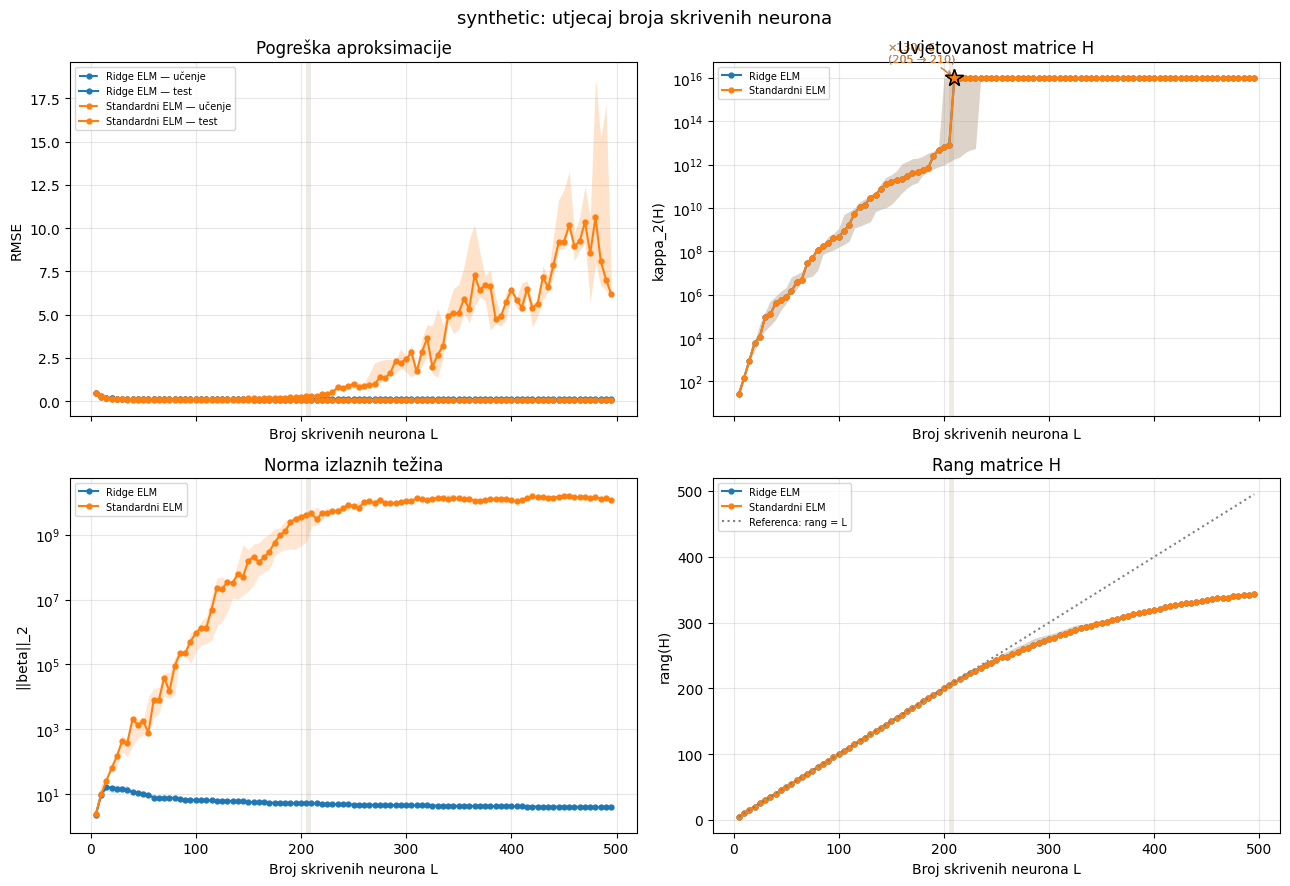


SKUP: diabetes; train=265, validation=88, test=89

==================== RMSE (učenje) — diabetes ====================
     Ridge ELM — median  Standardni ELM — median  Ridge ELM — q25  Standardni ELM — q25  Ridge ELM — q75  Standardni ELM — q75
L                                                                                                                             
5             64.770204             6.477020e+01        63.616829          6.361683e+01        65.359544          6.535954e+01
10            58.263707             5.826371e+01        57.516291          5.751629e+01        58.713814          5.871381e+01
15            54.576636             5.457663e+01        54.405014          5.440501e+01        55.397243          5.539724e+01
20            52.713237             5.271324e+01        52.626860          5.262686e+01        54.410993          5.441099e+01
25            52.183844             5.218384e+01        52.055492          5.205549e+01        52.702974          5.270

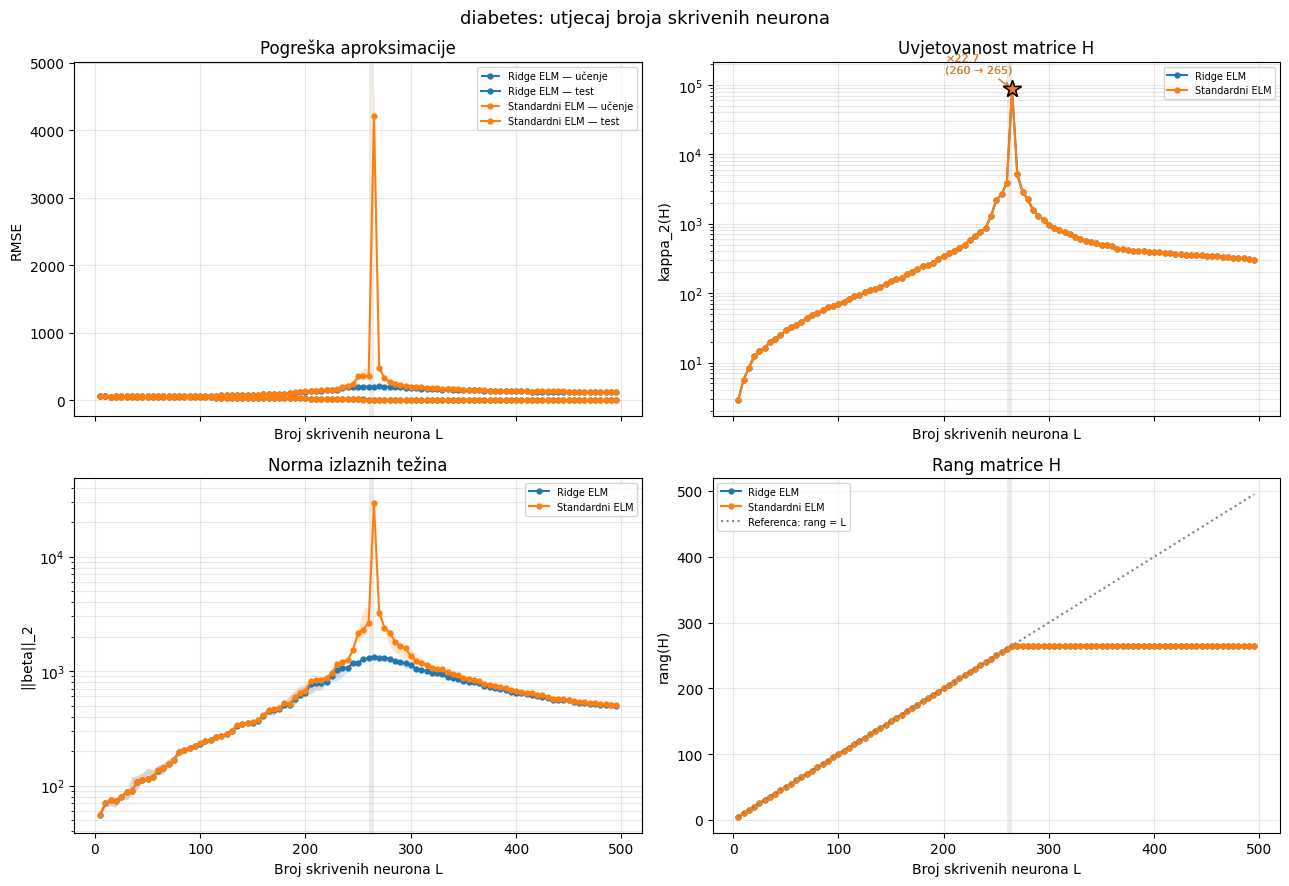

In [ ]:
datasets = load_datasets()

for name, split in datasets.items():
    print("\n" + "=" * 72)
    print(
        f"SKUP: {name}; train={len(split.y_train)}, "
        f"validation={len(split.y_val)}, test={len(split.y_test)}"
    )
    print("=" * 72)

    df_count = run_neuron_count_experiment(split, n_repeats=5)

    summary_count = plot_neuron_count_with_tables(
        df_count,
        name,
        jump_threshold=10.0,
        print_tables=True)

#5.4 Utjecaj regularizacije na učninkovitost

$\def\R{\mathbb{R}}\def\Rmat#1#2{\mathbb{R}^{#1 \times #2}}$

# Što radi `run_ridge_experiment_repeated` (i pokretačka petlja)

Funkcija provodi **ponovljeni ridge eksperiment** za fiksni broj skrivenih neurona $L$: za više slučajnih realizacija skrivenog sloja (različiti `seed`) trenira ridge ELM za **svaku $\lambda$** iz `LAMBDA_GRID`, bilježi sve metrike, odabire najbolju $\lambda$ **isključivo prema validacijskom RMSE-u**, te proizvodi:

1. detaljne tablice po realizaciji
2. sažetak po $\lambda$ (medijan, Q1, Q3, IQR)
3. učestalost odabira $\lambda$
4. evaluaciju modela odabranih validacijom
5. grafove $\text{RMSE}(\lambda)$ i $\|\beta\|_2(\lambda)$ s IQR pojasom

Na kraju, vanjska petlja pokreće sve to za **svaki dataset** u `datasets`.

---

## 1. Priprema

```python
seeds = list(seeds)
all_rows = []
selection_rows = []
```

`seeds` se pretvara u listu kako bi se mogao iterirati više puta (za dvije odvojene petlje po $\lambda$).

---

## 2. Glavna petlja po realizacijama (seedovima)

Za svaki `seed`:

### a) Jedna realizacija skrivenog sloja

$$
(W_{\text{all}}, b_{\text{all}}) = \texttt{generate\_hidden\_parameters}(d, L, \text{seed})
$$

**Ključno:** ista $(W_{\text{all}}, b_{\text{all}})$ koristi se za **sve $\lambda$** unutar tog seeda — fer usporedba po $\lambda$.

### b) Treniranje za svaku $\lambda$

Za svaki $\lambda \in \Lambda_{\text{GRID}}$:

$$
(\text{model}, \text{tr}, \text{te}, \text{diag}) = \texttt{fit\_elm\_at\_L}(\text{split}, L, \text{seed}, \lambda, W_{\text{all}}, b_{\text{all}})
$$

Bilježi se redak s metrikama:

| Stupac | Značenje |
|---|---|
| `dataset`, `seed`, `lambda` | identifikatori |
| `train_RMSE`, `test_RMSE` | RMSE na train/test |
| `train_MAE`, `test_MAE` | MAE na train/test |
| `train_R2`, `test_R2` | $R^2$ na train/test |
| `beta_norm` | $\|\beta\|_2$ |
| `rank_H` | rang $H$ |
| `kappa_H` | $\kappa_2(H)$ |
| `t_beta` | vrijeme rješavanja $\beta$ |

### c) Odabir $\lambda$ prema validaciji

Za isti seed ponovno se trenira model za svaku $\lambda$, ali ovaj put se evaluira na **validacijskom** skupu:

$$
\text{val\_RMSE}(\lambda) = \texttt{regression\_metrics}(y_{\text{val}}, \hat{y}_{\text{val}})
$$

Bilježi se par $(\lambda, \text{val\_RMSE})$ i bira:

$$
\lambda^{*} = \arg\min_{\lambda \in \Lambda_{\text{GRID}}} \text{val\_RMSE}(\lambda)
$$

$$
\text{best\_val\_RMSE} = \text{val\_RMSE}(\lambda^{*})
$$

Rezultat ide u `selection_rows`:

| Stupac | Značenje |
|---|---|
| `dataset`, `seed` | identifikatori |
| `selected_lambda` | $\lambda^{*}$ |
| `best_validation_RMSE` | $\text{val\_RMSE}(\lambda^{*})$ |

**Napomena:** odabir je **po realizaciji** — svaki seed dobiva svoju optimalnu $\lambda$. To omogućuje analizu stabilnosti odabira.

---

## 3. Detaljni ispis i spremanje

### Ispis

- `results.to_string()` — svi retci (seed × $\lambda$)
- `selections.to_string()` — odabrana $\lambda$ po seedu

### CSV

$$
\texttt{OUT\_DIR / \{split.name\}\_ridge\_lambda\_repeated.csv}
$$
$$
\texttt{OUT\_DIR / \{split.name\}\_ridge\_selections.csv}
$$

---

## 4. Sažetak po $\lambda$

Metrike koje se agregiraju:

$$
\mathcal{M} = \{\texttt{train\_RMSE},\ \texttt{test\_RMSE},\ \texttt{train\_MAE},\ \texttt{test\_MAE},\ \texttt{train\_R2},\ \texttt{test\_R2},\ \texttt{beta\_norm},\ \texttt{rank\_H},\ \texttt{kappa\_H},\ \texttt{t\_beta}\}
$$

Za svaku $\lambda$ i svaku metriku $m$:

$$
m_{\text{median}} = \operatorname{median}(m), \quad
m_{Q1} = Q_{0.25}(m), \quad
m_{Q3} = Q_{0.75}(m)
$$
$$
m_{\text{IQR}} = Q_{0.75}(m) - Q_{0.25}(m)
$$

Rezultat je `summary` DataFrame s po jednim retkom po $\lambda$.

### Ispis glavne tablice

Prikazuju se samo ključni stupci za interpretaciju:

$$
[\lambda,\ n_{\text{realizations}},\ \text{train\_RMSE}_{\text{median}},\ \text{train\_RMSE}_{\text{IQR}},\ \text{test\_RMSE}_{\text{median}},\ \text{test\_RMSE}_{\text{IQR}},\ \|\beta\|_{\text{median}},\ \|\beta\|_{\text{IQR}}]
$$

### CSV

$$
\texttt{OUT\_DIR / \{split.name\}\_ridge\_lambda\_summary.csv}
$$

---

## 5. Učestalost odabira $\lambda$

Broji se koliko puta je svaka $\lambda$ odabrana kao optimalna:

$$
\text{count}(\lambda) = \#\{\, \text{seed} : \lambda^{*}(\text{seed}) = \lambda \,\}
$$

$$
\text{percentage}(\lambda) = 100 \cdot \frac{\text{count}(\lambda)}{|\text{seeds}|}
$$

Ispisuje se i sprema:

$$
\texttt{OUT\_DIR / \{split.name\}\_ridge\_lambda\_frequency.csv}
$$

**Zašto je ovo važno:** pokazuje **stabilnost odabira** — ako je jedna $\lambda$ dominantna, odabir je robustan; ako je raspršen, odabir ovisi o realizaciji.

---

## 6. Evaluacija modela odabranih validacijom

Spaja se `selections` s `results` po $(\text{dataset}, \text{seed}, \lambda)$:

$$
\text{selected\_results} = \texttt{selections} \bowtie \texttt{results}
$$

uz `validate="one_to_one"` (svaki seed ima točno jednu odabranu $\lambda$).

Zatim se agregiraju metrike odabranih modela:

$$
[\text{best\_validation\_RMSE},\ \text{test\_RMSE},\ \text{test\_MAE},\ \text{test\_R2},\ \|\beta\|_2]
$$

s **medianom, Q1, Q3** — daje procjenu **očekivane izvedbe na testu kad se $\lambda$ bira validacijom**, što je realan scenarij (bez „peekanja" u test).

### CSV

$$
\texttt{OUT\_DIR / \{split.name\}\_ridge\_selected\_results.csv}
$$

---

## 7. Grafovi (ako `make_plot=True`)

Agregira se po $\lambda$:

$$
\text{plot\_df}(\lambda) = \big[\text{train\_median},\ \text{train\_q25},\ \text{train\_q75},\ \text{test\_median},\ \text{test\_q25},\ \text{test\_q75},\ \beta_{\text{median}},\ \beta_{q25},\ \beta_{q75}\big]
$$

### Panel A — RMSE($\lambda$) na log osi

- **train medijan** — linija + marker `o`, IQR pojas (alpha $0.2$)
- **test medijan** — linija + marker `o`, IQR pojas (alpha $0.2$)
- x-os: $\log_{10}\lambda$ (`semilogx`)
- y-os: RMSE
- naslov: „Pogreška (medijan i IQR)"

### Panel B — $\|\beta\|_2(\lambda)$ na log osi

- **medijan** — linija + marker, IQR pojas
- x-os: $\log_{10}\lambda$
- y-os: $\|\beta\|_2$
- naslov: „Norma izlaznih težina (medijan i IQR)"

### Zajedničko

- `fig.suptitle`: `"{split.name}: utjecaj regularizacije (L={L}, broj realizacija={len(seeds)})"`
- `fig.tight_layout()`
- sprema se u:

$$
\texttt{OUT\_DIR / \{split.name\}\_ridge\_lambda\_repeated.png}
$$

uz `dpi=160`, pa `plt.show()` i `plt.close(fig)`.

---

## 8. Povrat

$$
(\text{results},\ \text{summary},\ \text{selections},\ \text{selected\_results})
$$

| Objekt | Sadržaj |
|---|---|
| `results` | svi retci: seed × $\lambda$, s metrikama |
| `summary` | agregirano po $\lambda$: median, Q1, Q3, IQR |
| `selections` | odabrana $\lambda$ i $\text{val\_RMSE}$ po seedu |
| `selected_results` | spoj `selections` i `results` za odabrane modele |

---

## 9. Vanjska petlja — pokretanje za sve datasete

```python
for name, split in datasets.items():
    ...
    run_ridge_experiment_repeated(split, L=100, seeds=range(30), make_plot=True)
```

Za svaki dataset:

- ispiše se broj primjera: `train`, `validation`, `test`
- poziva se `run_ridge_experiment_repeated` s:
  - $L = 100$
  - `seeds = range(30)` → **30 realizacija**
  - `make_plot=True`

Time se dobiva **30 neovisnih realizacija** po datasetu — dovoljno za stabilnu procjenu medijana i IQR-a.

---

## Što eksperiment mjeri

### Utjecaj $\lambda$ na točnost

Krivulja $\text{RMSE}_{\text{test}}(\lambda)$ na log osi pokazuje:

- **lijevo** ($\lambda \to 0$) — obični LS, rizik od prenaučenosti i nestabilnosti
- **desno** ($\lambda \to \infty$) — prejaka regularizacija, $\beta \to 0$, underfitting
- **optimum** — kompromis između pristranosti i varijance

### Utjecaj $\lambda$ na $\|\beta\|_2$

$$
\beta_{\text{ridge}} = V\operatorname{diag}\!\left(\frac{\sigma_i}{\sigma_i^{2}+\lambda}\right)U^{T}y
$$

Za velike $\lambda$:

$$
\frac{\sigma_i}{\sigma_i^{2}+\lambda} \approx \frac{\sigma_i}{\lambda} \to 0
$$

pa $\|\beta\|_2$ monotono pada s $\lambda$ — graf to vizualizira.

### Stabilnost odabira

Učestalost odabira $\lambda$ pokazuje:

- **koncentrirana** — robustan izbor, ne ovisi o sreći inicijalizacije
- **raspršena** — odabir je nesiguran, $\lambda$ treba birati pažljivije (npr. cross-validacijom)

### Realna izvedba (selected_results)

Evaluacija modela odabranih **samo validacijom** daje **nepristranu procjenu** onoga što se može očekivati u praksi — bez korištenja test skupa za odabir.

---

## Sažetak toka

$$
\underbrace{\texttt{generate\_hidden\_parameters}}_{\text{jednom po seed, za } L}
\;\longrightarrow\;
\underbrace{(W_{\text{all}}, b_{\text{all}})}_{\text{ista za sve } \lambda}
$$
$$
\Downarrow
$$
$$
\underbrace{\texttt{fit\_elm\_at\_L}}_{\text{za svaki } \lambda}\;\longrightarrow\;\texttt{results}
\qquad
\underbrace{\texttt{ELM.fit} \to \text{val\_RMSE}}_{\text{odabir } \lambda^{*}}\;\longrightarrow\;\texttt{selections}
$$
$$
\Downarrow
$$
$$
\underbrace{\text{summary}}_{\text{median, Q1, Q3, IQR po } \lambda}
\quad
\underbrace{\text{selected\_results}}_{\text{realna izvedba}}
\quad
\underbrace{\text{plot}}_{\text{RMSE}(\lambda),\ \|\beta\|(\lambda)}
$$

- **`run_ridge_experiment_repeated`** — za fiksni $L$ i 30 seedova trenira ridge ELM za sve $\lambda$, bilježi metrike, odabire $\lambda$ validacijom, agregira i crta
- **Svrha** — **utjecaj regularizacije** na točnost, normu $\beta$ i stabilnost odabira, s realnom procjenom izvedbe
- **Ključna ideja** — ista $(W, b)$ po seedu za sve $\lambda$ → fer usporedba; odabir $\lambda$ **samo validacijom** → nema curenja informacija iz testa


SKUP: synthetic; train=480, validation=160, test=160
[synthetic] Obrada realizacije seed=0...
[synthetic] Obrada realizacije seed=1...
[synthetic] Obrada realizacije seed=2...
[synthetic] Obrada realizacije seed=3...
[synthetic] Obrada realizacije seed=4...
[synthetic] Obrada realizacije seed=5...
[synthetic] Obrada realizacije seed=6...
[synthetic] Obrada realizacije seed=7...
[synthetic] Obrada realizacije seed=8...
[synthetic] Obrada realizacije seed=9...
[synthetic] Obrada realizacije seed=10...
[synthetic] Obrada realizacije seed=11...
[synthetic] Obrada realizacije seed=12...
[synthetic] Obrada realizacije seed=13...
[synthetic] Obrada realizacije seed=14...
[synthetic] Obrada realizacije seed=15...
[synthetic] Obrada realizacije seed=16...
[synthetic] Obrada realizacije seed=17...
[synthetic] Obrada realizacije seed=18...
[synthetic] Obrada realizacije seed=19...
[synthetic] Obrada realizacije seed=20...
[synthetic] Obrada realizacije seed=21...
[synthetic] Obrada realizacije s

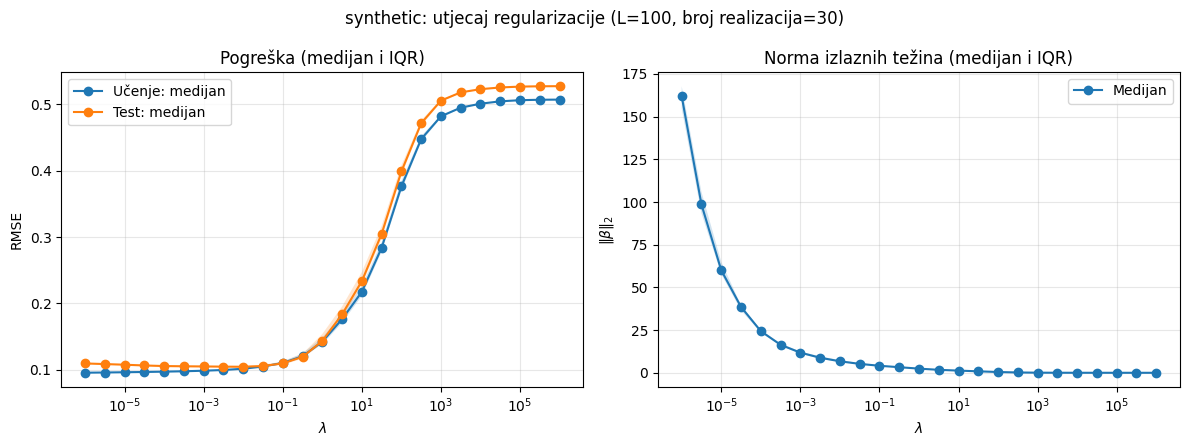


SKUP: diabetes; train=265, validation=88, test=89
[diabetes] Obrada realizacije seed=0...
[diabetes] Obrada realizacije seed=1...
[diabetes] Obrada realizacije seed=2...
[diabetes] Obrada realizacije seed=3...
[diabetes] Obrada realizacije seed=4...
[diabetes] Obrada realizacije seed=5...
[diabetes] Obrada realizacije seed=6...
[diabetes] Obrada realizacije seed=7...
[diabetes] Obrada realizacije seed=8...
[diabetes] Obrada realizacije seed=9...
[diabetes] Obrada realizacije seed=10...
[diabetes] Obrada realizacije seed=11...
[diabetes] Obrada realizacije seed=12...
[diabetes] Obrada realizacije seed=13...
[diabetes] Obrada realizacije seed=14...
[diabetes] Obrada realizacije seed=15...
[diabetes] Obrada realizacije seed=16...
[diabetes] Obrada realizacije seed=17...
[diabetes] Obrada realizacije seed=18...
[diabetes] Obrada realizacije seed=19...
[diabetes] Obrada realizacije seed=20...
[diabetes] Obrada realizacije seed=21...
[diabetes] Obrada realizacije seed=22...
[diabetes] Obrad

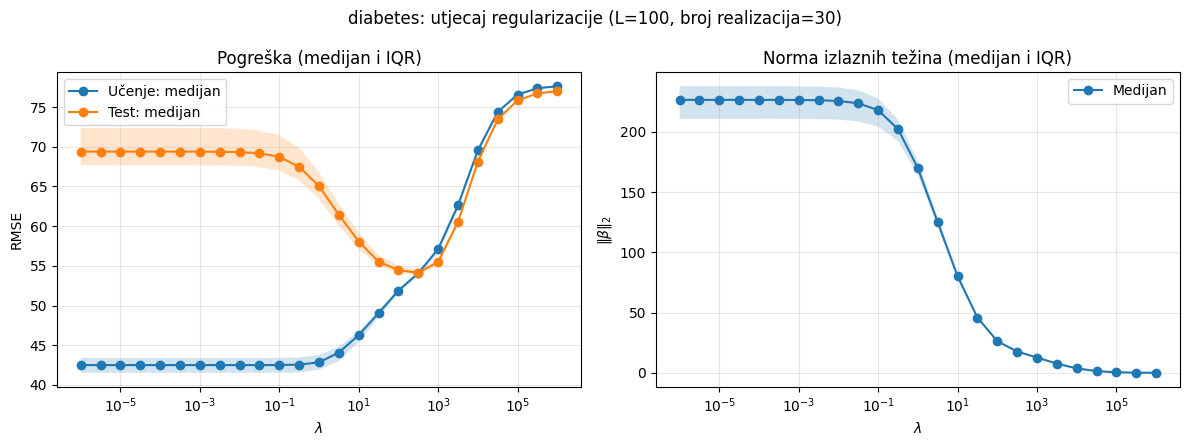

In [ ]:
def run_ridge_experiment_repeated(
    split,
    L=100,
    seeds=range(30),
    make_plot=True,
):
    """
    Ponavlja ridge ELM eksperiment za više realizacija.
    Ispisuje pojedinačne i sažete rezultate, sprema CSV datoteke
    i prikazuje medijane s interkvartilnim rasponima.
    Lambda se odabire isključivo prema validacijskom RMSE-u.
    """

    # Pretvori u listu kako bi se seeds mogli koristiti više puta.
    seeds = list(seeds)

    all_rows = []
    selection_rows = []

    for seed in seeds:
        print(f"[{split.name}] Obrada realizacije seed={seed}...")

        # Jedna realizacija slučajnih unutarnjih parametara.
        W_all, b_all = generate_hidden_parameters(
            split.X_train.shape[1], L, seed
        )

        # Rezultati za sve lambde uz iste W i b.
        for lam in LAMBDA_GRID:
            model, tr, te, diag = fit_elm_at_L(
                split,
                L,
                seed,
                lam=float(lam),
                W_all=W_all,
                b_all=b_all,
            )

            all_rows.append({
                "dataset": split.name,
                "seed": seed,
                "lambda": float(lam),
                "train_RMSE": tr["RMSE"],
                "test_RMSE": te["RMSE"],
                "train_MAE": tr["MAE"],
                "test_MAE": te["MAE"],
                "train_R2": tr["R2"],
                "test_R2": te["R2"],
                "beta_norm": diag["beta_norm"],
                "rank_H": diag["rank_H"],
                "kappa_H": diag["kappa_H"],
                "t_beta": model.t_beta,
            })

        # Odabir lambde zasebno za ovu realizaciju,
        # isključivo prema validacijskom RMSE-u.
        val_rows = []

        for lam in LAMBDA_GRID:
            model = ELM(
                n_hidden=L,
                activation=ACTIVATION,
                lam=float(lam),
                random_state=seed,
            )
            model.fit(
                split.X_train,
                split.y_train,
                W=W_all,
                b=b_all,
            )

            val_rmse = regression_metrics(
                split.y_val,
                model.predict(split.X_val),
            )["RMSE"]

            val_rows.append((float(lam), val_rmse))

        best_lam, best_val_rmse = min(
            val_rows, key=lambda item: item[1]
        )

        selection_rows.append({
            "dataset": split.name,
            "seed": seed,
            "selected_lambda": best_lam,
            "best_validation_RMSE": best_val_rmse,
        })

    results = pd.DataFrame(all_rows)
    selections = pd.DataFrame(selection_rows)

    # ---------------------------------------------------------
    # 1. ISPIS POJEDINAČNIH REZULTATA
    # ---------------------------------------------------------
    print(
        "\n" + "=" * 30
        + f" DETALJNI REZULTATI: {split.name} "
        + "=" * 30
    )
    print(results.to_string(index=False))

    print(
        "\n" + "=" * 30
        + f" ODABIR LAMBDE: {split.name} "
        + "=" * 30
    )
    print(selections.to_string(index=False))

    # Spremanje svih pojedinačnih rezultata.
    results.to_csv(
        OUT_DIR / f"{split.name}_ridge_lambda_repeated.csv",
        index=False,
    )
    selections.to_csv(
        OUT_DIR / f"{split.name}_ridge_selections.csv",
        index=False,
    )

    # ---------------------------------------------------------
    # 2. SAŽETAK: MEDIJAN, Q1, Q3 I IQR ZA SVAKU LAMBDU
    # ---------------------------------------------------------
    metrics = [
        "train_RMSE",
        "test_RMSE",
        "train_MAE",
        "test_MAE",
        "train_R2",
        "test_R2",
        "beta_norm",
        "rank_H",
        "kappa_H",
        "t_beta",
    ]

    summary_rows = []

    for lam, group in results.groupby("lambda", sort=True):
        row = {"lambda": lam, "n_realizations": len(group)}

        for metric in metrics:
            values = group[metric].dropna()

            row[f"{metric}_median"] = values.median()
            row[f"{metric}_Q1"] = values.quantile(0.25)
            row[f"{metric}_Q3"] = values.quantile(0.75)
            row[f"{metric}_IQR"] = (
                values.quantile(0.75) - values.quantile(0.25)
            )

        summary_rows.append(row)

    summary = pd.DataFrame(summary_rows)

    print(
        "\n" + "=" * 30
        + f" SAŽETAK PO LAMBDI: {split.name} "
        + "=" * 30
    )

    # Glavna tablica za interpretaciju u diplomskom radu.
    summary_display_cols = [
        "lambda",
        "n_realizations",
        "train_RMSE_median",
        "train_RMSE_IQR",
        "test_RMSE_median",
        "test_RMSE_IQR",
        "beta_norm_median",
        "beta_norm_IQR",
    ]

    print(
        summary[summary_display_cols].to_string(
            index=False,
            float_format=lambda x: f"{x:.6g}",
        )
    )

    summary.to_csv(
        OUT_DIR / f"{split.name}_ridge_lambda_summary.csv",
        index=False,
    )

    # ---------------------------------------------------------
    # 3. UČESTALOST ODABRANIH VRIJEDNOSTI LAMBDE
    # ---------------------------------------------------------
    selection_frequency = (
        selections["selected_lambda"]
        .value_counts()
        .rename_axis("lambda")
        .reset_index(name="count")
        .sort_values("lambda")
        .reset_index(drop=True)
    )

    selection_frequency["percentage"] = (
        100 * selection_frequency["count"] / len(selections)
    )

    print(
        "\n" + "=" * 30
        + f" UČESTALOST ODABIRA LAMBDE: {split.name} "
        + "=" * 30
    )
    print(
        selection_frequency.to_string(
            index=False,
            float_format=lambda x: f"{x:.3f}",
        )
    )

    selection_frequency.to_csv(
        OUT_DIR / f"{split.name}_ridge_lambda_frequency.csv",
        index=False,
    )

    # ---------------------------------------------------------
    # 4. REZULTATI MODELA ODABRANIH VALIDACIJOM
    # ---------------------------------------------------------
    selected_results = selections.merge(
        results,
        left_on=["dataset", "seed", "selected_lambda"],
        right_on=["dataset", "seed", "lambda"],
        how="left",
        validate="one_to_one",
    )

    print(
        "\n" + "=" * 30
        + f" EVALUACIJA ODABRANIH MODELA: {split.name} "
        + "=" * 30
    )

    selected_metrics = [
        "best_validation_RMSE",
        "test_RMSE",
        "test_MAE",
        "test_R2",
        "beta_norm",
    ]

    print(
        selected_results[selected_metrics]
        .agg(["median", lambda x: x.quantile(0.25),
              lambda x: x.quantile(0.75)])
        .rename(index={
            "median": "Medijan",
            "<lambda_0>": "Q1",
            "<lambda_1>": "Q3",
        })
        .to_string(float_format=lambda x: f"{x:.6g}")
    )

    selected_results.to_csv(
        OUT_DIR / f"{split.name}_ridge_selected_results.csv",
        index=False,
    )

    # ---------------------------------------------------------
    # 5. GRAFOVI: MEDIJAN I INTERKVARTILNI RASPON
    # ---------------------------------------------------------
    if make_plot:
        plot_df = (
            results.groupby("lambda")
            .agg(
                train_median=("train_RMSE", "median"),
                train_q25=("train_RMSE",
                           lambda x: x.quantile(0.25)),
                train_q75=("train_RMSE",
                           lambda x: x.quantile(0.75)),
                test_median=("test_RMSE", "median"),
                test_q25=("test_RMSE",
                          lambda x: x.quantile(0.25)),
                test_q75=("test_RMSE",
                          lambda x: x.quantile(0.75)),
                beta_median=("beta_norm", "median"),
                beta_q25=("beta_norm",
                          lambda x: x.quantile(0.25)),
                beta_q75=("beta_norm",
                          lambda x: x.quantile(0.75)),
            )
            .reset_index()
        )

        fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

        # A) RMSE
        ax = axes[0]

        ax.semilogx(
            plot_df["lambda"],
            plot_df["train_median"],
            marker="o",
            label="Učenje: medijan",
        )
        ax.fill_between(
            plot_df["lambda"],
            plot_df["train_q25"],
            plot_df["train_q75"],
            alpha=0.2,
        )

        ax.semilogx(
            plot_df["lambda"],
            plot_df["test_median"],
            marker="o",
            label="Test: medijan",
        )
        ax.fill_between(
            plot_df["lambda"],
            plot_df["test_q25"],
            plot_df["test_q75"],
            alpha=0.2,
        )

        ax.set_xlabel(r"$\lambda$")
        ax.set_ylabel("RMSE")
        ax.set_title("Pogreška (medijan i IQR)")
        ax.grid(True, alpha=0.3)
        ax.legend()

        # B) Norma izlaznih težina
        ax = axes[1]

        ax.semilogx(
            plot_df["lambda"],
            plot_df["beta_median"],
            marker="o",
            label="Medijan",
        )
        ax.fill_between(
            plot_df["lambda"],
            plot_df["beta_q25"],
            plot_df["beta_q75"],
            alpha=0.2,
        )

        ax.set_xlabel(r"$\lambda$")
        ax.set_ylabel(r"$\|\beta\|_2$")
        ax.set_title("Norma izlaznih težina (medijan i IQR)")
        ax.grid(True, alpha=0.3)
        ax.legend()

        fig.suptitle(
            f"{split.name}: utjecaj regularizacije "
            f"(L={L}, broj realizacija={len(seeds)})"
        )
        fig.tight_layout()

        fig.savefig(
            OUT_DIR / f"{split.name}_ridge_lambda_repeated.png",
            dpi=160,
        )
        plt.show()
        plt.close(fig)

    return results, summary, selections, selected_results


# -------------------------------------------------------------
# POKRETANJE ZA SVE SKUPOVE PODATAKA
# -------------------------------------------------------------
for name, split in datasets.items():
    print("\n" + "=" * 72)
    print(
        f"SKUP: {name}; "
        f"train={len(split.y_train)}, "
        f"validation={len(split.y_val)}, "
        f"test={len(split.y_test)}"
    )
    print("=" * 72)

    results, summary, selections, selected_results = (
        run_ridge_experiment_repeated(
            split,
            L=100,
            seeds=range(30),
            make_plot=True,
        )
    )

$\def\R{\mathbb{R}}\def\Rmat#1#2{\mathbb{R}^{#1 \times #2}}$

# Što rade `generate_parameters_ext` i `run_distribution_test`

Dvije funkcije koje zajedno ispituju **utjecaj razdiobe i skale slučajnih parametara skrivenog sloja** na kvalitetu ELM-a. Prva generira $(W, b)$ iz odabrane razdiobe i skale, a druga sustavno prolazi kroz **kombinacije razdioba × skala**, trenira standardni ELM ($\lambda = 0$) i vizualizira ovisnost test RMSE o skali za svaku razdiobu.

Eksperiment odgovara na pitanja:

- **Kako oblik razdiobe utječe na točnost?** (uniform vs. normal vs. Laplace vs. Cauchy)
- **Postoji li optimalna skala?** (U-krivulja: premalo → linearno; previše → zasićenje)
- **Koliko su teški repovi (Cauchy) opasni?** (numerička singularnost, eksplozija RMSE)

---

## `generate_parameters_ext(n_features, L, dist_type="uniform", scale=1.0, seed=42)`

Generira parametre skrivenog sloja iz zadane razdiobe i skale.

### Generator

$$
\text{rng} = \texttt{default\_rng}(\text{seed})
$$

### Razdiobe

Za svaku razdiobu generiraju se **ista dimenzija**: $W \in \Rmat{L}{n_{\text{features}}}$, $b \in \R^{L}$.

#### Uniformna

$$
W_{ij} \sim \mathcal{U}(-\text{scale}, \text{scale}), \qquad
b_j \sim \mathcal{U}(-\text{scale}, \text{scale})
$$

#### Normalna

$$
W_{ij} \sim \mathcal{N}(0, \text{scale}), \qquad
b_j \sim \mathcal{N}(0, \text{scale})
$$

#### Laplaceova

$$
W_{ij} \sim \text{Laplace}(0, \text{scale}), \qquad
b_j \sim \text{Laplace}(0, \text{scale})
$$

Laplace ima **teže repove** od normalne — više ekstremnih vrijednosti.

#### Cauchyjeva

$$
W_{ij} = \text{scale} \cdot C_{ij}, \qquad C_{ij} \sim \text{Cauchy}(0, 1)
$$

Cauchy ima **najteže repove** (nema konačne varijance); ekstremne vrijednosti su **očekivane**, ne rijetke. Zato kod koristi `standard_cauchy` i skalira.

### Nepoznata razdioba

Baca `ValueError` s porukom.

### Povrat

$$
(W, b)
$$

---

## `run_distribution_test(split, L=L_MONTE_CARLO, n_seeds=5)`

Sustavno ispituje **utjecaj razdiobe i skale** na test RMSE.

### 1. Mreža parametara

**Skale** (logaritamski raspoređene, od ekstremno uskih do ekstremno širokih):

$$
\text{scales} = [0.001,\ 0.01,\ 0.1,\ 0.5,\ 1.0,\ 2.0,\ 5.0,\ 10.0,\ 50.0,\ 100.0]
$$

**Razdiobe:**

$$
\text{distributions} = [\text{uniform},\ \text{normal},\ \text{laplace},\ \text{cauchy}]
$$

Ukupno $4 \times 10 = 40$ kombinacija, svaka s $n_{\text{seeds}} = 5$ ponavljanja → **200 treniranja** po datasetu.

### 2. Dvostruka petlja: razdioba × skala

Za svaku razdiobu i svaku skalu:

#### a) Više seedova za stabilnu procjenu

Za svaki $s_{\text{idx}} \in \{0, \dots, n_{\text{seeds}}-1\}$:

$$
\text{current\_seed} = 2000 + s_{\text{idx}}
$$

$$
(W_{\text{all}}, b_{\text{all}}) = \texttt{generate\_parameters\_ext}(d, L, \text{dist}, \text{scale}, \text{current\_seed})
$$

#### b) Treniranje standardnog ELM-a ($\lambda = 0$)

$$
(\_, \_, \text{te}, \_) = \texttt{fit\_elm\_at\_L}(\text{split}, L, \text{current\_seed}, \lambda = 0, W_{\text{all}}, b_{\text{all}})
$$

**Zašto $\lambda = 0$:** da se **izolira utjecaj same razdiobe** — bez regularizacije koja bi mogla maskirati nestabilnost.

#### c) Filtriranje ekstremnih vrijednosti

$$
\text{rmse\_val} =
\begin{cases}
\text{te["RMSE"]}, & \text{ako } \text{te["RMSE"]} < 100 \\[4pt]
\text{NaN}, & \text{inače}
\end{cases}
$$

Time se sprječava da Cauchyjeve eksplozije unište skalu grafa.

#### d) Hvatanje numeričkih grešaka

```python
except (np.linalg.LinAlgError, ValueError, FloatingPointError):
    seed_rmse.append(np.nan)
```

Ako $H$ postane numerički singularan (npr. zbog ekstremnih Cauchyjevih vrijednosti), rezultat se bilježi kao `NaN` — ne ruši eksperiment.

### 3. Agregacija

$$
\overline{\text{RMSE}}(\text{dist}, \text{scale}) = \texttt{nanmean}(\text{seed\_rmse})
$$

`nanmean` ignorira `NaN` vrijednosti — prosjek uspješnih pokretanja.

Rezultat se dodaje u `results`:

| Stupac | Značenje |
|---|---|
| `Razdioba` | naziv razdiobe |
| `Skala` | parametar skale |
| `Test_RMSE` | prosječni test RMSE preko seedova |

### 4. DataFrame

$$
\texttt{res\_df} = \text{DataFrame}(\text{results})
$$

---

## 5. Graf — U-krivulje po razdiobi

### Postavke

- **x-os:** skala, **logaritamska** (`set_xscale('log')`) — jer raspon ide od $10^{-3}$ do $10^{2}$
- **y-os:** prosječni test RMSE
- boje i markeri po razdiobi:

| Razdioba | Boja | Marker |
|---|---|---|
| `uniform` | `#d95f02` | `o` |
| `normal` | `#1b9e77` | `s` |
| `laplace` | `#7570b3` | `^` |
| `cauchy` | `#e7298a` | `d` |

### Pametne granice y-osi

Ako Cauchy divergira, graf bi bio nečitljiv. Zato:

$$
y_{\min} = 0.95 \cdot \min(\text{valid\_rmse})
$$
$$
y_{\max} = 1.15 \cdot Q_{0.90}(\text{valid\_rmse})
$$

Koristi se **90. percentil** umjesto maksimuma — da rijetke eksplozije ne rastegnu os do beskorisnosti.

### Naslov i oznake

- x: „Parametar skale (log mjerilo)"
- y: „Prosječni Test RMSE"
- naslov: `"{split.name}: Utjecaj neprekidnih razdioba i parametra skale na ELM (L={L})"`

### Spremanje

$$
\texttt{OUT\_DIR / \{split.name\}\_utjecaj\_razdioba\_i\_skala.png}
$$

uz `dpi=160`, pa `plt.show()` i `plt.close(fig)`.

---

## 6. Pivot tablica

Za brzi uvid u brojke:

$$
\texttt{pivot\_table} = \text{res\_df.pivot}(\text{index} = \text{Skala},\ \text{columns} = \text{Razdioba},\ \text{values} = \text{Test\_RMSE})
$$

Ispisuje se zaokruženo na 4 decimale.

**Povrat:** `res_df` — DataFrame s rezultatima.

---

## Što eksperiment mjeri

### Utjecaj razdiobe

Različite razdiobe daju različite **efektivne raspone** $W$ i $b$:

- **uniform** — ograničen raspon $[-\text{scale}, \text{scale}]$
- **normal** — većina vrijednosti u $[-3\text{scale}, 3\text{scale}]$, ali s repovima
- **laplace** — teži repovi, više ekstremnih vrijednosti
- **cauchy** — najteži repovi, **nema konačne varijance**, ekstremi su česti

Teži repovi → veći raspon $XW^{T} + b$ → aktivacije u zasićenju (tanh/sigmoid) ili eksploziji → lošija reprezentacija → veći RMSE.

### Utjecaj skale — U-krivulja

Za fiksnu razdiobu, ovisnost RMSE o skali tipično ima **U-oblik**:

- **premala skala** — $XW^{T} + b \approx 0$ → aktivacije u linearnom području → model se ponaša gotovo linearno → underfitting
- **optimalna skala** — aktivacije koriste nelinearno područje → dobra reprezentacija
- **prevelika skala** — aktivacije zasićene (tanh → $\pm 1$, sigmoid → $0/1$) → gubi se informacija → underfitting
- **ekstremna skala + Cauchy** — numerička singularnost, RMSE eksplodira

### Zašto $\lambda = 0$

Bez regularizacije, utjecaj razdiobe je **čist** — nema ridgea koji bi stabilizirao loše kondicioniran $H$. Time se vidi **prava cijena** teških repova: numerička nestabilnost i eksplozija $\|\beta\|$.

### Zašto $n_{\text{seeds}} = 5$

Svaka točka je prosjek 5 realizacija — dovoljno da se smanji šum slučajnosti, a da eksperiment ostane brz. Veći $n_{\text{seeds}}$ dao bi stabilnije procjene, ali sporije.

---

## Sažetak toka

$$
\underbrace{\text{scales} \times \text{distributions}}_{\text{40 kombinacija}}
\;\xrightarrow[\text{za svaku, } n_{\text{seeds}}=5]{\;\texttt{generate\_parameters\_ext}\;}\;
\underbrace{(W, b)}_{\text{razdioba, skala}}
$$
$$
\Downarrow
$$
$$
\underbrace{\texttt{fit\_elm\_at\_L}(\lambda = 0)}_{\text{standardni ELM}}
\;\longrightarrow\;
\underbrace{\text{test\_RMSE}}_{\text{filtrirano, agregirano}}
$$
$$
\Downarrow
$$
$$
\underbrace{\text{res\_df}}_{\text{pivot tablica}}
\quad\text{i}\quad
\underbrace{\text{U-krivulje}}_{\text{po razdiobi, log x-os}}
\;\longrightarrow\;
\texttt{OUT\_DIR / \{split.name\}\_utjecaj\_razdioba\_i\_skala.png}
$$

- **`generate_parameters_ext`** — generira $(W, b)$ iz odabrane razdiobe (uniform, normal, Laplace, Cauchy) i skale
- **`run_distribution_test`** — sustavno prolazi kroz 40 kombinacija × 5 seedova, trenira standardni ELM, bilježi test RMSE, crta U-krivulje i pivot tablicu
- **Ključna ideja** — **razdioba i skala kontroliraju efektivni raspon aktivacija**; preusko → linearno, presko → zasićenje, a teški repovi (Cauchy) → numerička nestabilnost; $\lambda = 0$ izolira taj utjecaj

In [ ]:
def generate_parameters_ext(n_features, L, dist_type="uniform", scale=1.0, seed=42):
    rng = np.random.default_rng(seed)
    if dist_type == "uniform":
        # Ispravljeno: matrica W mora biti dimenzija (L, n_features)
        W = rng.uniform(-scale, scale, size=(L, n_features))
        b = rng.uniform(-scale, scale, size=(L,))
    elif dist_type == "normal":
        W = rng.normal(0, scale, size=(L, n_features))
        b = rng.normal(0, scale, size=(L,))
    elif dist_type == "laplace":
        W = rng.laplace(0, scale, size=(L, n_features))
        b = rng.laplace(0, scale, size=(L,))
    elif dist_type == "cauchy":
        W = scale * rng.standard_cauchy(size=(L, n_features))
        b = scale * rng.standard_cauchy(size=(L,))
    else:
        raise ValueError(f"Nepoznata razdioba: {dist_type}")
    return W, b

def run_distribution_test(split, L=L_MONTE_CARLO, n_seeds=5):
    # Definiramo raspon skala od ekstremno uskih do ekstremno širokih (logaritamska skala)
    scales = [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0, 50.0, 100.0]
    distributions = ["uniform", "normal", "laplace", "cauchy"]

    results = []

    print(f"\n========================================================")

    # Prolazimo kroz sve kombinacije razdioba i skala
    for dist in distributions:
        print(f"Pokrećem test za razdiobu: {dist.upper()}")
        for scale in scales:
            seed_rmse = []

            # Više pokretanja (sjemenki) po svakoj točki kako bismo dobili stabilan prosjek
            for s_idx in range(n_seeds):
                current_seed = 2000 + s_idx
                W_all, b_all = generate_parameters_ext(
                    split.X_train.shape[1], L, dist_type=dist, scale=scale, seed=current_seed
                )

                # Koristimo Standardni ELM (lam=0.0) kako bismo čisto vidjeli utjecaj same razdiobe
                try:
                    _, _, te, _ = fit_elm_at_L(
                        split, L, current_seed, lam=0.0, W_all=W_all, b_all=b_all
                    )
                    # Sprječavamo da ekstremni Cauchy outlieri unište skalu grafa (rezžemo na razumnu max vrijednost ako ode u beskonačnost)
                    rmse_val = te["RMSE"] if te["RMSE"] < 100.0 else np.nan
                    seed_rmse.append(rmse_val)
                except (np.linalg.LinAlgError, ValueError, FloatingPointError):
                    # U slučaju numeričke singularnosti (dijeljenje s nulom u pseudoinverziji)
                    seed_rmse.append(np.nan)

            # Računamo prosjek uspješnih pokretanja
            avg_rmse = np.nanmean(seed_rmse) if len(seed_rmse) > 0 else np.nan
            results.append({
                "Razdioba": dist,
                "Skala": scale,
                "Test_RMSE": avg_rmse
            })

    # Pretvaramo u DataFrame radi lakše vizualizacije
    res_df = pd.DataFrame(results)

    # -----------------------------------------------------------------
    # IZRADA GRAFA (U-krivulje ovisnosti o skali)
    # -----------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(10, 6))

    colors = {"uniform": "#d95f02", "normal": "#1b9e77", "laplace": "#7570b3", "cauchy": "#e7298a"}
    markers = {"uniform": "o", "normal": "s", "laplace": "^", "cauchy": "d"}

    for dist in distributions:
        sub_df = res_df[res_df.Razdioba == dist]
        ax.plot(
            sub_df["Skala"],
            sub_df["Test_RMSE"],
            label=f"{dist.capitalize()} razdioba",
            color=colors[dist],
            marker=markers[dist],
            linewidth=2,
            markersize=6
        )

    # Budući da skale idu od 0.001 do 100, x-os MORA biti logaritamska
    ax.set_xscale('log')
    ax.set_xlabel("Parametar skale (log mjerilo)", fontsize=11)
    ax.set_ylabel("Prosječni Test RMSE", fontsize=11)
    ax.set_title(f"{split.name}: Utjecaj neprekidnih razdioba i parametra skale na ELM (L={L})", fontsize=12, fontweight='bold')

    # Postavljamo pametne granice y-osi kako graf ne bi pobjegao ako Cauchy potpuno divergira na velikim skalama
    valid_rmse = res_df["Test_RMSE"].dropna()
    if len(valid_rmse) > 0:
        y_min = valid_rmse.min() * 0.95
        # Uzimamo 90. percentil umjesto maksimuma da izbjegnemo vizualno uništavanje grafa zbog rijetkih eksplozija
        y_max = np.percentile(valid_rmse, 90) * 1.15
        ax.set_ylim(y_min, y_max)

    ax.grid(True, which="both", linestyle="--", alpha=0.5)
    ax.legend(fontsize=10)
    fig.tight_layout()

    # Spremanje grafa za Overleaf
    fig.savefig(OUT_DIR / f"{split.name}_utjecaj_razdioba_i_skala.png", dpi=160)
    plt.show()
    plt.close(fig)

    # Ispis pivot tablice za brzi uvid u brojke
    pivot_table = res_df.pivot(index="Skala", columns="Razdioba", values="Test_RMSE")
    print(f"\nTablični pregled ovisnosti Test RMSE o razdiobi i skali:\n{pivot_table.round(4)}")

    return res_df


SKUP: synthetic; train=480, validation=160, test=160

Pokrećem test za razdiobu: UNIFORM
Pokrećem test za razdiobu: NORMAL
Pokrećem test za razdiobu: LAPLACE
Pokrećem test za razdiobu: CAUCHY


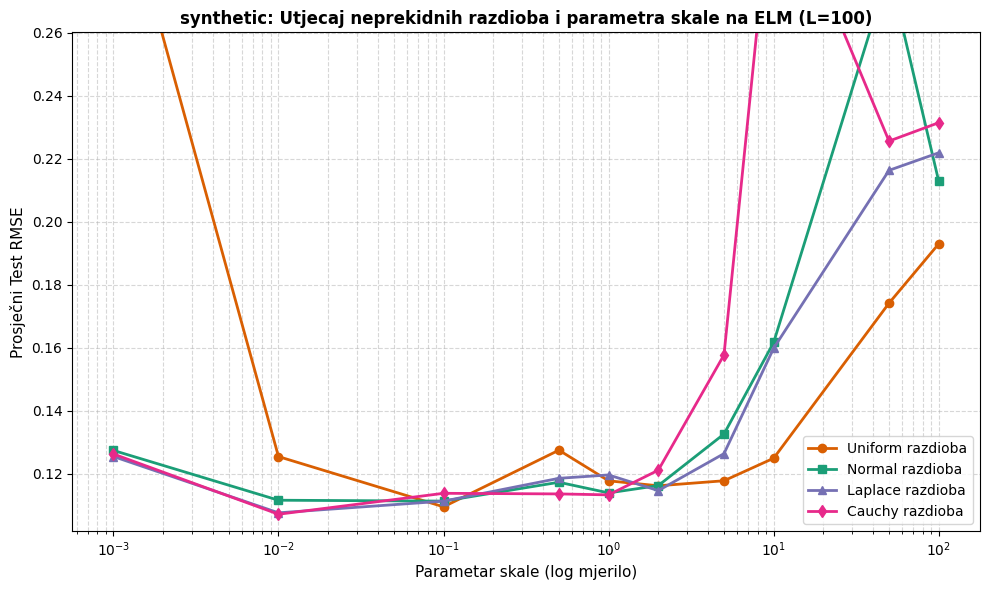


Tablični pregled ovisnosti Test RMSE o razdiobi i skali:
Razdioba  cauchy  laplace  normal  uniform
Skala                                     
0.001     0.1263   0.1255  0.1274   0.3158
0.010     0.1072   0.1076  0.1116   0.1255
0.100     0.1138   0.1113  0.1113   0.1095
0.500     0.1136   0.1186  0.1173   0.1275
1.000     0.1133   0.1196  0.1139   0.1178
2.000     0.1211   0.1147  0.1163   0.1162
5.000     0.1577   0.1264  0.1326   0.1178
10.000    0.3132   0.1599  0.1617   0.1249
50.000    0.2256   0.2163  0.2798   0.1742
100.000   0.2314   0.2219  0.2128   0.1930

SKUP: diabetes; train=265, validation=88, test=89

Pokrećem test za razdiobu: UNIFORM
Pokrećem test za razdiobu: NORMAL
Pokrećem test za razdiobu: LAPLACE
Pokrećem test za razdiobu: CAUCHY


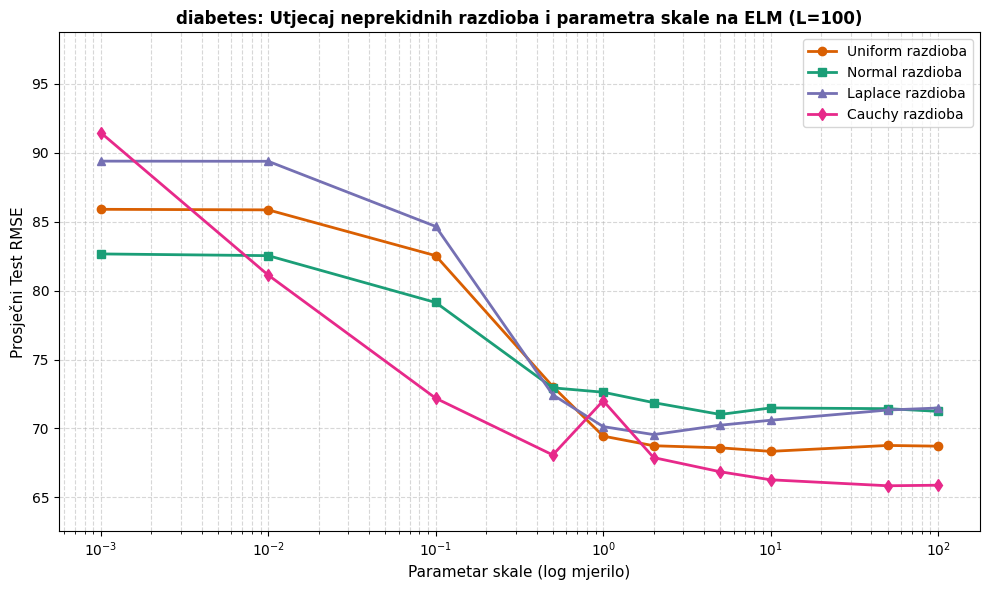


Tablični pregled ovisnosti Test RMSE o razdiobi i skali:
Razdioba   cauchy  laplace   normal  uniform
Skala                                       
0.001     91.4640  89.3994  82.6649  85.9028
0.010     81.1269  89.3875  82.5396  85.8618
0.100     72.1933  84.6596  79.1401  82.5370
0.500     68.0769  72.4428  72.9479  73.0436
1.000     72.0119  70.1339  72.6299  69.4441
2.000     67.8854  69.5544  71.8746  68.7453
5.000     66.8563  70.2360  71.0163  68.5930
10.000    66.2739  70.5960  71.4884  68.3378
50.000    65.8410  71.3374  71.4354  68.7659
100.000   65.8800  71.4833  71.2418  68.7140


In [ ]:
for name, split in datasets.items():
        print("\n" + "=" * 72)
        print(f"SKUP: {name}; train={len(split.y_train)}, validation={len(split.y_val)}, "
              f"test={len(split.y_test)}")
        print("=" * 72)
        dist_df = run_distribution_test(split, L=L_MONTE_CARLO, n_seeds=5)

In [ ]:
def run_incremental_experiment_repeated(
    split,
    seeds=range(5),
    make_plot=True,
):
    """
    Ponavlja inkrementalni ELM za više realizacija slučajnih parametara.
    Sve metrike (RMSE, rang, kappa, ||beta||) bilježe se samo na kontrolnim
    točkama L_GRID (svaki 5. neuron), pa nema NaN vrijednosti, a SVD za kappa
    računa se samo na tim točkama.
    """
    max_L = min(L_INCREMENTAL_MAX, max(L_GRID))
    checkpoints = sorted(set([*L_GRID, max_L]))
    checkpoint_set = set(checkpoints)
    seeds = list(seeds)
    all_paths = []

    for seed in seeds:
        inc = IncrementalELM(max_hidden=max_L, activation=ACTIVATION, random_state=seed)
        inc.fit_path(
            split.X_train, split.y_train,
            X_val=split.X_val, y_val=split.y_val,
            X_test=split.X_test, y_test=split.y_test,
            checkpoints=checkpoints,
        )

        path = pd.DataFrame(inc.path)
        if path.empty:
            continue

        # Indeksi prihvaćenih stupaca (j je 0-bazirani indeks neurona)
        accepted_idx = np.flatnonzero(path["accepted"].to_numpy())

        # Zadržavamo samo kontrolne točke
        path = path[path["L"].isin(checkpoint_set)].reset_index(drop=True)

        # kappa samo na kontrolnim točkama
        kappas = []
        for L in path["L"]:
            active = accepted_idx[accepted_idx < L]
            if len(active) == 0:
                kappas.append(1.0)
                continue
            H_current = inc._activation(
                split.X_train @ inc.W[active].T + inc.b[active]
            )
            kappa, _, _ = safe_condition_number(H_current)
            kappas.append(kappa)

        path["H_condition_number"] = kappas
        path["seed"] = seed
        path["dataset"] = split.name
        all_paths.append(path)
        print(f"[{split.name}] Inkrementalni ELM - seed {seed} završen.")

    results = pd.concat(all_paths, ignore_index=True)
    results.to_csv(OUT_DIR / f"{split.name}_incremental_repeated_raw.csv", index=False)

    # --- Statistički sažetak po L (medijan, Q25, Q75) ---
    metrics_to_agg = ["train_RMSE", "val_RMSE", "test_RMSE",
                      "H_condition_number", "beta_norm", "rank_H"]
    agg_dict = {}
    for m in metrics_to_agg:
        if m in results.columns:
            agg_dict[f"{m}_median"] = (m, "median")
            agg_dict[f"{m}_q25"] = (m, lambda x: x.dropna().quantile(0.25))
            agg_dict[f"{m}_q75"] = (m, lambda x: x.dropna().quantile(0.75))

    summary = results.groupby("L").agg(**agg_dict).reset_index()
    summary.to_csv(OUT_DIR / f"{split.name}_incremental_repeated_summary.csv", index=False)

    print("\n" + "=" * 30 + f" SAŽETAK INKREMENTALNE ANALIZE (Medijani): {split.name} " + "=" * 30)
    print(summary.to_string(index=False))
    print("=" * 95 + "\n")

    # --- Grafički prikaz (2x2) ---
    if make_plot:
        fig, axes = plt.subplots(2, 2, figsize=(12, 8))
        ax1, ax2 = axes[0, 0], axes[0, 1]
        ax3, ax4 = axes[1, 0], axes[1, 1]
        L = summary["L"]

        # A) RMSE
        ax1.plot(L, summary["train_RMSE_median"], marker="o", markersize=3,
                 label="Trening RMSE (medijan)", color="tab:blue")
        ax1.fill_between(L, summary["train_RMSE_q25"], summary["train_RMSE_q75"],
                         alpha=0.2, color="tab:blue")
        ax1.plot(L, summary["test_RMSE_median"], marker="o", markersize=3,
                 label="Test RMSE (medijan)", color="tab:orange")
        ax1.fill_between(L, summary["test_RMSE_q25"], summary["test_RMSE_q75"],
                         alpha=0.2, color="tab:orange")
        ax1.set_yscale("log")
        ax1.set_ylabel("RMSE (log)")
        ax1.set_title(f"A) Pogreška (N_trening = {len(split.X_train)})")
        ax1.grid(True, which="both", alpha=0.3)
        ax1.legend(fontsize=9)

        # B) Rang
        ax2.plot(L, summary["rank_H_median"], color="green", label="Rang (medijan)", lw=2)
        ax2.fill_between(L, summary["rank_H_q25"], summary["rank_H_q75"],
                         alpha=0.2, color="green")
        ax2.axhline(y=len(split.X_train), color="red", linestyle="--",
                    label=f"N = {len(split.X_train)}")
        ax2.set_ylabel("Numerički rang")
        ax2.set_title("B) Numerički rang matrice H")
        ax2.grid(True, alpha=0.3)
        ax2.legend(fontsize=9)

        # C) Uvjetovanost (inf -> 1e16)
        med = summary["H_condition_number_median"].replace(np.inf, 1e16)
        q25 = summary["H_condition_number_q25"].replace(np.inf, 1e16)
        q75 = summary["H_condition_number_q75"].replace(np.inf, 1e16)
        ax3.plot(L, med, color="purple", label="κ₂(H) (medijan)", lw=2)
        ax3.fill_between(L, q25, q75, alpha=0.2, color="purple")
        ax3.set_yscale("log")
        ax3.set_ylabel("Uvjetovanost (log)")
        ax3.set_xlabel("Broj neurona L")
        ax3.set_title("C) Uvjetovanost matrice skrivenog sloja")
        ax3.grid(True, which="both", alpha=0.3)
        ax3.legend(fontsize=9)

        # D) Norma težina
        ax4.plot(L, summary["beta_norm_median"], color="brown", marker="s",
                 markersize=3, label="||β||₂ (medijan)")
        ax4.fill_between(L, summary["beta_norm_q25"], summary["beta_norm_q75"],
                         alpha=0.2, color="brown")
        ax4.set_yscale("log")
        ax4.set_ylabel("Norma težina (log)")
        ax4.set_xlabel("Broj neurona L")
        ax4.set_title("D) Norma izlaznih težina")
        ax4.grid(True, which="both", alpha=0.3)
        ax4.legend(fontsize=9)

        fig.suptitle(f"{split.name}: Inkrementalni ELM, višekratna dijagnostika "
                     f"({len(seeds)} realizacija)", fontsize=13, fontweight="bold")
        fig.tight_layout()
        fig.savefig(OUT_DIR / f"{split.name}_incremental_repeated_diagnostics.png", dpi=200)
        plt.show()
        plt.close(fig)

    return results, summary


SKUP: synthetic; train=480, validation=160, test=160
[synthetic] Inkrementalni ELM - seed 0 završen.
[synthetic] Inkrementalni ELM - seed 1 završen.
[synthetic] Inkrementalni ELM - seed 2 završen.
[synthetic] Inkrementalni ELM - seed 3 završen.
[synthetic] Inkrementalni ELM - seed 4 završen.


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:4597: RuntimeWarning: invalid value encountered in multiply
  lerp_interpolation = add(a, diff_b_a * t, out=... if out is None else out)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a
/usr/local/lib/python3.13/dist


============================== SAŽETAK INKREMENTALNE ANALIZE (Medijani): synthetic ==============================
  L  train_RMSE_median  train_RMSE_q25  train_RMSE_q75  val_RMSE_median  val_RMSE_q25  val_RMSE_q75  test_RMSE_median  test_RMSE_q25  test_RMSE_q75  H_condition_number_median  H_condition_number_q25  H_condition_number_q75  beta_norm_median  beta_norm_q25  beta_norm_q75  rank_H_median  rank_H_q25  rank_H_q75
  5           0.419646        0.371798        0.447104         0.426426      0.373216      0.453242          0.425521       0.394385       0.484264               1.300647e+01            1.090211e+01            1.461067e+01      3.100332e+00   3.069439e+00   4.198920e+00            5.0         5.0         5.0
 10           0.255297        0.230780        0.263443         0.257562      0.226687      0.276803          0.272287       0.237791       0.276941               1.226811e+02            9.683338e+01            1.483004e+02      1.332639e+01   9.690678e+00   1.35625

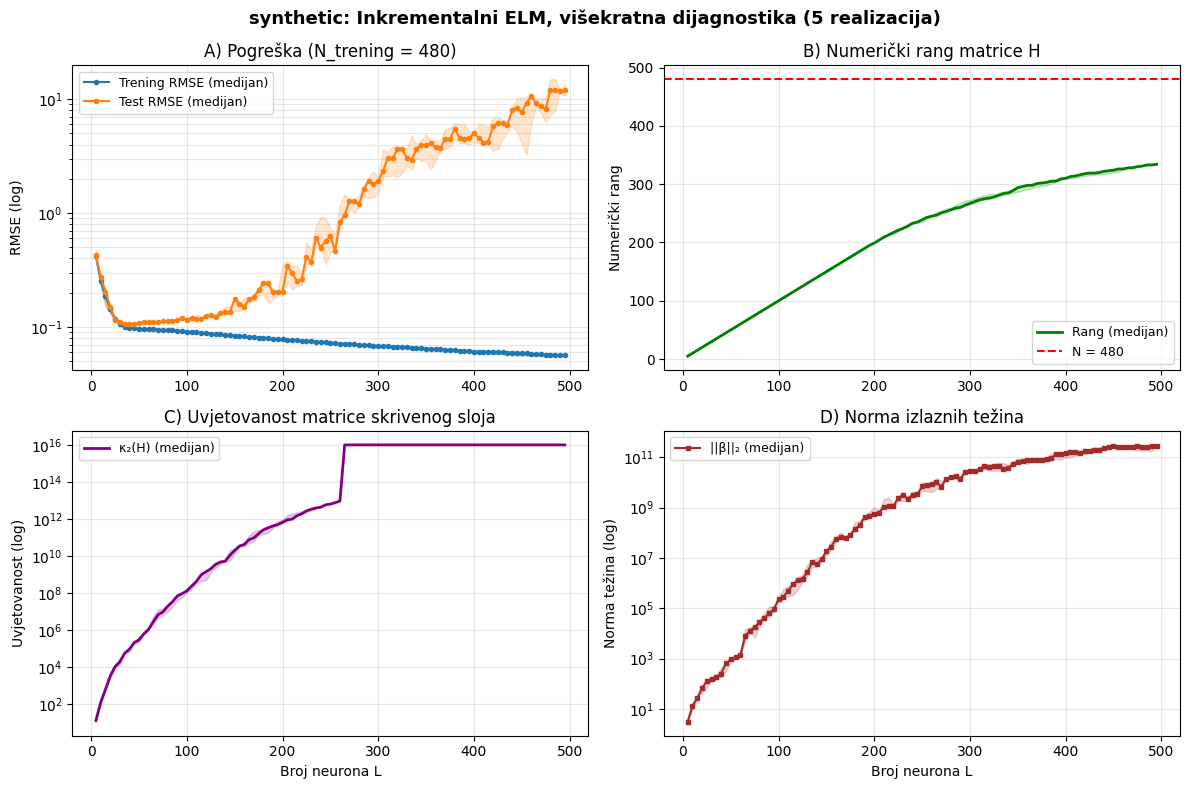


SKUP: diabetes; train=265, validation=88, test=89
[diabetes] Inkrementalni ELM - seed 0 završen.
[diabetes] Inkrementalni ELM - seed 1 završen.
[diabetes] Inkrementalni ELM - seed 2 završen.
[diabetes] Inkrementalni ELM - seed 3 završen.
[diabetes] Inkrementalni ELM - seed 4 završen.

============================== SAŽETAK INKREMENTALNE ANALIZE (Medijani): diabetes ==============================
  L  train_RMSE_median  train_RMSE_q25  train_RMSE_q75  val_RMSE_median  val_RMSE_q25  val_RMSE_q75  test_RMSE_median  test_RMSE_q25  test_RMSE_q75  H_condition_number_median  H_condition_number_q25  H_condition_number_q75  beta_norm_median  beta_norm_q25  beta_norm_q75  rank_H_median  rank_H_q25  rank_H_q75
  5       6.675058e+01    6.573574e+01    6.855047e+01        65.230205     62.876365     66.197186         64.672544      63.556724      65.159601                   2.833630                2.500650                3.028501         46.708613      45.500869      54.993233            5.0     

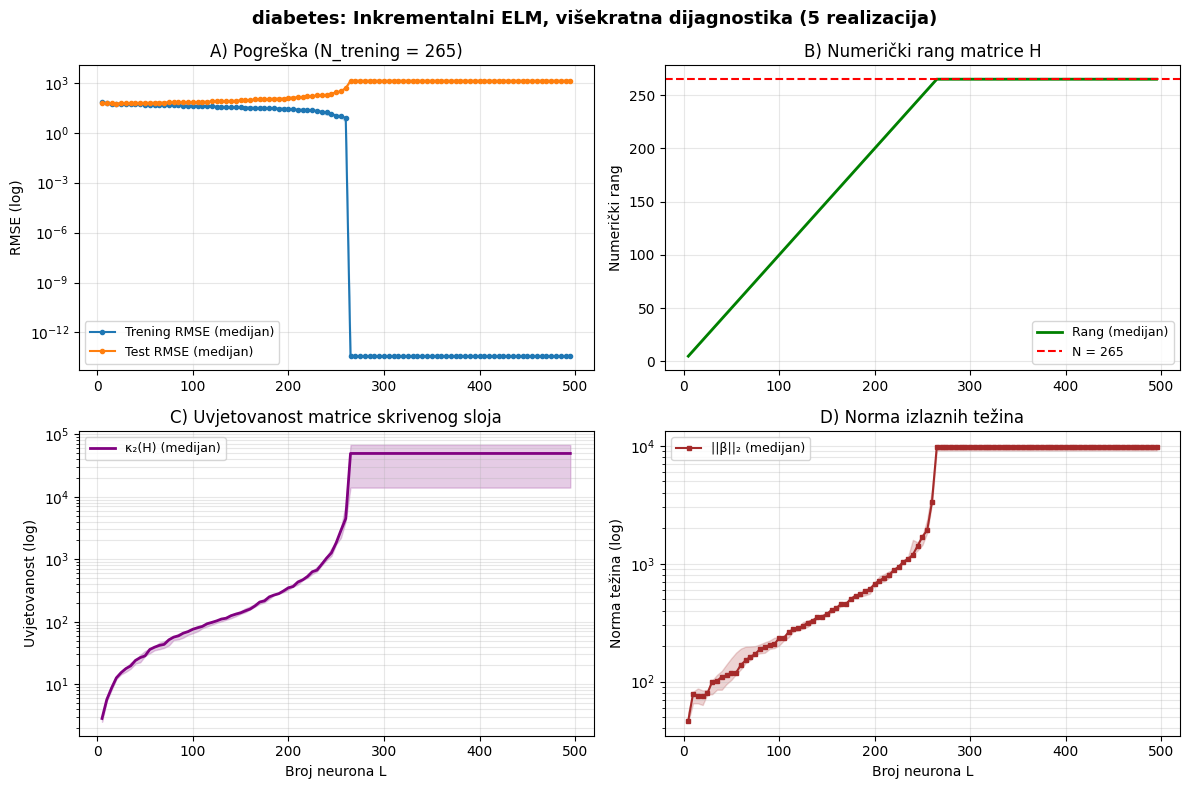

In [ ]:

for name, split in datasets.items():
        print("\n" + "=" * 72)
        print(f"SKUP: {name}; train={len(split.y_train)}, validation={len(split.y_val)}, "
              f"test={len(split.y_test)}")
        print("=" * 72)
        inc_model, inc_path = run_incremental_experiment_repeated(split)

In [ ]:

import gc

def run_unified_experiment(split):
    print(f"\nPokretanje jedinstvenog eksperimenta za skup: {split.name}")

    # 1. Priprema i gašenje Garbage Collectora radi preciznog mjerenja vremena
    gc.collect()
    gc.disable()

    try:
        rows = []
        max_L = max(L_GRID)
        W_all, b_all = generate_hidden_parameters(split.X_train.shape[1], max_L, RANDOM_STATE)

        # Jedinstvena petlja kroz sve vrijednosti L iz grida
        for L in L_GRID:
            for name, lam in [("Standardni ELM", 0.0), ("Ridge ELM", 1e-2)]:

                # Mjerenje vremena pojedinačnog modela već je unutar ELM klase,
                # ali ovdje hvatamo sve rezultate u jednom prolazu.
                model, tr, te, diag = fit_elm_at_L(
                    split, L, RANDOM_STATE, lam=lam, W_all=W_all, b_all=b_all
                )

                # Spajamo sve u jedan rječnik (metrike, dijagnostika, vrijeme)
                rows.append({
                    "dataset": split.name,
                    "model": name,
                    "L": L,
                    # Metrike točnosti
                    "train_RMSE": tr["RMSE"],
                    "test_RMSE": te["RMSE"],
                    "train_MAE": tr["MAE"],
                    "test_MAE": te["MAE"],
                    "train_R2": tr["R2"],
                    "test_R2": te["R2"],
                    # Dijagnostika i numerika
                    "rank_H": diag["rank_H"],
                    "kappa_H": diag["kappa_H"],
                    "beta_norm": diag["beta_norm"],
                    # Vrijeme izvođenja
                    "t_H_seconds": model.t_H,
                    "t_beta_seconds": model.t_beta,
                    "t_total_seconds": model.t_H + model.t_beta,
                })

        # Pretvaranje u jedinstveni DataFrame i spremanje
        df = pd.DataFrame(rows)
        df.to_csv(OUT_DIR / f"{split.name}_unified_experiment.csv", index=False)
        print(f"Spremljeni objedinjeni rezultati u {OUT_DIR / f'{split.name}_unified_experiment.csv'}")

        # --- GENERIRANJE SVEOBUHVATNOG GRAFA (2x2 grid) ---
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))

        # 1. Graf: Testni RMSE ovisno o L
        ax = axes[0, 0]
        for model_name, group in df.groupby("model"):
            ax.plot(group["L"], group["test_RMSE"], marker="o", label=model_name)
        ax.set_title("Testni RMSE")
        ax.set_xlabel("Broj neurona L")
        ax.set_ylabel("RMSE")
        ax.grid(True, alpha=0.3)
        ax.legend()

        # 2. Graf: Broj uvjetovanosti kappa(H) ovisno o L
        ax = axes[0, 1]
        for model_name, group in df.groupby("model"):
            finite_kappa = np.isfinite(group["kappa_H"])
            ax.semilogy(group.loc[finite_kappa, "L"], group.loc[finite_kappa, "kappa_H"], marker="o", label=model_name)
        ax.set_title(r"Uvjetovanost matrice $\kappa_2(H)$")
        ax.set_xlabel("Broj neurona L")
        ax.set_ylabel("Kappa (log skala)")
        ax.grid(True, alpha=0.3)
        ax.legend()

        # 3. Graf: Norma izlaznih težina ||beta|| ovisno o L
        ax = axes[1, 0]
        for model_name, group in df.groupby("model"):
            ax.semilogy(group["L"], np.maximum(group["beta_norm"], 1e-16), marker="o", label=model_name)
        ax.set_title(r"Norma izlaznih težina $\|\beta\|_2$")
        ax.set_xlabel("Broj neurona L")
        ax.set_ylabel("Norma (log skala)")
        ax.grid(True, alpha=0.3)
        ax.legend()

        # 4. Graf: Ukupno vrijeme izvođenja ovisno o L
        ax = axes[1, 1]
        for model_name, group in df.groupby("model"):
            ax.plot(group["L"], group["t_total_seconds"], marker="o", label=model_name)
        ax.set_title("Ukupno vrijeme izvođenja (s)")
        ax.set_xlabel("Broj neurona L")
        ax.set_ylabel("Vrijeme [s]")
        ax.grid(True, alpha=0.3)
        ax.legend()

        fig.suptitle(f"{split.name}: Sveobuhvatna analiza ELM modela", fontsize=16)
        fig.tight_layout()
        fig.savefig(OUT_DIR / f"{split.name}_unified_analysis.png", dpi=160)
        plt.show()
        plt.close(fig)

        return df

    finally:
        # Obavezno vraćanje Garbage Collectora u normalu
        gc.enable()


SKUP: synthetic; train=480, validation=160, test=160

Pokretanje jedinstvenog eksperimenta za skup: synthetic
Spremljeni objedinjeni rezultati u elm_rezultati/synthetic_unified_experiment.csv


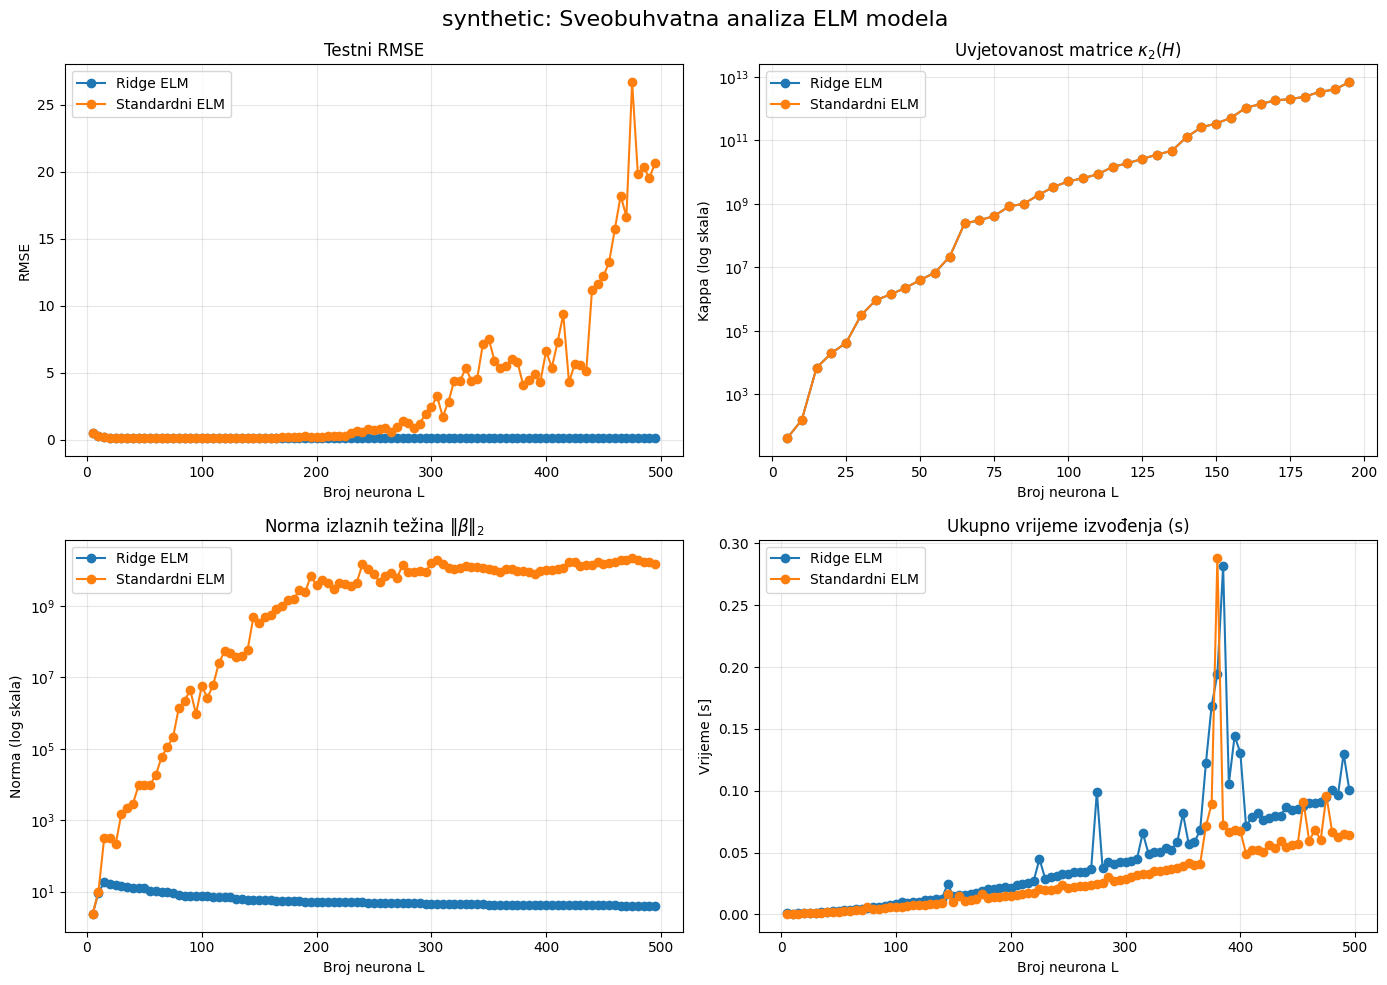


SKUP: diabetes; train=265, validation=88, test=89

Pokretanje jedinstvenog eksperimenta za skup: diabetes
Spremljeni objedinjeni rezultati u elm_rezultati/diabetes_unified_experiment.csv


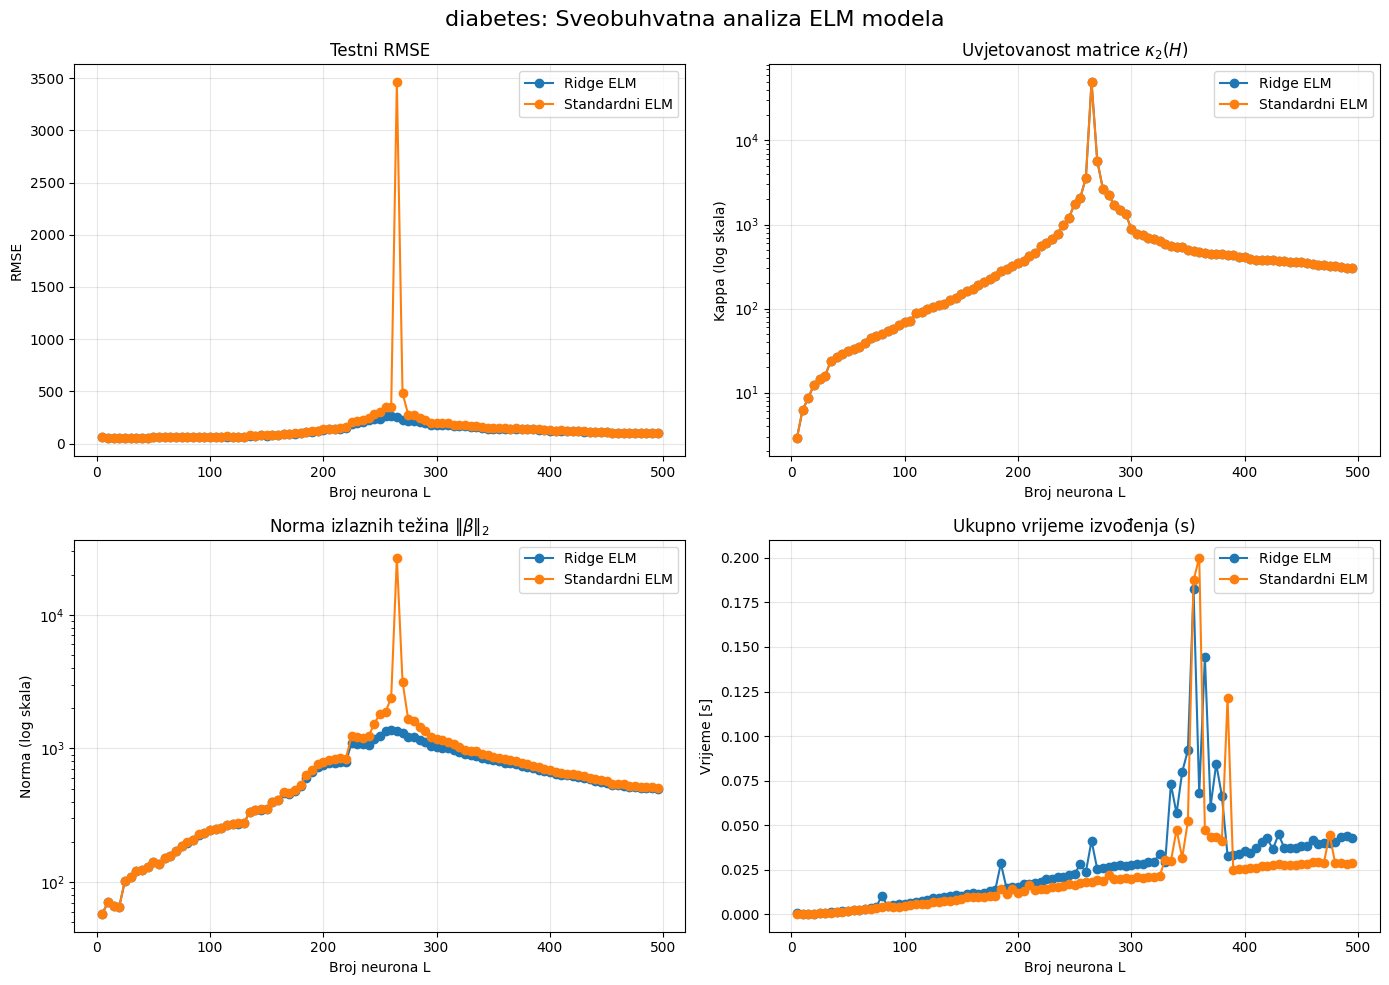

In [ ]:
for name, split in datasets.items():
        print("\n" + "=" * 72)
        print(f"SKUP: {name}; train={len(split.y_train)}, validation={len(split.y_val)}, "
              f"test={len(split.y_test)}")
        print("=" * 72)
        rank_df = run_unified_experiment(split)



SKUP: synthetic; train=480, validation=160, test=160


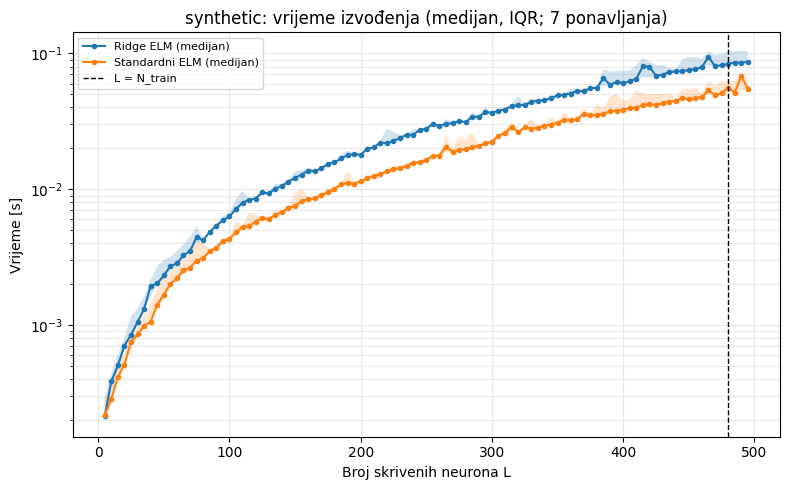


SKUP: diabetes; train=265, validation=88, test=89


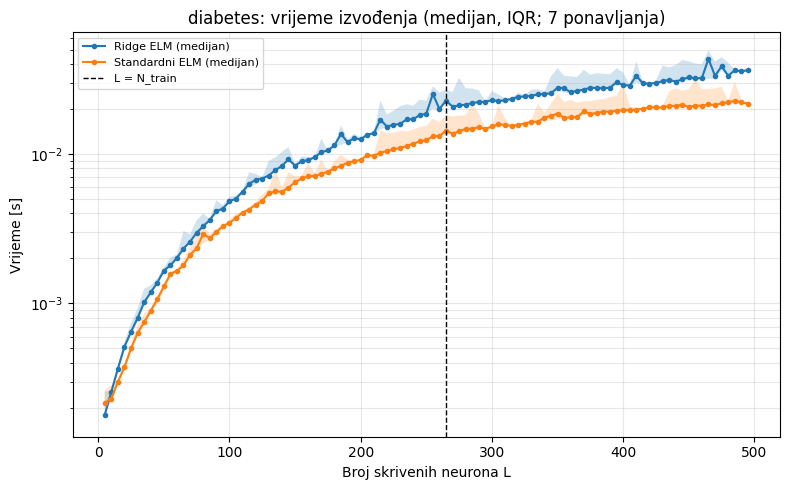

In [ ]:

from threadpoolctl import threadpool_limits  # pip install threadpoolctl
import gc

def run_timing_experiment(split, reps=7, n_threads=1):
    max_L = max(L_GRID)
    W_all, b_all = generate_hidden_parameters(split.X_train.shape[1], max_L, RANDOM_STATE)
    configs = [("Standardni ELM", 0.0), ("Ridge ELM", 1e-2)]
    rows = []

    gc.collect()
    gc.disable()
    try:
        with threadpool_limits(limits=n_threads):
            # warm-up: odbacuje se
            for _ in range(2):
                fit_elm_at_L(split, L_GRID[0], RANDOM_STATE, lam=0.0, W_all=W_all, b_all=b_all)

            # vanjska petlja = ponavljanja, pa se šum raspodijeli po svim L
            for rep in range(reps):
                for L in L_GRID:
                    for name, lam in configs:
                        model, *_ = fit_elm_at_L(
                            split, L, RANDOM_STATE, lam=lam, W_all=W_all, b_all=b_all
                        )
                        rows.append({"dataset": split.name, "model": name, "L": L, "rep": rep,
                                     "t_H": model.t_H, "t_beta": model.t_beta,
                                     "t_total": model.t_H + model.t_beta})
    finally:
        gc.enable()

    raw = pd.DataFrame(rows)
    raw.to_csv(OUT_DIR / f"{split.name}_timing_raw.csv", index=False)

    agg = (raw.groupby(["model", "L"])["t_total"]
              .agg(median="median", min="min",
                   q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75))
              .reset_index())

    fig, ax = plt.subplots(figsize=(8, 5))
    for m, g in agg.groupby("model"):
        ax.plot(g["L"], g["median"], "-o", ms=3, label=f"{m} (medijan)")
        ax.fill_between(g["L"], g["q25"], g["q75"], alpha=0.2)
    if hasattr(split, "X_train"):
        ax.axvline(split.X_train.shape[0], color="k", ls="--", lw=1, label="L = N_train")
    ax.set_yscale("log")
    ax.set_xlabel("Broj skrivenih neurona L"); ax.set_ylabel("Vrijeme [s]")
    ax.set_title(f"{split.name}: vrijeme izvođenja (medijan, IQR; {reps} ponavljanja)")
    ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"{split.name}_timing.png", dpi=160)
    plt.show(); plt.close(fig)
    return raw, agg

for name, split in datasets.items():
        print("\n" + "=" * 72)
        print(f"SKUP: {name}; train={len(split.y_train)}, validation={len(split.y_val)}, "
              f"test={len(split.y_test)}")
        print("=" * 72)
        timing_df = run_timing_experiment(split)

def run_incremental_timing(split, elm_raw, reps=7, n_threads=1):
    """elm_raw = raw DataFrame iz run_timing_experiment (stupci model, L, rep, t_total)."""
    #inicijalizacija i priprema okoline
    max_L = max(L_GRID)
    grid = set(L_GRID)
    rows = []

    gc.collect(); gc.disable()
    try:
      #ograničavamo broj radnih dretvi za numeričke operacije
        with threadpool_limits(limits=n_threads):
            # Pokrećemo jedno probno treniranje modela
            IncrementalELM(max_hidden=min(50, max_L), activation=ACTIVATION,
                           random_state=RANDOM_STATE).fit_path(
                split.X_train, split.y_train, checkpoints={min(50, max_L)}, track_metrics=False)
            #funkcija se ponavlja 'reps' puta
            for rep in range(reps):
                inc = IncrementalELM(max_hidden=max_L, activation=ACTIVATION,
                                     random_state=RANDOM_STATE)
                inc.fit_path(split.X_train, split.y_train,
                             checkpoints=grid, track_metrics=False)
                for it in inc.path:
                    if it["L"] in grid:
                        rows.append({"rep": rep, "L": it["L"], "rank_H": it["rank_H"],
                                     "t_core": it["t_core"], "t_beta": it["t_beta"]})
    finally:
        gc.enable()
    #obradivanje i spremanje sirovih podataka

    raw = pd.DataFrame(rows)
    #spremamo ih u csv datoteku.
    raw.to_csv(OUT_DIR / f"{split.name}_incremental_timing_raw.csv", index=False)
    #racunamo medijan za svaku vrijednost L kroz svih 7 ponavljanja
    inc_med = raw.groupby("L")[["t_core", "t_beta"]].median()

    # obični ELM: medijan po L
    elm_med = (elm_raw[elm_raw.model == "Standardni ELM"]
               .groupby("L")["t_total"].median().reindex(L_GRID))

    cmp = pd.DataFrame({
        "ELM_pojedinacni_fit": elm_med,
        "ELM_suma_grida": elm_med.cumsum(),                        # fitovi za sve L_GRID do L
        "Inkr_do_L_jedan_model": inc_med["t_core"] + inc_med["t_beta"],
        "Inkr_put_do_L_svi_modeli": inc_med["t_core"] + inc_med["t_beta"].cumsum(),
    })
    cmp.to_csv(OUT_DIR / f"{split.name}_timing_comparison.csv")
    #vizualizacija
    fig, ax = plt.subplots(figsize=(8, 5))
    for col, st in [("ELM_pojedinacni_fit", "-o"), ("ELM_suma_grida", "--o"),
                    ("Inkr_do_L_jedan_model", "-s"), ("Inkr_put_do_L_svi_modeli", "--s")]:
        ax.plot(cmp.index, cmp[col], st, ms=3, label=col)
    #crtanje okomite isprekidane linije točno na mjestu gdje je broj neurona jednak broju uzoraka
    ax.axvline(split.X_train.shape[0], color="k", ls=":", lw=1, label="L = N_train")
    ax.set_yscale("log"); ax.set_xlabel("L"); ax.set_ylabel("Vrijeme [s]")
    ax.set_title(f"{split.name}: obični vs inkrementalni ELM ({reps} ponavljanja, medijan)")
    ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=7)
    fig.tight_layout(); fig.savefig(OUT_DIR / f"{split.name}_timing_incremental.png", dpi=160)
    plt.show(); plt.close(fig)
    return raw, cmp


--- Inkrementalni ELM, vrijeme: synthetic ---


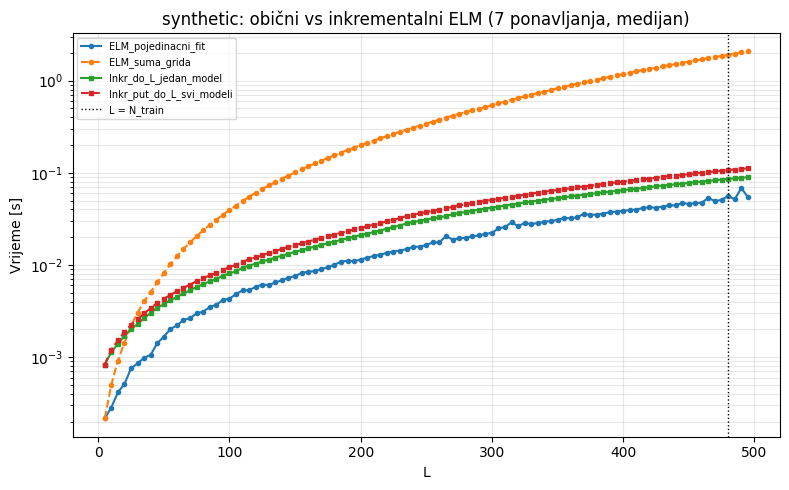

     ELM_pojedinacni_fit  ELM_suma_grida  Inkr_do_L_jedan_model  Inkr_put_do_L_svi_modeli
L                                                                                        
5               0.000217        0.000217               0.000830                  0.000830
55              0.002015        0.010189               0.004136                  0.004740
105             0.004813        0.044188               0.008589                  0.010049
155             0.008186        0.109146               0.014501                  0.017192
205             0.012022        0.211263               0.021884                  0.026279
255             0.017579        0.359130               0.032042                  0.038657
305             0.024883        0.565738               0.043017                  0.052234
355             0.032255        0.854445               0.054250                  0.066492
405             0.039484        1.215169               0.065945                  0.081541
455       

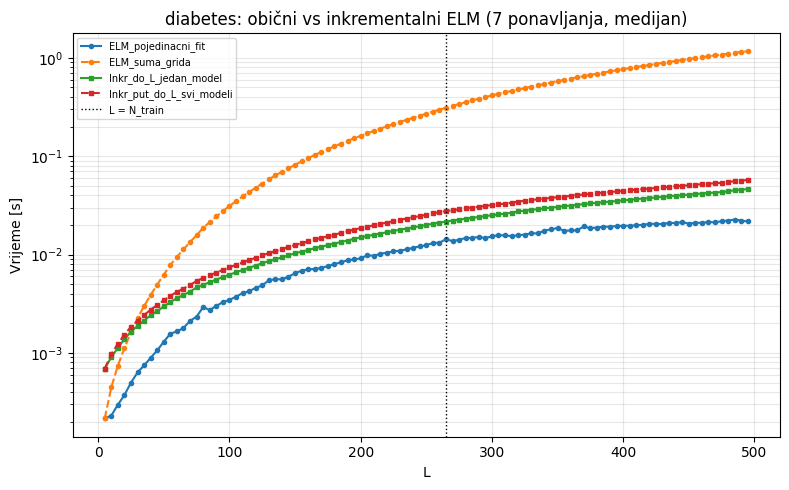

     ELM_pojedinacni_fit  ELM_suma_grida  Inkr_do_L_jedan_model  Inkr_put_do_L_svi_modeli
L                                                                                        
5               0.000216        0.000216               0.000693                  0.000693
55              0.001573        0.007826               0.003291                  0.003805
105             0.003730        0.034862               0.006599                  0.007849
155             0.006853        0.088553               0.010702                  0.013055
205             0.009843        0.170722               0.015420                  0.019225
255             0.013120        0.283450               0.020597                  0.026193
305             0.015771        0.429195               0.025541                  0.032364
355             0.017431        0.596324               0.030983                  0.038895
405             0.019633        0.785296               0.035978                  0.044963
455       

In [ ]:

inc_timing = {}
for name, split in datasets.items():
    print(f"\n--- Inkrementalni ELM, vrijeme: {name} ---")
    raw_elm = pd.read_csv(OUT_DIR / f"{name}_timing_raw.csv")
    raw_inc, cmp = run_incremental_timing(split, raw_elm, reps=7, n_threads=1)
    inc_timing[name] = dict(raw_inc=raw_inc, cmp=cmp)
    print(cmp.iloc[::10].to_string())


In [ ]:
def run_incremental_timing(split, elm_raw, reps=7, n_threads=1):
    """elm_raw = raw DataFrame iz run_timing_experiment (stupci model, L, rep, t_total)."""
    #inicijalizacija i priprema okoline
    max_L = max(L_GRID)
    grid = set(L_GRID)
    rows = []

    gc.collect(); gc.disable()
    try:
      #ograničavamo broj radnih dretvi za numeričke operacije
        with threadpool_limits(limits=n_threads):
            # Pokrećemo jedno probno treniranje modela
            IncrementalELM(max_hidden=min(50, max_L), activation=ACTIVATION,
                           random_state=RANDOM_STATE).fit_path(
                split.X_train, split.y_train, checkpoints={min(50, max_L)}, track_metrics=False)
            #funkcija se ponavlja 'reps' puta
            for rep in range(reps):
                inc = IncrementalELM(max_hidden=max_L, activation=ACTIVATION,
                                     random_state=RANDOM_STATE)
                inc.fit_path(split.X_train, split.y_train,
                             checkpoints=grid, track_metrics=False)
                for it in inc.path:
                    if it["L"] in grid:
                        rows.append({"rep": rep, "L": it["L"], "rank_H": it["rank_H"],
                                     "t_core": it["t_core"], "t_beta": it["t_beta"]})
    finally:
        gc.enable()
    #obradivanje i spremanje sirovih podataka

    raw = pd.DataFrame(rows)
    #spremamo ih u csv datoteku.
    raw.to_csv(OUT_DIR / f"{split.name}_incremental_timing_raw.csv", index=False)
    #racunamo medijan za svaku vrijednost L kroz svih 7 ponavljanja
    inc_med = raw.groupby("L")[["t_core", "t_beta"]].median()

    # obični ELM: medijan po L
    elm_med = (elm_raw[elm_raw.model == "Standardni ELM"]
               .groupby("L")["t_total"].median().reindex(L_GRID))

    cmp = pd.DataFrame({
        "ELM_pojedinacni_fit": elm_med,
        "ELM_suma_gridа": elm_med.cumsum(),                        # fitovi za sve L_GRID do L
        "Inkr_do_L_jedan_model": inc_med["t_core"] + inc_med["t_beta"],
        "Inkr_put_do_L_svi_modeli": inc_med["t_core"] + inc_med["t_beta"].cumsum(),
    })
    cmp.to_csv(OUT_DIR / f"{split.name}_timing_comparison.csv")
    #vizualizacija
    fig, ax = plt.subplots(figsize=(8, 5))
    for col, st in [("ELM_pojedinacni_fit", "-o"), ("ELM_suma_gridа", "--o"),
                    ("Inkr_do_L_jedan_model", "-s"), ("Inkr_put_do_L_svi_modeli", "--s")]:
        ax.plot(cmp.index, cmp[col], st, ms=3, label=col)
    #crtanje okomite isprekidane linije točno na mjestu gdje je broj neurona jednak broju uzoraka
    ax.axvline(split.X_train.shape[0], color="k", ls=":", lw=1, label="L = N_train")
    ax.set_yscale("log"); ax.set_xlabel("L"); ax.set_ylabel("Vrijeme [s]")
    ax.set_title(f"{split.name}: obični vs inkrementalni ELM ({reps} ponavljanja, medijan)")
    ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=7)
    fig.tight_layout(); fig.savefig(OUT_DIR / f"{split.name}_timing_incremental.png", dpi=160)
    plt.show(); plt.close(fig)
    return raw, cmp


--- Inkrementalni ELM, vrijeme: synthetic ---


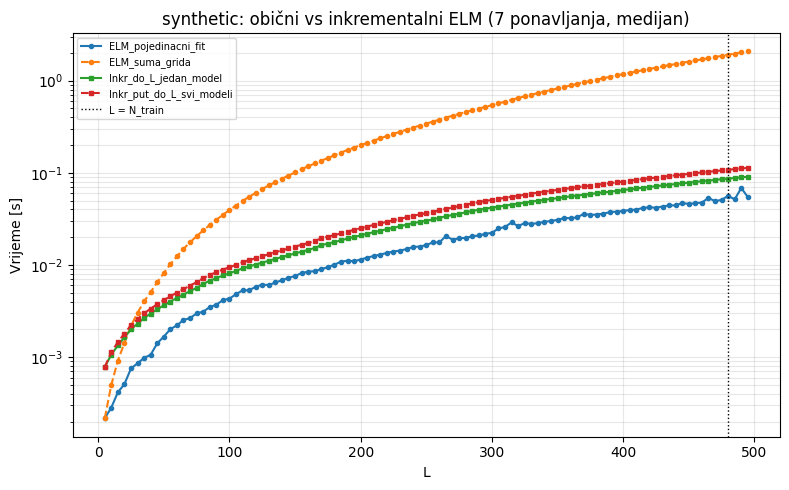

     ELM_pojedinacni_fit  ELM_suma_gridа  Inkr_do_L_jedan_model  Inkr_put_do_L_svi_modeli
L                                                                                        
5               0.000217        0.000217               0.000781                  0.000781
55              0.002015        0.010189               0.004014                  0.004584
105             0.004813        0.044188               0.008639                  0.010056
155             0.008186        0.109146               0.013954                  0.016573
205             0.012022        0.211263               0.021837                  0.026127
255             0.017579        0.359130               0.031175                  0.037642
305             0.024883        0.565738               0.042916                  0.052125
355             0.032255        0.854445               0.054288                  0.066651
405             0.039484        1.215169               0.066335                  0.082114
455       

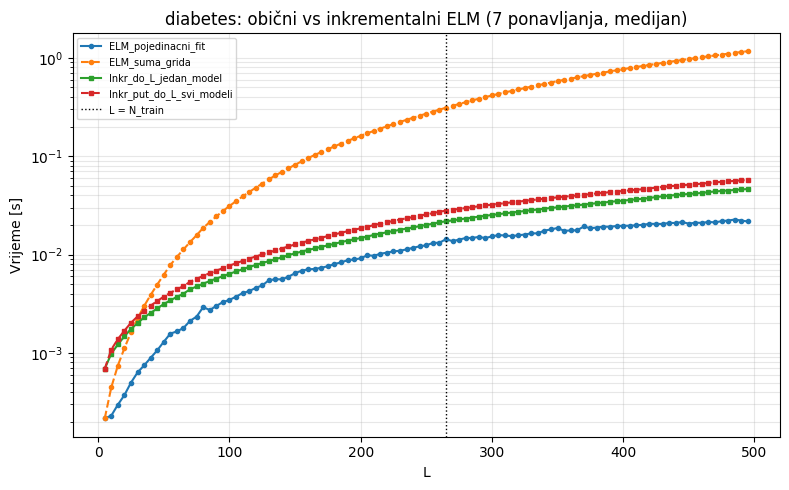

     ELM_pojedinacni_fit  ELM_suma_gridа  Inkr_do_L_jedan_model  Inkr_put_do_L_svi_modeli
L                                                                                        
5               0.000216        0.000216               0.000691                  0.000691
55              0.001573        0.007826               0.003422                  0.004080
105             0.003730        0.034862               0.006736                  0.008175
155             0.006853        0.088553               0.010710                  0.013186
205             0.009843        0.170722               0.015224                  0.019145
255             0.013120        0.283450               0.020550                  0.026310
305             0.015771        0.429195               0.025728                  0.032712
355             0.017431        0.596324               0.030730                  0.038732
405             0.019633        0.785296               0.035812                  0.044862
455       

In [ ]:
import gc
from threadpoolctl import threadpool_limits
from scipy.linalg import solve_triangular   # treba ga IncrementalELM

inc_timing = {}
for name, split in datasets.items():
    print(f"\n--- Inkrementalni ELM, vrijeme: {name} ---")
    raw_elm = pd.read_csv(OUT_DIR / f"{name}_timing_raw.csv")
    raw_inc, cmp = run_incremental_timing(split, raw_elm, reps=7, n_threads=1)
    inc_timing[name] = dict(raw_inc=raw_inc, cmp=cmp)
    print(cmp.iloc[::10].to_string())

In [ ]:
from scipy.optimize import minimize

class ELM_MethodA(ELM):
    """
    Metoda A: Fiksne izlazne težine tijekom optimizacije unutarnjih parametara.
    """
    def fit_optimize(self, X, y, max_iter=100, method='L-BFGS-B'):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if y.ndim == 1:
            y = y.reshape(-1, 1)

        # 1. Inicijalizacija ako već nije napravljena
        if self.W is None or self.b is None:
            self.initialize_hidden_parameters(X.shape[1])

        # 2. Početni izračun i zamrzavanje beta
        H = self._hidden(X)
        if self.lam == 0:
            beta_fixed = np.linalg.lstsq(H, y, rcond=None)[0]
        else:
            U, s, Vt = np.linalg.svd(H, full_matrices=False)
            factors = s / (s * s + self.lam)
            beta_fixed = Vt.T @ (factors[:, None] * (U.T @ y))

        # Pomoćne funkcije za pakiranje/raspakiravanje parametara W i b u 1D vektor
        n_hidden = self.n_hidden
        n_features = X.shape[1]

        def pack(W, b):
            return np.concatenate([W.ravel(), b.ravel()])

        def unpack(params):
            W_flat = params[:n_hidden * n_features]
            b_flat = params[n_hidden * n_features:]
            return W_flat.reshape(n_hidden, n_features), b_flat

        # Ciljna funkcija za optimizaciju W i b uz fiksni beta
        def loss_func(params):
            W_curr, b_curr = unpack(params)
            self.W = W_curr
            self.b = b_curr
            H_curr = self._hidden(X)
            y_pred = H_curr @ beta_fixed
            return 0.5 * np.mean((y_pred - y) ** 2)

        # 3. Optimizacija W i b
        initial_params = pack(self.W, self.b)
        res = minimize(loss_func, initial_params, method=method, options={'maxiter': max_iter})

        # Postavljanje optimalnih parametara
        self.W, self.b = unpack(res.x)

        # 4. Konačni ELM izračun beta na optimiziranim parametrima
        super().fit(X, y, W=self.W, b=self.b)
        return self

In [ ]:
class ELM_MethodB(ELM):
    """
    Metoda B: Varijabilna projekcija - izlazne težine se preračunavaju u svakom koraku.
    """
    def fit_optimize(self, X, y, max_iter=100, method='L-BFGS-B'):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if y.ndim == 1:
            y = y.reshape(-1, 1)

        if self.W is None or self.b is None:
            self.initialize_hidden_parameters(X.shape[1])

        n_hidden = self.n_hidden
        n_features = X.shape[1]

        def pack(W, b):
            return np.concatenate([W.ravel(), b.ravel()])

        def unpack(params):
            W_flat = params[:n_hidden * n_features]
            b_flat = params[n_hidden * n_features:]
            return W_flat.reshape(n_hidden, n_features), b_flat

        # Ciljna funkcija: u svakom koraku izračunava optimalni beta za trenutne W i b
        def loss_func(params):
            W_curr, b_curr = unpack(params)
            self.W = W_curr
            self.b = b_curr
            H_curr = self._hidden(X)

            # Preračunavanje beta za trenutni H
            if self.lam == 0:
                beta_curr = np.linalg.lstsq(H_curr, y, rcond=None)[0]
            else:
                U, s, Vt = np.linalg.svd(H_curr, full_matrices=False)
                factors = s / (s * s + self.lam)
                beta_curr = Vt.T @ (factors[:, None] * (U.T @ y))

            y_pred = H_curr @ beta_curr
            return 0.5 * np.mean((y_pred - y) ** 2)

        initial_params = pack(self.W, self.b)

        # Optimizacija
        res = minimize(loss_func, initial_params, method=method, options={'maxiter': max_iter})

        # Postavljanje optimalnih W i b te konačni fit
        self.W, self.b = unpack(res.x)
        super().fit(X, y, W=self.W, b=self.b)
        return self

In [ ]:
# Generiranje sintetičkih podataka
np.random.seed(42)
X_train = np.random.uniform(-3, 3, size=(500, 2))
y_train = np.sin(X_train[:, 0]) * np.cos(X_train[:, 1]) + np.random.normal(0, 0.05, size=500)

X_test = np.random.uniform(-3, 3, size=(200, 2))
y_test_true = np.sin(X_test[:, 0]) * np.cos(X_test[:, 1])

# 1. Standardni ELM
elm_std = ELM(n_hidden=20, activation="tanh")
elm_std.fit(X_train, y_train)

# 2. Metoda A
elm_a = ELM_MethodA(n_hidden=20, activation="tanh")
elm_a.fit_optimize(X_train, y_train, max_iter=50)

# 3. Metoda B
elm_b = ELM_MethodB(n_hidden=20, activation="tanh")
elm_b.fit_optimize(X_train, y_train, max_iter=50)

# Usporedba testnog RMSE-a prema pravoj funkciji bez šuma
print("Standardni ELM RMSE:", np.sqrt(np.mean((elm_std.predict(X_test) - y_test_true)**2)))
print("Metoda A RMSE:", np.sqrt(np.mean((elm_a.predict(X_test) - y_test_true)**2)))
print("Metoda B RMSE:", np.sqrt(np.mean((elm_b.predict(X_test) - y_test_true)**2)))

Standardni ELM RMSE: 0.7039688583835736
Metoda A RMSE: 0.7050935644349993
Metoda B RMSE: 0.7041751610795196


In [ ]:
def run_timing_experiment(split, reps=7, n_threads=1):
    max_L = max(L_GRID)

    W_all, b_all = generate_hidden_parameters(
        split.X_train.shape[1],
        max_L,
        RANDOM_STATE
    )

    configs = [
        ("Standardni ELM", 0.0),
        ("Ridge ELM", 1e-2)
    ]

    rows = []

    gc.collect()

    with threadpool_limits(limits=n_threads):
        # Zagrijavanje: mjerenja se ne spremaju.
        for _ in range(2):
            fit_elm_at_L(
                split, L_GRID[0], RANDOM_STATE,
                lam=0.0, W_all=W_all, b_all=b_all
            )

        for rep in range(reps):
            for L in L_GRID:
                for name, lam in configs:
                    model, *_ = fit_elm_at_L(
                        split, L, RANDOM_STATE,
                        lam=lam,
                        W_all=W_all,
                        b_all=b_all
                    )

                    rows.append({
                        "dataset": split.name,
                        "model": name,
                        "L": L,
                        "rep": rep,
                        "t_H": model.t_H,
                        "t_beta": model.t_beta,
                        "t_total": model.t_H + model.t_beta
                    })

    raw = pd.DataFrame(rows)

    raw.to_csv(
        OUT_DIR / f"{split.name}_timing_raw.csv",
        index=False
    )

    # Napredna agregacija za t_total, t_H i t_beta
    agg = (
        raw.groupby(["model", "L"])
        .agg(
            t_total_median=("t_total", "median"),
            t_total_q25=("t_total", lambda x: x.quantile(0.25)),
            t_total_q75=("t_total", lambda x: x.quantile(0.75)),
            t_total_iqr=("t_total", lambda x: x.quantile(0.75) - x.quantile(0.25)),
            t_total_minimum=("t_total", "min"),
            t_total_maximum=("t_total", "max"),

            t_H_median=("t_H", "median"),
            t_H_q25=("t_H", lambda x: x.quantile(0.25)),
            t_H_q75=("t_H", lambda x: x.quantile(0.75)),
            t_H_iqr=("t_H", lambda x: x.quantile(0.75) - x.quantile(0.25)),

            t_beta_median=("t_beta", "median"),
            t_beta_q25=("t_beta", lambda x: x.quantile(0.25)),
            t_beta_q75=("t_beta", lambda x: x.quantile(0.75)),
            t_beta_iqr=("t_beta", lambda x: x.quantile(0.75) - x.quantile(0.25))
        )
        .reset_index()
    )

    # Izravnavanje MultiIndex-a u obliku npr. t_total_median

    return raw, agg


def run_incremental_timing(split, reps=7, n_threads=1):
    max_L = max(L_GRID)
    checkpoints = set(L_GRID)
    rows = []

    gc.collect()

    with threadpool_limits(limits=n_threads):
        # Zagrijavanje: rezultat se odbacuje.
        IncrementalELM(
            max_hidden=min(50, max_L),
            activation=ACTIVATION,
            random_state=RANDOM_STATE
        ).fit_path(
            split.X_train,
            split.y_train,
            checkpoints={min(50, max_L)},
            track_metrics=False
        )

        for rep in range(reps):
            inc = IncrementalELM(
                max_hidden=max_L,
                activation=ACTIVATION,
                random_state=RANDOM_STATE
            )

            inc.fit_path(
                split.X_train,
                split.y_train,
                checkpoints=checkpoints,
                track_metrics=False
            )

            for item in inc.path:
                if item["L"] in checkpoints:
                    rows.append({
                        "dataset": split.name,
                        "rep": rep,
                        "L": item["L"],
                        "rank_H": item["rank_H"],
                        "t_core": item["t_core"],
                        "t_beta": item["t_beta"]
                    })

    raw = pd.DataFrame(rows)

    raw.to_csv(
        OUT_DIR / f"{split.name}_incremental_timing_raw.csv",
        index=False
    )

    # Dodavanje IQR-a i kvantila za inkrementalni ELM komponenti
    agg = (
        raw.groupby("L")
        .agg({
            "t_core": [
                ("median", "median"),
                ("q25", lambda x: x.quantile(0.25)),
                ("q75", lambda x: x.quantile(0.75)),
                ("iqr", lambda x: x.quantile(0.75) - x.quantile(0.25))
            ],
            "t_beta": [
                ("median", "median"),
                ("q25", lambda x: x.quantile(0.25)),
                ("q75", lambda x: x.quantile(0.75)),
                ("iqr", lambda x: x.quantile(0.75) - x.quantile(0.25))
            ]
        })
    )

    agg.columns = [f"{col}_{stat}" for col, stat in agg.columns]
    agg = agg.reset_index()

    return raw, agg


In [ ]:
import matplotlib.pyplot as plt

def plot_batch_timing(split, agg, reps=7):
    fig, ax = plt.subplots(figsize=(9, 5.5))

    styles = {
        "Standardni ELM": "-o",
        "Ridge ELM": "-s"
    }

    for model_name, group in agg.groupby("model"):
        group = group.sort_values("L")

        ax.plot(
            group["L"],
            group["t_total_median"],
            styles.get(model_name, "-o"),
            markersize=3,
            linewidth=1.5,
            label=f"{model_name} — medijan"
        )

        ax.fill_between(
            group["L"].to_numpy(),
            group["t_total_q25"].to_numpy(),
            group["t_total_q75"].to_numpy(),
            alpha=0.2
        )

    N_train = len(split.y_train)

    ax.axvline(
        N_train,
        color="black",
        linestyle="--",
        linewidth=1,
        label=r"$L=N_{\mathrm{train}}$"
    )

    ax.set_yscale("log")
    ax.set_xlabel("Broj skrivenih neurona $L$")
    ax.set_ylabel("Vrijeme $t_H+t_\\beta$ [s]")
    ax.set_title(
        f"{split.name}: vrijeme treniranja "
        f"({reps} ponavljanja; medijan i IQR)"
    )

    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)
    fig.tight_layout()

    fig.savefig(
        OUT_DIR / f"{split.name}_timing_batch.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


def plot_incremental_timing(split, agg, reps=7):
    agg = agg.sort_values("L")

    fig, ax = plt.subplots(figsize=(9, 5.5))

    series = [
        ("t_core_median", "t_core_q25", "t_core_q75",
         "Inkrementalni ELM — $t_{core}$", "-o"),
        ("t_beta_median", "t_beta_q25", "t_beta_q75",
         "Inkrementalni ELM — $t_{\\beta}$", "-s")
    ]

    for median_col, q25_col, q75_col, label, style in series:
        ax.plot(
            agg["L"], agg[median_col],
            style, markersize=3, label=label
        )
        ax.fill_between(
            agg["L"].to_numpy(),
            agg[q25_col].to_numpy(),
            agg[q75_col].to_numpy(),
            alpha=0.2
        )

    ax.axvline(
        len(split.y_train),
        color="black",
        linestyle="--",
        linewidth=1,
        label=r"$L=N_{\mathrm{train}}$"
    )

    ax.set_yscale("log")
    ax.set_xlabel("Broj skrivenih neurona $L$")
    ax.set_ylabel("Vrijeme [s]")
    ax.set_title(
        f"{split.name}: vremenske komponente inkrementalnog ELM-a "
        f"({reps} ponavljanja)"
    )

    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)
    fig.tight_layout()

    fig.savefig(
        OUT_DIR / f"{split.name}_timing_incremental.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


def plot_timing_components(split, raw):
    # Dinamičko računanje medijana, q25 i q75 kvantila za pojedinačne komponente t_H i t_beta
    agg = (
        raw.groupby(["model", "L"])[["t_H", "t_beta"]]
        .agg([
            ("median", "median"),
            ("q25", lambda x: x.quantile(0.25)),
            ("q75", lambda x: x.quantile(0.75))
        ])
    )

    # Izravnavanje MultiIndex-a unutar lokalne funkcije za lakše indeksiranje (npr. t_H_median)
    agg.columns = [f"{col}_{stat}" for col, stat in agg.columns]
    agg = agg.reset_index()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

    # Konfiguracija za dva podgrafa (Subplota) s ugrađenim kvantilima
    components = [
        ("t_H_median", "t_H_q25", "t_H_q75", "Vrijeme izračuna matrice $H$"),
        ("t_beta_median", "t_beta_q25", "t_beta_q75", "Vrijeme izračuna izlaznih težina")
    ]

    styles = {
        "Standardni ELM": "-o",
        "Ridge ELM": "-s"
    }

    for ax, (median_col, q25_col, q75_col, title) in zip(axes, components):
        for model_name, group in agg.groupby("model"):
            group = group.sort_values("L")

            # Crtanje linije medijana
            ax.plot(
                group["L"],
                group[median_col],
                styles.get(model_name, "-o"),
                markersize=3,
                label=model_name
            )

            # Crtanje zatamnjenog IQR područja oko komponente
            ax.fill_between(
                group["L"].to_numpy(),
                group[q25_col].to_numpy(),
                group[q75_col].to_numpy(),
                alpha=0.15
            )

        ax.set_yscale("log")
        ax.set_xlabel("Broj skrivenih neurona $L$")
        ax.set_ylabel("Vrijeme [s]")
        ax.set_title(title)
        ax.grid(True, which="both", alpha=0.3)
        ax.legend(fontsize=8)

    fig.suptitle(f"{split.name}: usporedba vremenskih komponenti (medijan i IQR)")
    fig.tight_layout()

    fig.savefig(
        OUT_DIR / f"{split.name}_timing_components.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


Skup: synthetic; train=480, validation=160, test=160


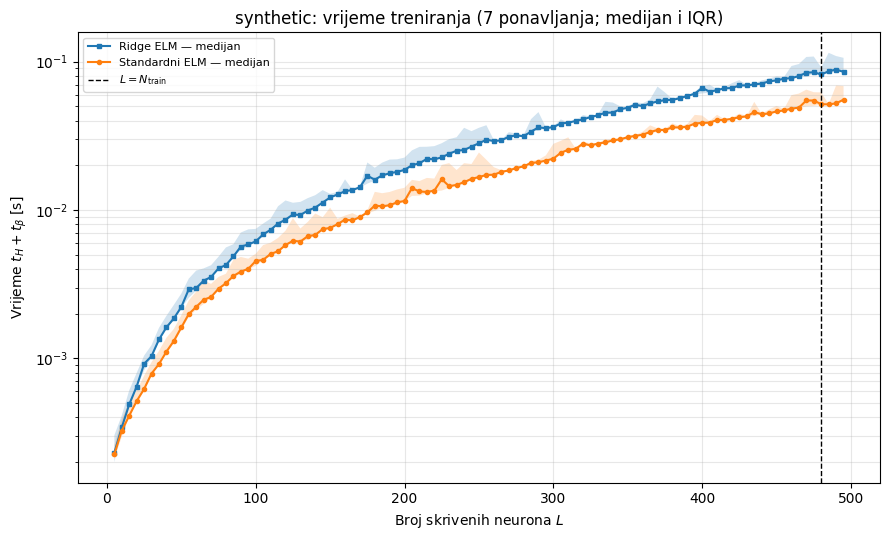

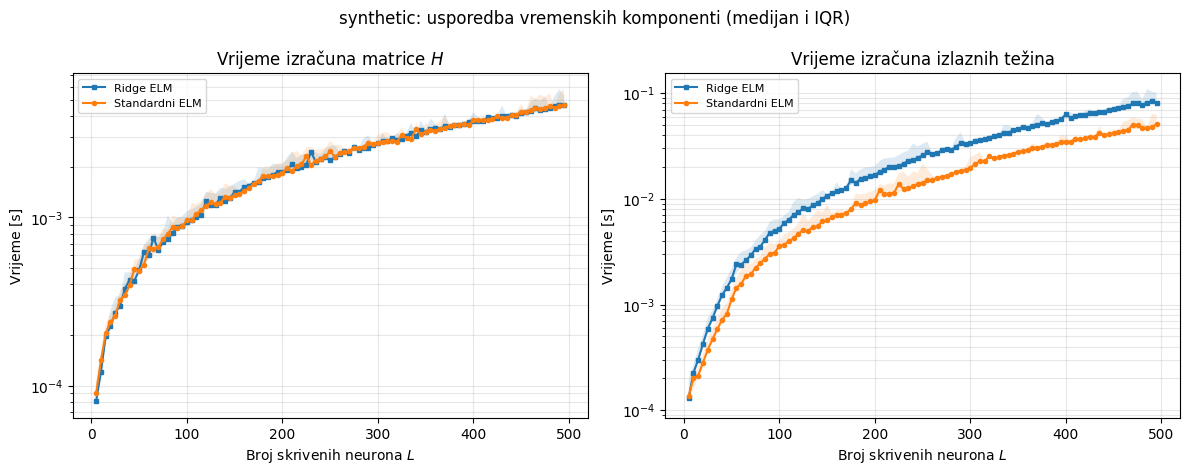

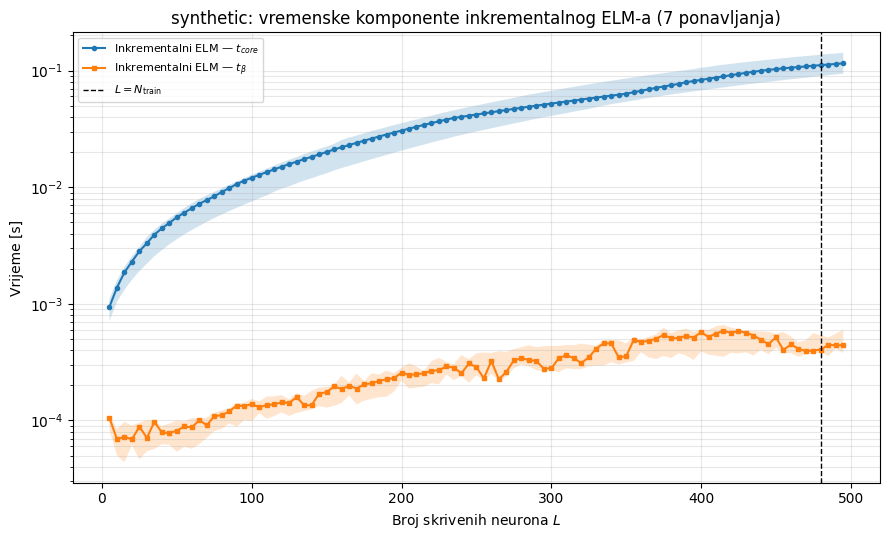

Skup: diabetes; train=265, validation=88, test=89


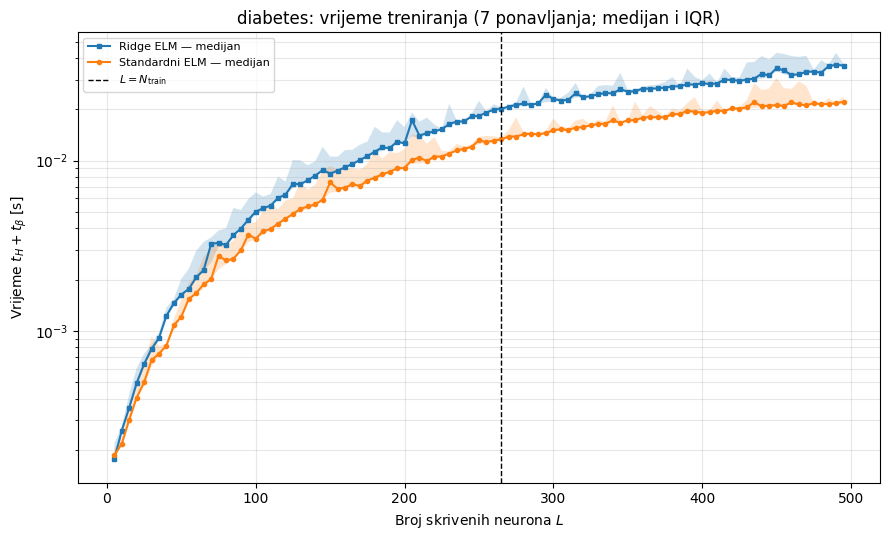

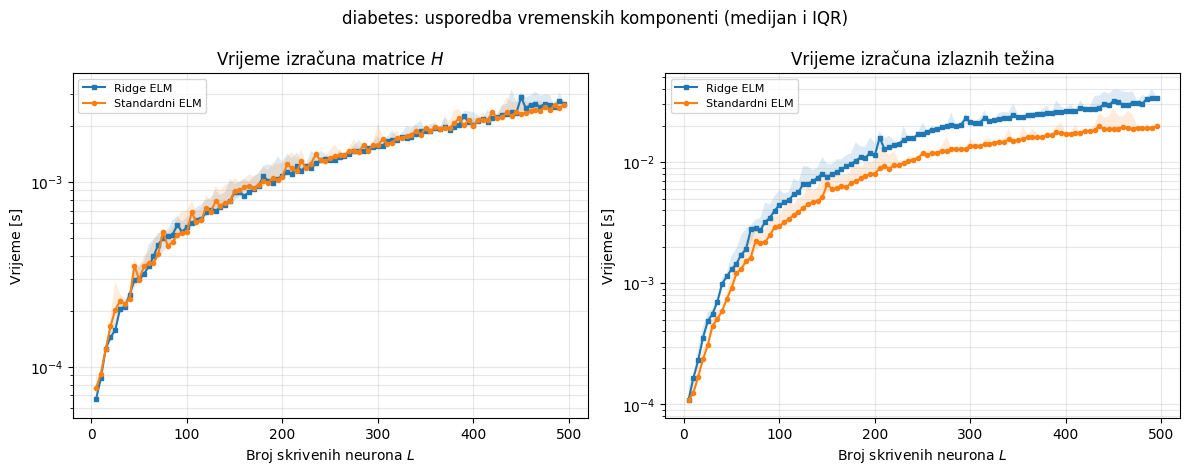

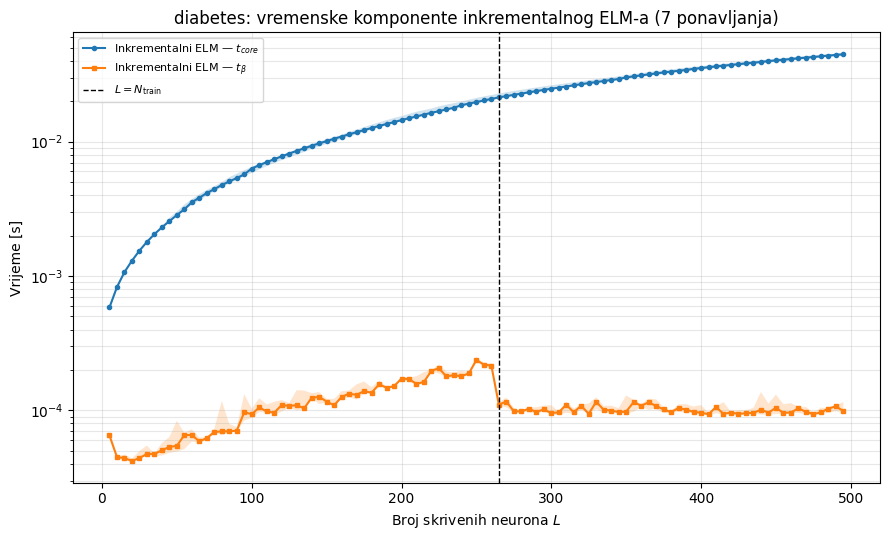

In [ ]:
datasets = load_datasets()

timing_results = {}

for name, split in datasets.items():
    print("=" * 65)
    print(f"Skup: {name}; train={len(split.y_train)}, validation={len(split.y_val)}, test={len(split.y_test)}")
    print("=" * 65)

    # Standardni ELM i Ridge ELM
    batch_raw, batch_agg = run_timing_experiment(split, reps=7, n_threads=1)
    plot_batch_timing(split, batch_agg, reps=7)
    plot_timing_components(split, batch_raw)

    # Inkrementalni ELM
    inc_raw, inc_agg = run_incremental_timing(split, reps=7, n_threads=1)

    # PROMJENA: Prosljeđujemo inc_agg umjesto inc_raw
    plot_incremental_timing(split, inc_agg, reps=7)

    timing_results[name] = {
        "batch_raw": batch_raw,
        "batch_agg": batch_agg,
        "incremental_raw": inc_raw,
        "incremental_agg": inc_agg
    }

In [ ]:
import pandas as pd

df = pd.read_csv("/content/elm_rezultati/synthetic_timing_raw.csv")

def q25(x): return x.quantile(0.25)
def q75(x): return x.quantile(0.75)

summary = (
    df.groupby(["dataset", "model", "L"])[["t_H", "t_beta", "t_total"]]
      .agg(["median", q25, q75])
)

# Spljošti MultiIndex stupce: t_H_median, t_H_q25, ...
summary.columns = [f"{col}_{stat if isinstance(stat, str) else stat.__name__}"
                   for col, stat in summary.columns]
summary = summary.reset_index()

print(summary)
summary.to_csv("synthetic_timing_summary.csv", index=False)

       dataset           model    L  t_H_median   t_H_q25   t_H_q75  \
0    synthetic       Ridge ELM    5    0.000081  0.000080  0.000105   
1    synthetic       Ridge ELM   10    0.000120  0.000116  0.000142   
2    synthetic       Ridge ELM   15    0.000198  0.000180  0.000208   
3    synthetic       Ridge ELM   20    0.000226  0.000211  0.000285   
4    synthetic       Ridge ELM   25    0.000271  0.000255  0.000336   
..         ...             ...  ...         ...       ...       ...   
193  synthetic  Standardni ELM  475    0.004482  0.004467  0.005216   
194  synthetic  Standardni ELM  480    0.004610  0.004443  0.005474   
195  synthetic  Standardni ELM  485    0.004484  0.004396  0.004554   
196  synthetic  Standardni ELM  490    0.004580  0.004534  0.005494   
197  synthetic  Standardni ELM  495    0.004649  0.004582  0.005818   

     t_beta_median  t_beta_q25  t_beta_q75  t_total_median  t_total_q25  \
0         0.000130    0.000119    0.000197        0.000231     0.000200 

#ELM s težinama inicirane nakon rano zaustavljenog treniranja s istom arhitekturom

In [ ]:
import time
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from threadpoolctl import threadpool_limits

OUT_DIR = Path("elm_initialization_experiment")
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
def activation_and_derivative(Z, activation):
    activation = activation.lower()

    if activation == "tanh":
        A = np.tanh(Z)
        dA = 1.0 - A**2

    elif activation in ("sigmoid", "logistic"):
        # Numerički stabilnija sigmoidna funkcija.
        Z_clip = np.clip(Z, -500, 500)
        A = 1.0 / (1.0 + np.exp(-Z_clip))
        dA = A * (1.0 - A)

    elif activation == "relu":
        A = np.maximum(Z, 0.0)
        dA = (Z > 0.0).astype(float)

    else:
        raise ValueError(
            f"Nepodržana aktivacija: {activation}. "
            "Podržane su: tanh, sigmoid i relu."
        )

    return A, dA

$\def\R{\mathbb{R}}\def\Rmat#1#2{\mathbb{R}^{#1 \times #2}}$

# Matematičko objašnjenje funkcije `pretrain_with_early_stopping`

## 1. Postavka problema

Imamo podatke:
- $X_{\text{train}} \in \Rmat{n}{d}$ — ulazni podaci ($n$ primjera, $d$ značajki)
- $y_{\text{train}} \in \Rmat{n}{1}$ — ciljne vrijednosti
- $X_{\text{val}},\, y_{\text{val}}$ — validacijski skup

Model je **jednoslojna nelinearna mreža s linearnim izlazom**:

$$
Z = X W^{T} + \mathbf{1}_nb, \qquad H = \phi(Z), \qquad \hat{y} = H\beta + b_o
$$

gdje su:
- $W \in \Rmat{L}{d}$, $b \in \R^{L}$ — težine i bias **skrivenog sloja** (ono što želimo naučiti)
- $\phi$ — aktivacijska funkcija, s derivacijom $\phi'$
- $\beta \in \Rmat{L}{1}$, $b_o \in \R$ — težine **linearnog izlaznog sloja** (pomoćne, odbacuju se)

Cilj: minimizirati **MSE** na trening skupu, ali koristiti **rani prekid** (early stopping) na validacijskom skupu.

## 2. Funkcija gubitka (MSE)

Za jedan primjer: $\ell = (\hat{y} - y)^2$. Za cijeli skup:

$$
\mathcal{L} = \frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i - y_i)^2 = \frac{1}{n}\|\hat{y} - y\|_2^2
$$

## 3. Forward pass (prolaz unaprijed)

Za svaki primjer $x_i \in \R^{d}$:

$$
z_i = W x_i + b \in \R^{L}, \qquad h_i = \phi(z_i) \in \R^{L}
$$
$$
\hat{y}_i = \beta^{T} h_i + b_o \in \R
$$

U matričnom obliku (za sve primjere odjednom):

$$
Z = XW^{T} + \mathbf{1}b^{T}, \qquad H = \phi(Z), \qquad \hat{y} = H\beta + b_o
$$

## 4. Backpropagation — gradijenti

Neka je $\delta = \hat{y} - y \in \R^{n}$. Tada:

### 4.1 Gradijent po izlaznom sloju

$$
\frac{\partial \mathcal{L}}{\partial \hat{y}} = \frac{2}{n}\,\delta
$$

$$
\nabla_\beta \mathcal{L} = H^{T} \cdot \frac{2}{n}\delta,
\qquad
\nabla_{b_o}\mathcal{L} = \sum_i \frac{2}{n}\delta_i
$$

### 4.2 Gradijent po skrivenom sloju (lančano pravilo)

Gradijent prolazi kroz izlazni sloj natrag u skriveni:

$$
\frac{\partial \mathcal{L}}{\partial H} = \frac{2}{n}\,\delta\,\beta^{T}
$$

Zatim kroz aktivaciju (Hadamardov produkt s derivacijom):

$$
\frac{\partial \mathcal{L}}{\partial Z}
= \left(\frac{2}{n}\,\delta\,\beta^{T}\right) \odot \phi'(Z)
\equiv dZ
$$

### 4.3 Gradijenti po $W$ i $b$

Budući da je $Z = XW^{T} + b$:

$$
\nabla_W \mathcal{L} = dZ^{T} X \in \Rmat{L}{d},
\qquad
\nabla_b \mathcal{L} = \sum_i dZ_i \in \R^{L}
$$

To odgovara kodu:

```python
d_pred = (2.0/n) * error
grad_beta = H.T @ d_pred
grad_output_bias = np.sum(d_pred, axis=0)
dZ = (d_pred @ beta.T) * dH
grad_W = dZ.T @ X_train
grad_b = np.sum(dZ, axis=0)
```

## 5. Gradijentni spust (GD)

Parametri se ažuriraju u smjeru negativnog gradijenta s korakom $\eta$:

$$
W \leftarrow W - \eta\,\nabla_W \mathcal{L}, \qquad
b \leftarrow b - \eta\,\nabla_b \mathcal{L}
$$
$$
\beta \leftarrow \beta - \eta\,\nabla_\beta \mathcal{L}, \qquad
b_o \leftarrow b_o - \eta\,\nabla_{b_o}\mathcal{L}
$$

Ovo je **batch** gradijentni spust (koristi sve $n$ primjera po epohi).

## 6. Validacija i RMSE

Nakon svake epohe računa se RMSE na validacijskom skupu:

$$
\text{RMSE}_{\text{val}}
= \sqrt{\frac{1}{n_{\text{val}}}\sum_{i=1}^{n_{\text{val}}}
\big(\hat{y}^{\text{val}}_i - y^{\text{val}}_i\big)^2}
$$

## 7. Early stopping — matematička logika

Pratimo najbolji $\text{RMSE}_{\text{val}}$ viđen do sada. Definiramo:

- $m^{*} = \min_{t \le T} \text{RMSE}_{\text{val}}(t)$ — najbolja validacijska greška
- $t^{*} = \arg\min_{t} \text{RMSE}_{\text{val}}(t)$ — epoha u kojoj je postignuta
- **patience** $p$: broj epoha bez poboljšanja nakon kojih se zaustavljamo

Zaustavni uvjet:

$$
t - t^{*} \ge p \;\Longrightarrow\; \text{break}
$$

Pohranjuju se parametri iz epohe $t^{*}$ (a ne iz zadnje epohe) — to sprječava **overfitting**.

Funkcija vraća:
- `W`, `b` — težine skrivenog sloja iz najbolje epohe
- `best_epoch` — kada je postignut minimum validacijske greške
- `best_val_rmse_pretraining` — vrijednost te greške
- `pretraining_time` — vrijeme izvršavanja

**$\beta$ i $b_o$ se odbacuju** jer su samo pomoćni linearni izlaz tijekom predtreniranja — cilj je dobiti dobre reprezentacije $H = \phi(XW^{T}+b)$, a ne gotov prediktor.

## 9. Sažetak u jednoj rečenici

Funkcija trenira jednoslojnu nelinearnu mrežu s linearnim izlazom batch-gradijentnim spustom na MSE, ali umjesto parametara zadnje epohe vraća parametre iz epohe s najmanjom validacijskom greškom — čime se matematički ostvaruje **regularizacija ranim zaustavljanjem** i izbjegava overfitting.

In [ ]:
def pretrain_with_early_stopping(
    X_train,
    y_train,
    X_val,
    y_val,
    W_init,
    b_init,
    activation,
    learning_rate=1e-2,
    max_epochs=100,
    patience=10
):
#1.--------------------
    X_train = np.asarray(X_train, dtype=float)
    X_val = np.asarray(X_val, dtype=float)

    y_train = np.asarray(y_train, dtype=float).reshape(-1, 1)
    y_val = np.asarray(y_val, dtype=float).reshape(-1, 1)

    W = np.array(W_init, dtype=float, copy=True)
    b = np.array(b_init, dtype=float, copy=True)

    n = X_train.shape[0]
    L = W.shape[0]

    # Linearni izlazni sloj. Njegove težine treniraju se
    # gradijentnim spustom, ali se poslije odbacuju.
    beta = np.zeros((L, 1), dtype=float)


    best_val_rmse = np.inf
    best_W = W.copy()
    best_b = b.copy()
    best_epoch = 0
    best_beta = beta.copy()

    epochs_without_improvement = 0

    start = time.perf_counter()

    for epoch in range(1, max_epochs + 1):
        # Prolaz unaprijed.
        Z = X_train @ W.T + b
        H, dH = activation_and_derivative(Z, activation)
        pred = H @ beta
        error = pred - y_train

        # Gradijenti MSE-a po svim parametrima.
        d_pred = (2.0 / n) * error
        grad_beta = H.T @ d_pred


        dZ = (d_pred @ beta.T) * dH
        grad_W = dZ.T @ X_train
        grad_b = np.sum(dZ, axis=0)

        # Ažuriranje svih težina.
        W -= learning_rate * grad_W
        b -= learning_rate * grad_b
        beta -= learning_rate * grad_beta


        # Validacija nakon epohe.
        Z_val = X_val @ W.T + b
        H_val, _ = activation_and_derivative(Z_val, activation)
        val_pred = H_val @ beta
        val_rmse = float(np.sqrt(np.mean((val_pred - y_val) ** 2)))

        if val_rmse < best_val_rmse:
            best_val_rmse = val_rmse
            best_W = W.copy()
            best_b = b.copy()
            best_epoch = epoch
            best_beta = beta.copy()

            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    elapsed = time.perf_counter() - start

    return {
        "W": best_W,
        "b": best_b,
        "best_epoch": best_epoch,
        "best_val_rmse_pretraining": best_val_rmse,
        "pretraining_time": elapsed
    }

$\def\R{\mathbb{R}}\def\Rmat#1#2{\mathbb{R}^{#1 \times #2}}$

# Sažetak: što radi `evaluate_elm_hidden_parameters`

## Ukratko

Funkcija **evaluacija je fiksnog skrivenog sloja ELM-a (Extreme Learning Machine)**. Skriveni sloj $(W, b)$ **nije se trenira** — samo se izračuna nelinearna reprezentacija $H = \phi(XW^{T}+b)$ za train/val/test, a zatim se izlazni sloj $\beta$ **riješi analitički** (least squares, tj. Moore–Penrose pseudoinverzija) u jednom koraku. Vraća metrike kvalitete i dijagnostiku numeričke stabilnosti.

## Model

$$
H = \phi(XW^{T} + b), \qquad \hat{y} = H\beta
$$

- $W \in \Rmat{L}{d}$, $b \in \R^{L}$ — **fiksni, slučajno inicijalizirani** parametri skrivenog sloja (ne mijenjaju se)
- $\beta \in \Rmat{L}{1}$ — **jedini parametar koji se uči**, rješenjem najmanjih kvadrata

To je suština ELM-a: skriveni sloj je "random features", a izlaz se rješava linearno.

## Koraci

1. **Forward kroz skriveni sloj** za sva tri skupa:
   $$
   H_{\text{train}},\, H_{\text{val}},\, H_{\text{test}} = \phi(X_{\cdot}W^{T}+b)
   $$
   Mjeri se vrijeme $t_H$.

2. **Analitičko rješenje izlaznog sloja** preko least squares:
   $$
   \beta = \arg\min_{\beta}\ \|H_{\text{train}}\beta - y_{\text{train}}\|_2^{2}
   $$
   Numerički: `np.linalg.lstsq` (SVD-based) → rješenje $\beta = H_{\text{train}}^{+} y_{\text{train}}$.
   Mjeri se vrijeme $t_\beta$.

3. **Predikcije** $\hat{y} = H\beta$ za train, val i test.

4. **RMSE** za svaki skup:
   $$
   \text{RMSE} = \sqrt{\frac{1}{n}\|\hat{y} - y\|_2^{2}}
   $$

5. **Dijagnostika matrice $H_{\text{train}}$**:
   - **rank** — efektivni rang $H$ (koliko linearno neovisnih smjerova reprezentacije postoji)
   - **kondicijski broj**:
     $$
     \kappa(H) = \frac{\sigma_{\max}}{\sigma_{\min}}
     $$
     (ako je $\sigma_{\min} = 0$ ili nema singularnih vrijednosti → $\kappa = \infty$)
   - **norma $\beta$**: $\|\beta\|_2$ — mjera veličine izlaznih težina (velika norma obično znači loše kondicioniran $H$ i nestabilno rješenje)

## Što vraća

| Ključ | Značenje |
|---|---|
| `train_rmse`, `val_rmse`, `test_rmse` | RMSE na svakom skupu |
| `rank_H` | rang matrice $H_{\text{train}}$ |
| `condition_H` | kondicijski broj $H_{\text{train}}$ ($\sigma_{\max}/\sigma_{\min}$) |
| `beta_norm` | $\|\beta\|_2$ |
| `t_H` | vrijeme računanja skrivenog sloja |
| `t_beta` | vrijeme rješavanja least squaresa |
| `t_ls_total` | ukupno vrijeme $t_H + t_\beta$ |

## Zašto je to važno

- **Nema treniranja skrivenog sloja** → vrlo brzo, ali kvaliteta ovisi o tome koliko su slučajni $(W, b)$ dobri.
- **Kondicijski broj i rang** otkrivaju numeričke probleme: ako je $H$ loše kondicioniran ($\kappa$ velik) ili niskog ranga, $\beta$ može eksplodirati, a generalizacija pati.
- **Norma $\beta$** je praktični pokazatelj stabilnosti — velika norma često prati lošu generalizaciju.
- Vrijeme $t_H$ i $t_\beta$ mjeri **gdje se troši računanje**: je li usko grlo forward kroz skriveni sloj ili SVD u least squaresu.
- Usporedba `train/val/test_rmse` pokazuje **overfitting** (mali train, veliki val/test) ili **underfitting** (svi veliki).

## Ključna poanta

> Funkcija ne trenira ništa gradijentnim spustom — **samo evaluira** fiksni slučajni skriveni sloj tako da analitički riješi linearni izlaz ($\beta = H^{+}y$). Vraća RMSE na tri skupa plus dijagnostiku ($\kappa(H)$, rank, $\|\beta\|$) i vremena, kako bi se ocijenilo je li dani skriveni sloj numerički dobar i generalizira li.

In [ ]:
def evaluate_elm_hidden_parameters(
    X_train, y_train, X_val, y_val, X_test, y_test,
    W, b, activation
):
    X_train = np.asarray(X_train, dtype=float)
    X_val = np.asarray(X_val, dtype=float)
    X_test = np.asarray(X_test, dtype=float)

    y_train = np.asarray(y_train, dtype=float).reshape(-1, 1)
    y_val = np.asarray(y_val, dtype=float).reshape(-1, 1)
    y_test = np.asarray(y_test, dtype=float).reshape(-1, 1)

    start = time.perf_counter()
    H_train, _ = activation_and_derivative(
        X_train @ W.T + b, activation
    )
    H_val, _ = activation_and_derivative(
        X_val @ W.T + b, activation
    )
    H_test, _ = activation_and_derivative(
        X_test @ W.T + b, activation
    )
    t_H = time.perf_counter() - start

    start = time.perf_counter()
    beta, _, rank, singular_values = np.linalg.lstsq(
        H_train, y_train, rcond=None
    )
    t_beta = time.perf_counter() - start

    pred_train = H_train @ beta
    pred_val = H_val @ beta
    pred_test = H_test @ beta

    rmse = lambda y, p: float(np.sqrt(np.mean((y - p) ** 2)))

    # Kondicijski broj iz singularnih vrijednosti.
    if singular_values.size == 0 or singular_values[-1] == 0:
        condition_number = np.inf
    else:
        condition_number = float(
            singular_values[0] / singular_values[-1]
        )

    return {
        "train_rmse": rmse(y_train, pred_train),
        "val_rmse": rmse(y_val, pred_val),
        "test_rmse": rmse(y_test, pred_test),
        "rank_H": int(rank),
        "condition_H": condition_number,
        "beta_norm": float(np.linalg.norm(beta)),
        "t_H": t_H,
        "t_beta": t_beta,
        "t_ls_total": t_H + t_beta
    }

$\def\R{\mathbb{R}}\def\Rmat#1#2{\mathbb{R}^{#1 \times #2}}$

# Što pokreću `run_initialization_experiment` i `summarize_initialization_results`

Ove dvije funkcije zajedno provode **kontrolirani eksperiment usporedbe dvaju načina inicijalizacije skrivenog sloja ELM-a** po broju neurona $L$, s više ponavljanja (`reps`) i fiksnim seedovima, te agregiraju rezultate u sažetak.

Eksperiment odgovara na pitanje: **je li vrijedno kratko predtrenirati skriveni sloj gradijentnim spustom prije analitičkog rješavanja izlaza, u usporedbi sa slučajnom inicijalizacijom?**

---

## `run_initialization_experiment(...)`

Glavna eksperimentalna petlja. Za svaki dataset (`split`), za svaki $L$ iz `L_values`, za svako ponavljanje `rep`, trenira i evaluira **dvije metode** i bilježi sve u tablicu.

### 1. Priprema

- `L_values` — ako nije zadan, koristi se globalni `L_GRID`; sortira se i deduplicira
- provjera: svi $L \ge 1$ (inače `ValueError`)
- $L_{\max} = \max(L_{\text{values}})$
- podaci se pretvaraju u `float` i reshapeaju: $X \in \Rmat{n}{d}$, $y \in \Rmat{n}{1}$ za train/val/test
- `gc.collect()` — prisilno čišćenje memorije prije početka

### 2. Ograničavanje broja niti

$$
\texttt{threadpool\_limits}(\text{limits}=n_{\text{threads}})
$$

Osigurava da BLAS/LAPACK operacije (matrično množenje, SVD) koriste **točno $n_{\text{threads}}$ niti** — važno za fer mjerenje vremena i reproducibilnost.

### 3. Dvostruka petlja: `rep` × `L`

Za svaki `rep` u $0, \dots, \text{reps}-1$:

$$
\text{seed} = \text{RANDOM\_STATE} + \text{rep}
$$

**Ključno:** ista inicijalizacija $(W_{\text{all}}, b_{\text{all}})$ koristi se za **obje metode** unutar istog ponavljanja:

$$
(W_{\text{all}}, b_{\text{all}}) = \texttt{generate\_hidden\_parameters}(d, L_{\max}, \text{seed})
$$

Time je usporedba fer — jedina razlika između metoda je predtreniranje, ne slučajnost.

Za svaki $L$ uzima se prefiks:

$$
W_{\text{init}} = W_{\text{all}}[:L], \qquad b_{\text{init}} = b_{\text{all}}[:L]
$$

### 4. Metoda A — `ELM-Random` (bez predtreniranja)

Slučajni skriveni sloj, izlaz analitički:

$$
\texttt{random\_result} = \texttt{evaluate\_elm\_hidden\_parameters}(X_{\text{train}}, y_{\text{train}}, \dots, W_{\text{init}}, b_{\text{init}}, \phi)
$$

Bilježi se redak:

$$
\texttt{method} = \text{"ELM-Random"}, \quad
\texttt{pretraining\_epochs} = 0, \quad
\texttt{pretraining\_time} = 0
$$
$$
\texttt{total\_time} = t_H + t_\beta
$$

### 5. Metoda B — `ELM-EarlyStopping` (kratko predtreniranje)

Prvo se skriveni sloj **kratko trenira** gradijentnim spustom s ranim zaustavljanjem na validacijskom skupu:

$$
\texttt{pretrain} = \texttt{pretrain\_with\_early\_stopping}(X_{\text{train}}, y_{\text{train}}, X_{\text{val}}, y_{\text{val}}, W_{\text{init}}, b_{\text{init}}, \phi, \eta, \text{max\_epochs}, \text{patience})
$$

Zatim se **evaluacija** provodi s predtreniranim parametrima:

$$
\texttt{pretrained\_result} = \texttt{evaluate\_elm\_hidden\_parameters}(\dots, \texttt{pretrain["W"]}, \texttt{pretrain["b"]}, \phi)
$$

Bilježi se redak:

$$
\texttt{method} = \text{"ELM-EarlyStopping"}, \quad
\texttt{pretraining\_epochs} = \texttt{best\_epoch}
$$
$$
\texttt{pretraining\_time} = t_{\text{pretrain}}, \quad
\texttt{total\_time} = t_{\text{pretrain}} + t_H + t_\beta
$$

### 6. Rezultat

Svi redci (obje metode × svi $L$ × svi `rep`) spremaju se u:

$$
\texttt{raw} \in \Rmat{N_{\text{rows}}}{N_{\text{cols}}}
$$

gdje je $N_{\text{rows}} = \text{reps} \cdot |L_{\text{values}}| \cdot 2$, te se zapisuju u CSV:

$$
\texttt{OUT\_DIR / \{split.name\}\_initialization\_raw.csv}
$$

**Vraća:** `raw` — DataFrame sa sirovim rezultatima po ponavljanju.

### Stupci u `raw`

| Stupac | Značenje |
|---|---|
| `dataset` | naziv dataseta |
| `method` | `"ELM-Random"` ili `"ELM-EarlyStopping"` |
| `L` | broj skrivenih neurona |
| `rep` | indeks ponavljanja |
| `pretraining_epochs` | 0 za Random, `best_epoch` za EarlyStopping |
| `pretraining_time` | 0 za Random, vrijeme predtreniranja za EarlyStopping |
| `total_time` | ukupno vrijeme (uključuje predtreniranje) |
| `train_rmse`, `val_rmse`, `test_rmse` | RMSE na tri skupa |
| `rank_H`, `condition_H`, `beta_norm` | dijagnostika skrivenog sloja |
| `t_H`, `t_beta`, `t_ls_total` | vremena po komponentama |

---

## `summarize_initialization_results(raw)`

Agregira sirove rezultate po **`(method, L)`** i računa **median, Q25, Q75** za svaku metriku — robusna statistika umjesto srednje vrijednosti (otporna na outliere).

### 1. Metrike koje se agregiraju

$$
\mathcal{M} = \{\text{train\_rmse}, \text{val\_rmse}, \text{test\_rmse}, \text{total\_time}, \text{pretraining\_time}, \text{condition\_H}, \text{beta\_norm}, \text{rank\_H}\}
$$

### 2. Agregacije

Za svaku metriku $m \in \mathcal{M}$ računaju se tri statistike po grupi:

$$
m_{\text{median}} = \operatorname{median}(m), \qquad
m_{q25} = Q_{0.25}(m), \qquad
m_{q75} = Q_{0.75}(m)
$$

To daje **interkvartilni raspon** $[Q_{0.25}, Q_{0.75}]$ — mjeru varijabilnosti po ponavljanjima.

### 3. Grupiranje

$$
\texttt{summary} = \texttt{raw.groupby}([\text{"method"}, \text{"L"}]).\texttt{agg}(\dots)
$$

Dakle, za svaku kombinaciju `(method, L)` dobiva se jedan redak sa svim medianama i kvartilima.

### 4. Zapis

$$
\texttt{OUT\_DIR / \{dataset\}\_initialization\_summary.csv}
$$

gdje je `dataset` uzet iz prvog retka (`raw['dataset'].iloc[0]`) — pretpostavlja se da `raw` sadrži samo jedan dataset.

**Vraća:** `summary` — DataFrame s agregiranim rezultatima.

### Struktura `summary`

| Stupac | Značenje |
|---|---|
| `method` | metoda |
| `L` | broj neurona |
| `train_rmse_median`, `_q25`, `_q75` | raspodjela train RMSE po ponavljanjima |
| `val_rmse_median`, `_q25`, `_q75` | raspodjela val RMSE |
| `test_rmse_median`, `_q25`, `_q75` | raspodjela test RMSE |
| `total_time_*` | raspodjela ukupnog vremena |
| `pretraining_time_*` | raspodjela vremena predtreniranja |
| `condition_H_*` | raspodjela $\kappa_H$ |
| `beta_norm_*` | raspodjela $\|\beta\|_2$ |
| `rank_H_*` | raspodjela ranga $H$ |

---

## Što eksperiment zapravo mjeri

### Usporedba dviju metoda

Za svaki $L$ i svako ponavljanje:

$$
\text{ELM-Random}: \quad W, b \text{ slučajni} \;\longrightarrow\; \beta = H^{+}y
$$
$$
\text{ELM-EarlyStopping}: \quad W, b \text{ kratko trenirani} \;\longrightarrow\; \beta = H^{+}y
$$

Razlika je **samo u skrivenom sloju** — izlaz se uvijek rješava analitički. Time se izolira doprinos predtreniranja.

### Što se uspoređuje

- **Točnost** — `train_rmse`, `val_rmse`, `test_rmse` (je li predtreniranje poboljšalo generalizaciju?)
- **Cijena** — `total_time`, `pretraining_time` (koliko košta predtreniranje?)
- **Numerička stabilnost** — `condition_H`, `rank_H`, `beta_norm` (je li predtreniranje poboljšalo kondicioniranje $H$?)
- **Skaliranje po $L$** — kako se metrike mijenjaju s brojem neurona

### Zašto `reps` i mediane

Slučajna inicijalizacija unosi varijabilnost. Više ponavljanja s različitim seedovima + mediane daje **robusnu procjenu** tipičnog ponašanja, a kvartili pokazuju **raspršenje** — je li metoda stabilna ili jako ovisi o sreći inicijalizacije.

---

## Sažetak toka

$$
\underbrace{\texttt{generate\_hidden\_parameters}}_{\text{jednom po rep, za } L_{\max}}
\;\longrightarrow\;
\underbrace{(W_{\text{all}}, b_{\text{all}})}_{\text{ista za obje metode}}
$$
$$
\Downarrow
$$
$$
\underbrace{\texttt{evaluate\_elm\_hidden\_parameters}}_{\text{Metoda A: slučajni}}
\quad\text{i}\quad
\underbrace{\texttt{pretrain\_with\_early\_stopping} \to \texttt{evaluate\_elm\_hidden\_parameters}}_{\text{Metoda B: predtrenirani}}
$$
$$
\Downarrow
$$
$$
\underbrace{\texttt{raw}}_{\text{sirovi rezultati}}
\;\xrightarrow{\;\texttt{summarize\_initialization\_results}\;}\;
\underbrace{\texttt{summary}}_{\text{median} + Q_{25} + Q_{75} \text{ po } (\text{method}, L)}
$$

- **`run_initialization_experiment`** — pokreće dvostruku petlju `rep` × `L`, trenira obje metode s **istom** inicijalizacijom, bilježi sve metrike i vremena, sprema `raw` CSV
- **`summarize_initialization_results`** — agregira po `(method, L)` s medianom i kvartilima, sprema `summary` CSV
- **Svrha** — fer usporedba **slučajnog vs. predtreniranog** skrivenog sloja po točnosti, cijeni i numeričkoj stabilnosti, po svakom $L$

In [ ]:
def run_initialization_experiment(
    split,
    L_values=None,
    reps=20,
    n_threads=1,
    learning_rate=1e-2,
    max_epochs=100,
    patience=10
):
    if L_values is None:
        L_values = list(L_GRID)

    L_values = sorted(set(int(L) for L in L_values))

    if min(L_values) < 1:
        raise ValueError("Sve vrijednosti L moraju biti pozitivne.")

    max_L = max(L_values)
    rows = []

    X_train = np.asarray(split.X_train, dtype=float)
    X_val = np.asarray(split.X_val, dtype=float)
    X_test = np.asarray(split.X_test, dtype=float)

    y_train = np.asarray(split.y_train, dtype=float).reshape(-1, 1)
    y_val = np.asarray(split.y_val, dtype=float).reshape(-1, 1)
    y_test = np.asarray(split.y_test, dtype=float).reshape(-1, 1)

    gc.collect()

    with threadpool_limits(limits=n_threads):
        for rep in range(reps):
            seed = RANDOM_STATE + rep

            # Ista inicijalizacija za obje metode unutar ponavljanja.
            W_all, b_all = generate_hidden_parameters(
                X_train.shape[1], max_L, seed
            )

            for L in L_values:
                W_init = W_all[:L].copy()
                b_init = b_all[:L].copy()

                # Metoda A: slučajni ELM.
                random_result = evaluate_elm_hidden_parameters(
                    X_train, y_train, X_val, y_val, X_test, y_test,
                    W_init, b_init, ACTIVATION
                )

                rows.append({
                    "dataset": split.name,
                    "method": "ELM-Random",
                    "L": L,
                    "rep": rep,
                    "pretraining_epochs": 0,
                    "pretraining_time": 0.0,
                    "total_time": (
                        random_result["t_H"] +
                        random_result["t_beta"]
                    ),
                    **random_result
                })

                # Metoda B: kratko treniranje skrivenog sloja.
                pretrain = pretrain_with_early_stopping(
                    X_train, y_train, X_val, y_val,
                    W_init, b_init, ACTIVATION,
                    learning_rate=learning_rate,
                    max_epochs=max_epochs,
                    patience=patience
                )

                pretrained_result = evaluate_elm_hidden_parameters(
                    X_train, y_train, X_val, y_val, X_test, y_test,
                    pretrain["W"], pretrain["b"], ACTIVATION
                )

                rows.append({
                    "dataset": split.name,
                    "method": "ELM-EarlyStopping",
                    "L": L,
                    "rep": rep,
                    "pretraining_epochs": pretrain["best_epoch"],
                    "pretraining_time": pretrain["pretraining_time"],
                    "total_time": (
                        pretrain["pretraining_time"] +
                        pretrained_result["t_H"] +
                        pretrained_result["t_beta"]
                    ),
                    **pretrained_result
                })

    raw = pd.DataFrame(rows)

    raw.to_csv(
        OUT_DIR / f"{split.name}_initialization_raw.csv",
        index=False
    )

    return raw
def summarize_initialization_results(raw):
    metrics = [
        "train_rmse", "val_rmse", "test_rmse",
        "total_time", "pretraining_time",
        "condition_H", "beta_norm", "rank_H"
    ]

    aggregations = {}
    for metric in metrics:
        aggregations[f"{metric}_median"] = (metric, "median")
        aggregations[f"{metric}_q25"] = (
            metric, lambda x: x.quantile(0.25)
        )
        aggregations[f"{metric}_q75"] = (
            metric, lambda x: x.quantile(0.75)
        )

    summary = (
        raw.groupby(["method", "L"])
        .agg(**aggregations)
        .reset_index()
    )

    summary.to_csv(
        OUT_DIR / f"{raw['dataset'].iloc[0]}_initialization_summary.csv",
        index=False
    )

    return summary

In [ ]:

def plot_initialization_analysis(raw, summary):
    dataset_name = raw["dataset"].iloc[0]

    fig, axes = plt.subplots(
        2, 2,
        figsize=(13, 9)
    )

    ax_rmse = axes[0, 0]
    ax_condition = axes[0, 1]
    ax_beta = axes[1, 0]
    ax_difference = axes[1, 1]

    methods = {
        "ELM-Random": "-o",
        "ELM-EarlyStopping": "-s"
    }

    # 1. Testni RMSE
    for method, style in methods.items():
        g = summary[
            summary["method"] == method
        ].sort_values("L")

        if g.empty:
            continue

        x = g["L"].to_numpy()
        median = g["test_rmse_median"].to_numpy()
        q25 = g["test_rmse_q25"].to_numpy()
        q75 = g["test_rmse_q75"].to_numpy()

        ax_rmse.plot(
            x, median, style,
            markersize=4,
            linewidth=1.5,
            label=method
        )

        ax_rmse.fill_between(
            x, q25, q75,
            alpha=0.18
        )

    ax_rmse.set_title("Testna predikcijska pogreška")
    ax_rmse.set_xlabel("Broj skrivenih neurona $L$")
    ax_rmse.set_ylabel("Testni RMSE")
    ax_rmse.grid(True, alpha=0.3)
    ax_rmse.legend(fontsize=8)

    # 2. Kondicijski broj matrice H
    for method, style in methods.items():
        g = summary[
            summary["method"] == method
        ].sort_values("L")

        if g.empty:
            continue

        x = g["L"].to_numpy()
        median = g["condition_H_median"].to_numpy()
        q25 = g["condition_H_q25"].to_numpy()
        q75 = g["condition_H_q75"].to_numpy()

        ax_condition.plot(
            x, median, style,
            markersize=4,
            linewidth=1.5,
            label=method
        )

        ax_condition.fill_between(
            x, q25, q75,
            alpha=0.18
        )

    ax_condition.set_yscale("log")
    ax_condition.set_title("Uvjetovanost matrice skrivenog sloja")
    ax_condition.set_xlabel("Broj skrivenih neurona $L$")
    ax_condition.set_ylabel(r"$\kappa_2(H)$")
    ax_condition.grid(True, which="both", alpha=0.3)
    ax_condition.legend(fontsize=8)

    # 3. Norma izlaznih težina
    for method, style in methods.items():
        g = summary[
            summary["method"] == method
        ].sort_values("L")

        if g.empty:
            continue

        x = g["L"].to_numpy()
        median = g["beta_norm_median"].to_numpy()
        q25 = g["beta_norm_q25"].to_numpy()
        q75 = g["beta_norm_q75"].to_numpy()

        ax_beta.plot(
            x, median, style,
            markersize=4,
            linewidth=1.5,
            label=method
        )

        ax_beta.fill_between(
            x, q25, q75,
            alpha=0.18
        )

    ax_beta.set_yscale("log")
    ax_beta.set_title("Norma izlaznih težina")
    ax_beta.set_xlabel("Broj skrivenih neurona $L$")
    ax_beta.set_ylabel(r"$\|\beta\|_2$")
    ax_beta.grid(True, which="both", alpha=0.3)
    ax_beta.legend(fontsize=8)


    # 4. Uparene razlike testnog RMSE-a
    paired = raw.pivot_table(
        index=["L", "rep"],
        columns="method",
        values="test_rmse"
    ).dropna()

    paired["difference"] = (
        paired["ELM-EarlyStopping"]
        - paired["ELM-Random"]
    )

    difference = (
        paired.groupby("L")["difference"]
        .median()
        .sort_index()
    )

    q25 = (
        paired.groupby("L")["difference"]
        .quantile(0.25)
        .reindex(difference.index)
    )

    q75 = (
        paired.groupby("L")["difference"]
        .quantile(0.75)
        .reindex(difference.index)
    )

    ax_difference.axhline(
        0,
        linestyle="--",
        linewidth=1,
        color="black",
        alpha=0.7
    )

    ax_difference.plot(
        difference.index,
        difference.values,
        "-o",
        markersize=4,
        linewidth=1.5
    )

    ax_difference.fill_between(
        difference.index.to_numpy(),
        q25.to_numpy(),
        q75.to_numpy(),
        alpha=0.2
    )
    ax_difference.set_yscale("log")
    ax_difference.set_title("Razlika ELM_early i ELM_random")
    ax_difference.set_xlabel("Broj skrivenih neurona $L$")
    ax_difference.set_ylabel(r"$RMSE$")
    ax_difference.grid(True, which="both", alpha=0.3)
    ax_difference.legend(fontsize=8)

    fig.suptitle(
        f"{dataset_name}: usporedba predikcijskih i numeričkih svojstava",
        fontsize=13
    )

    fig.tight_layout()

    fig.savefig(
        OUT_DIR / f"{dataset_name}_initialization_analysis.png",
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


In [ ]:

def plot_initialization_time(raw, summary):
    dataset_name = raw["dataset"].iloc[0]

    fig, axes = plt.subplots(
        1, 2,
        figsize=(12, 4.8)
    )

    methods = {
        "ELM-Random": "-o",
        "ELM-EarlyStopping": "-s"
    }

    # 1. Ukupno vrijeme izvršavanja
    ax = axes[0]

    for method, style in methods.items():
        g = summary[
            summary["method"] == method
        ].sort_values("L")

        if g.empty:
            continue

        x = g["L"].to_numpy()

        median = g["total_time_median"].to_numpy()
        q25 = g["total_time_q25"].to_numpy()
        q75 = g["total_time_q75"].to_numpy()

        ax.plot(
            x, median, style,
            markersize=4,
            linewidth=1.5,
            label=method
        )

        ax.fill_between(
            x, q25, q75,
            alpha=0.18
        )

    ax.set_yscale("log")
    ax.set_title("Ukupno vrijeme izvršavanja")
    ax.set_xlabel("Broj skrivenih neurona $L$")
    ax.set_ylabel("Vrijeme [s]")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)

    # 2. Vrijeme predtreniranja
    ax = axes[1]

    g = summary[
        summary["method"] == "ELM-EarlyStopping"
    ].sort_values("L")

    if not g.empty:
        x = g["L"].to_numpy()

        median = g["pretraining_time_median"].to_numpy()
        q25 = g["pretraining_time_q25"].to_numpy()
        q75 = g["pretraining_time_q75"].to_numpy()

        ax.plot(
            x, median, "-s",
            markersize=4,
            linewidth=1.5,
            label="ELM-EarlyStopping"
        )

        ax.fill_between(
            x, q25, q75,
            alpha=0.18
        )

    ax.set_yscale("log")
    ax.set_title("Vrijeme iterativnog predtreniranja")
    ax.set_xlabel("Broj skrivenih neurona $L$")
    ax.set_ylabel("Vrijeme [s]")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)

    fig.suptitle(
        f"{dataset_name}: računalna učinkovitost",
        fontsize=13
    )

    fig.tight_layout()

    fig.savefig(
        OUT_DIR / f"{dataset_name}_initialization_time.png",
        dpi=250,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)



Skup podataka: synthetic


/tmp/ipykernel_7166/2211280051.py:175: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_difference.legend(fontsize=8)


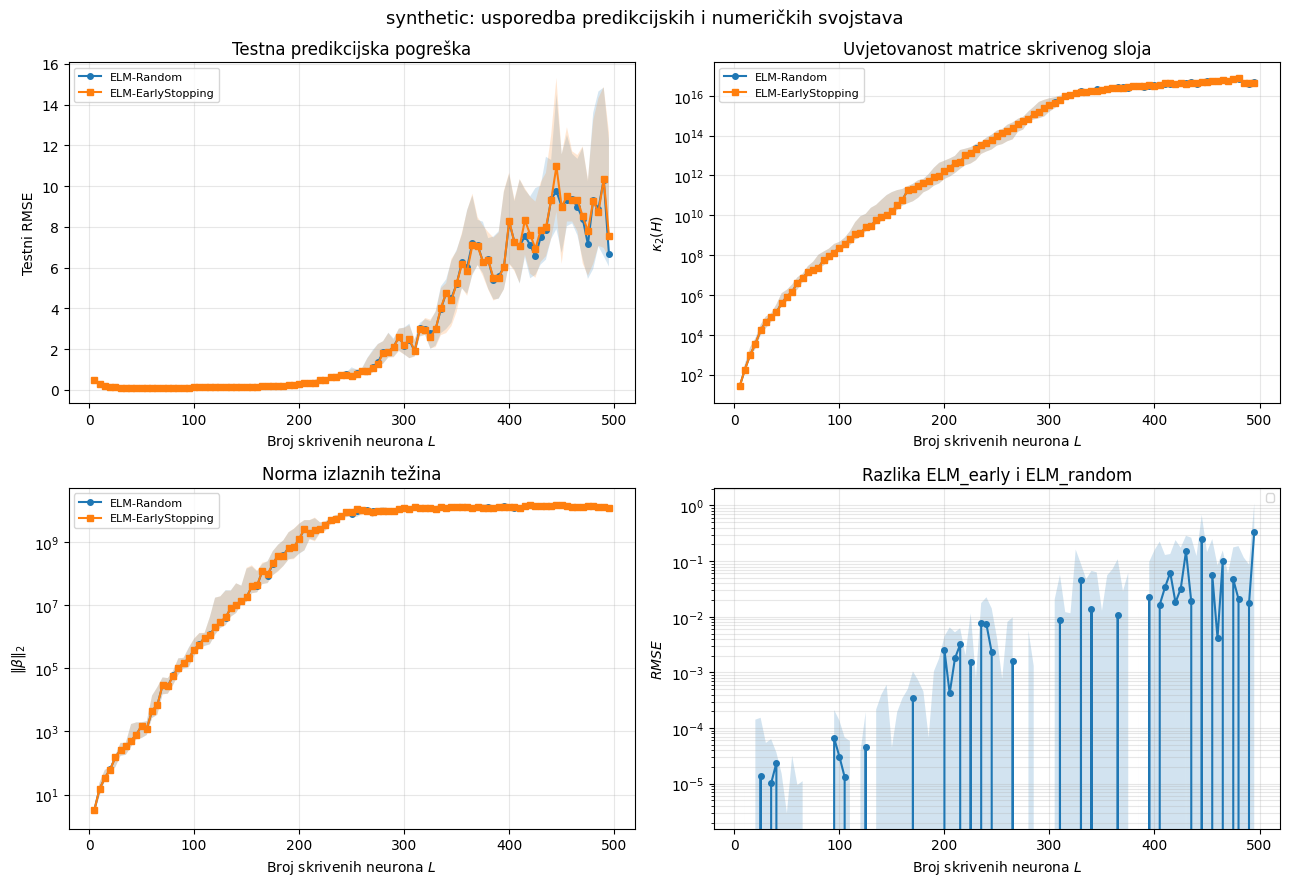

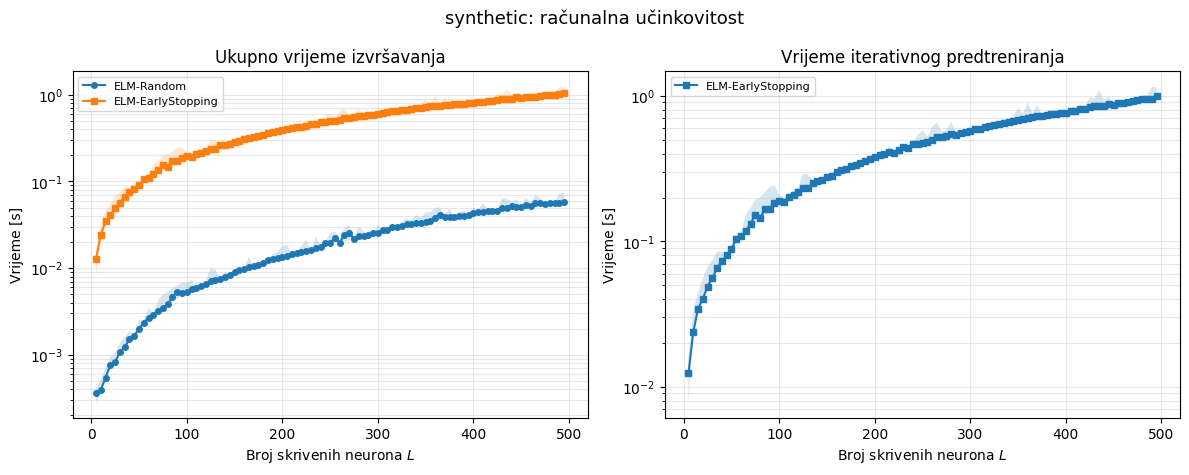


Skup podataka: diabetes


/tmp/ipykernel_7166/2211280051.py:175: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_difference.legend(fontsize=8)


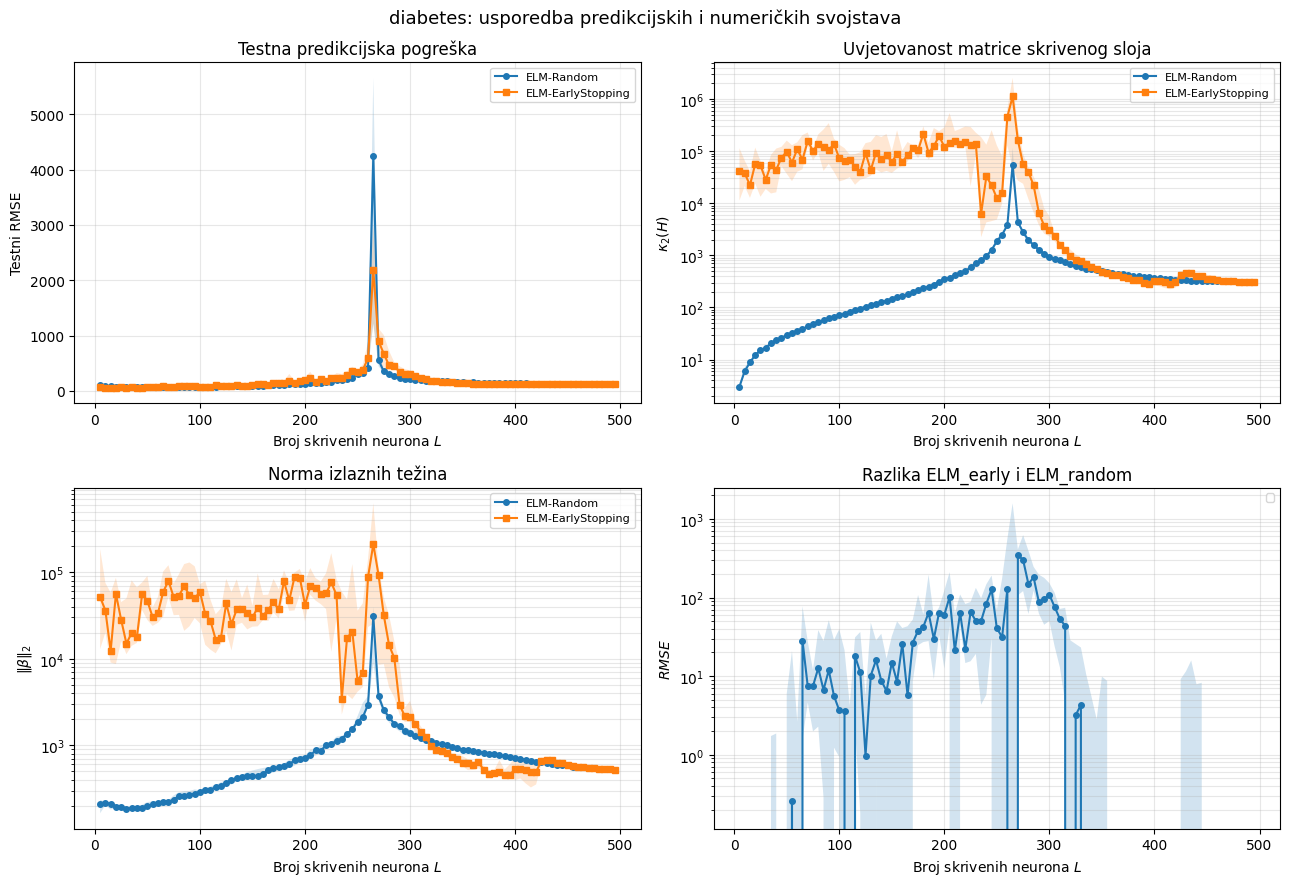

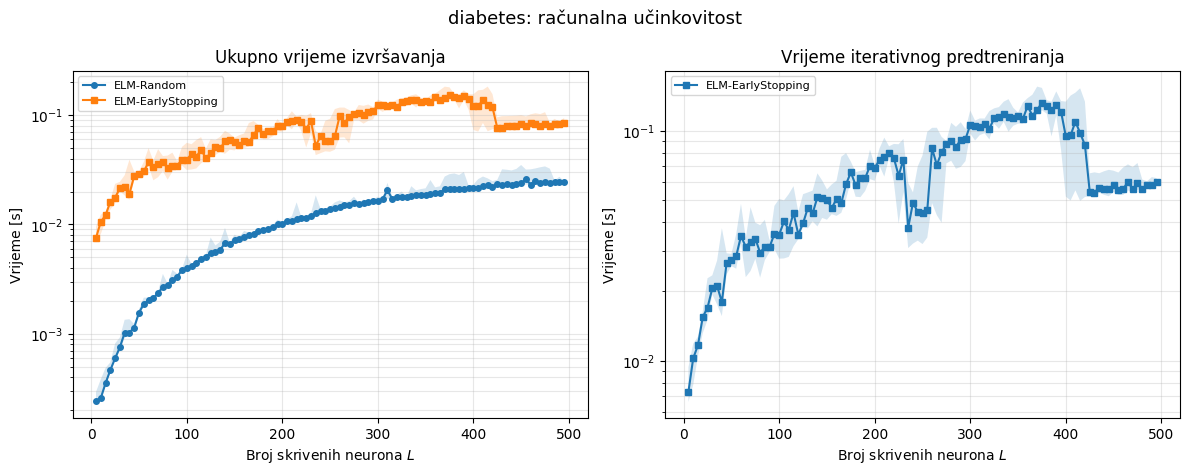

In [ ]:
# Probno pokretanje na manjem broju vrijednosti L.
datasets = load_datasets()

L_TEST = [5, 10, 20, 40, 60]

for name, split in datasets.items():
    print(f"\nSkup podataka: {name}")

    raw = run_initialization_experiment(
    split,
    L_values=L_GRID,
    reps=10,
    n_threads=1
)

    summary = summarize_initialization_results(raw)

    plot_initialization_analysis(raw, summary)
    plot_initialization_time(raw, summary)



In [ ]:

def plot_test_rmse_relative_difference(summary):
    random = (
        summary[summary["method"] == "ELM-Random"]
        .set_index("L")
        .sort_index()
    )

    early = (
        summary[summary["method"] == "ELM-EarlyStopping"]
        .set_index("L")
        .sort_index()
    )

    common_L = random.index.intersection(early.index)

    rmse_random = random.loc[common_L, "test_rmse_median"]
    rmse_early = early.loc[common_L, "test_rmse_median"]

    relative_difference = (
        100 * (rmse_early - rmse_random) / rmse_random
    )

    fig, ax = plt.subplots(figsize=(9, 5.5))

    ax.plot(
        common_L,
        relative_difference,
        marker="o",
        markersize=3,
        linewidth=1.5
    )

    ax.axhline(0, linestyle="--", color="black", linewidth=1)

    ax.set_xlabel("Broj skrivenih neurona $L$")
    ax.set_ylabel("Relativna razlika testnog RMSE-a [%]")
    ax.set_title("Relativna razlika testnog RMSE-a")
    ax.grid(True, alpha=0.3)

    fig.tight_layout()
    plt.show()
    plt.close(fig)


In [ ]:
plot_test_rmse_relative_difference(summary_test)

NameError: name 'summary_test' is not defined